# Heart Failure pipeline 


In [94]:

!pip install GEOparse gseapy matplotlib-venn statsmodels shap xgboost -q
print('Done')

Done


In [95]:

import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve,
                              confusion_matrix, f1_score,
                              accuracy_score, matthews_corrcoef)
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings('ignore')

SAVE = Path('/kaggle/working')

def extract_expression(gse_obj, gse_id):
    gene_map = {}
    for gpl_name, gpl in gse_obj.gpls.items():
        cols = gpl.table.columns.tolist()
        gene_col = None
        for c in ['GENE_SYMBOL','Gene Symbol','gene_symbol','ILMN_Gene','gene_assignment','Gene']:
            if c in cols:
                gene_col = c
                break
        if gene_col:
            ann = gpl.table[['ID', gene_col]].copy()
            if gene_col == 'gene_assignment':
                ann['Gene'] = ann[gene_col].astype(str).str.extract(r'//\s*([A-Z][A-Z0-9]+)\s*//')
            else:
                ann['Gene'] = ann[gene_col].astype(str).str.split(' /// ').str[0].str.strip()
            ann = ann[['ID','Gene']].dropna()
            ann = ann[ann['Gene'].str.strip() != '']
            ann = ann[ann['Gene'] != 'nan']
            gene_map = dict(zip(ann['ID'].astype(str), ann['Gene']))
            print(f'  {gse_id} {gpl_name}: {gene_col} → {len(gene_map)} probes')
    records = {}
    for name, gsm in gse_obj.gsms.items():
        t = gsm.table.copy()
        t['VALUE']  = pd.to_numeric(t['VALUE'], errors='coerce')
        t['ID_REF'] = t['ID_REF'].astype(str)
        if gene_map:
            t['Gene'] = t['ID_REF'].map(gene_map)
            t = t[t['Gene'].notna() & (t['Gene'] != 'nan') & (t['Gene'] != '---')]
            s = t.groupby('Gene')['VALUE'].mean()
        else:
            s = t.set_index('ID_REF')['VALUE']
        records[name] = s
    df = pd.DataFrame(records)
    df = df.apply(pd.to_numeric, errors='coerce')
    missing_frac = df.isna().mean(axis=1)
    n_dropped = int((missing_frac > 0.20).sum())
    df = df[missing_frac <= 0.20]
    df = df.apply(lambda row: row.fillna(row.median()), axis=1)
    df = df.fillna(0)
    print(f'  {gse_id}: dropped {n_dropped} genes (>20% missing), median-imputed the rest')
    df = np.log2(df.clip(lower=0) + 1)
    return df

def get_labels(gse_obj, control_kws):
    labels = []
    for _, gsm in gse_obj.gsms.items():
        text = ' '.join(
            gsm.metadata.get('characteristics_ch1', []) +
            gsm.metadata.get('source_name_ch1', []) +
            gsm.metadata.get('title', [])
        ).lower()
        labels.append(0 if any(k in text for k in control_kws) else 1)
    return labels

def batch_correct(df, batch_labels=None, mod=None, min_var_percentile=10):
    df = df.apply(pd.to_numeric, errors='coerce').fillna(0).astype(float)
    variances = df.var(axis=1)
    var_thresh = np.percentile(variances, min_var_percentile)
    keep = variances > max(var_thresh, 0)
    print(f'  Low-variance filter: removed {(~keep).sum()}/{len(keep)} genes')
    df = df.loc[keep]

    if batch_labels is not None:
        try:
            from combat.pycombat import pycombat
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'pip', 'install', 'combat', '-q'], check=False)
        try:
            from combat.pycombat import pycombat
            corrected = pycombat(df, batch_labels, mod=mod)
            print('  Batch correction: ComBat (disease status protected as covariate)')
            return corrected
        except Exception as e:
            print(f'  ComBat unavailable ({e}) - falling back to per-gene z-score')

    sc = StandardScaler()
    print('  Batch correction: per-gene z-score (fallback)')
    return pd.DataFrame(sc.fit_transform(df.T).T, index=df.index, columns=df.columns)

def detect_outliers(df, labels, name, iqr_mult=3.0):
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2, random_state=42)
    pcs = pca.fit_transform(df.T.values)
    outlier_mask = np.zeros(len(pcs), dtype=bool)
    for dim in range(2):
        q1, q3 = np.percentile(pcs[:, dim], [25, 75])
        iqr = q3 - q1
        lo, hi = q1 - iqr_mult * iqr, q3 + iqr_mult * iqr
        outlier_mask |= (pcs[:, dim] < lo) | (pcs[:, dim] > hi)
    n_out = int(outlier_mask.sum())
    print(f'  {name}: {n_out} outlier sample(s) detected (>{iqr_mult}x IQR on PC1/PC2)')
    if n_out > 0:
        print(f'    Removed: {[c for c,o in zip(df.columns, outlier_mask) if o]}')
    keep_cols   = [c for c, o in zip(df.columns, outlier_mask) if not o]
    keep_labels = [l for l, o in zip(labels, outlier_mask) if not o]
    return df[keep_cols], keep_labels

def run_deg(expr_df, labels, name, fc=0.5, pval=0.05):
    d_idx = [i for i,l in enumerate(labels) if l==1]
    c_idx = [i for i,l in enumerate(labels) if l==0]
    results = []
    for gene in expr_df.index:
        d = expr_df.iloc[:, d_idx].loc[gene].values
        c = expr_df.iloc[:, c_idx].loc[gene].values
        _, p = ttest_ind(d, c, equal_var=False)
        results.append({'Gene': gene, 'log2FC': d.mean()-c.mean(), 'pvalue': p})
    df = pd.DataFrame(results).set_index('Gene')
    _, adj_p, _, _ = multipletests(df['pvalue'].fillna(1), method='fdr_bh')
    df['adj_pvalue'] = adj_p
    df['DEG'] = (df['adj_pvalue'] < pval) & (df['log2FC'].abs() > fc)
    print(f'  {name}: {df["DEG"].sum()} DEGs')
    return df

def lasso_select(X_df, y_arr, name, C=0.05):
    from sklearn.linear_model import LogisticRegression
    sc = StandardScaler()
    Xs = sc.fit_transform(X_df.values)
    lr = LogisticRegression(penalty='l1', solver='liblinear',
                            C=C, max_iter=1000, random_state=42,
                            class_weight='balanced')
    lr.fit(Xs, y_arr)
    coef  = lr.coef_[0]
    mask  = coef != 0
    genes = X_df.columns[mask].tolist()
    coefs = coef[mask]
    print(f'  {name}: {len(genes)} biomarkers')
    return genes, coefs, lr, sc

def run_ml(corrected, genes, name, train_cols, ytr_in, test_cols, yte_in, n_splits=5):
    
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
    from sklearn.svm import SVC
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.naive_bayes import GaussianNB
    from xgboost import XGBClassifier
    from sklearn.model_selection import StratifiedKFold
    import copy

    ytr = np.array(ytr_in)
    yte = np.array(yte_in)

    Xtr_raw = corrected.loc[genes, train_cols].T.values
    Xte_raw = corrected.loc[genes, test_cols].T.values

    sc  = StandardScaler()
    Xtr = sc.fit_transform(Xtr_raw)
    Xte = sc.transform(Xte_raw)

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'Random Forest':       RandomForestClassifier(100, class_weight='balanced', random_state=42),
        'SVM':                 SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
        'XGBoost':             XGBClassifier(eval_metric='logloss', random_state=42, verbosity=0),
        'KNN':                 KNeighborsClassifier(5),
        'Naive Bayes':         GaussianNB(),
        'AdaBoost':            AdaBoostClassifier(n_estimators=100, random_state=42),
        'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42),
    }

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    rows, fitted = [], {}
    for mname, model in models.items():
        
        cv_aucs = []
        for tr_idx, val_idx in skf.split(Xtr, ytr):
            m_cv = copy.deepcopy(model)
            m_cv.fit(Xtr[tr_idx], ytr[tr_idx])
            yp_val = m_cv.predict_proba(Xtr[val_idx])[:, 1]
            cv_aucs.append(roc_auc_score(ytr[val_idx], yp_val))
        cv_aucs = np.array(cv_aucs)

        
        model.fit(Xtr, ytr)
        fitted[mname] = model
        yp  = model.predict_proba(Xte)[:,1]
        ypd = model.predict(Xte)
        auc = roc_auc_score(yte, yp)
        cm  = confusion_matrix(yte, ypd)
        tn,fp,fn,tp = cm.ravel()
        rows.append({'Model':mname,
                     'CV_AUC_mean':round(cv_aucs.mean(),3),
                     'CV_AUC_std':round(cv_aucs.std(),3),
                     'AUC':round(auc,3),
                     'Accuracy':round(accuracy_score(yte,ypd),3),
                     'Sensitivity':round(tp/(tp+fn+1e-9),3),
                     'Specificity':round(tn/(tn+fp+1e-9),3),
                     'F1':round(f1_score(yte,ypd,zero_division=0),3),
                     'MCC':round(matthews_corrcoef(yte,ypd),3)})
        print(f'    {mname}: CV_AUC={cv_aucs.mean():.3f}+/-{cv_aucs.std():.3f}  Test_AUC={auc:.3f}')
    
    df_res = pd.DataFrame(rows).sort_values('CV_AUC_mean', ascending=False).reset_index(drop=True)
    df_res.to_csv(SAVE / f'{name}_ML_results.csv', index=False)
    return df_res, fitted, sc, Xtr, Xte, ytr, yte

print('All functions defined')

All functions defined


In [96]:

import GEOparse

print('[1/2] GSE57338...')
gse_h1 = GEOparse.get_GEO('GSE57338', destdir='/kaggle/working/', silent=True)
print(f'  {len(gse_h1.gsms)} samples')

print('[2/2] GSE5406...')
gse_h2 = GEOparse.get_GEO('GSE5406', destdir='/kaggle/working/', silent=True)
print(f'  {len(gse_h2.gsms)} samples')

print('All downloaded')


[1/2] GSE57338...
  313 samples
[2/2] GSE5406...
  210 samples
All downloaded


In [97]:

print('Extracting...')
h1 = extract_expression(gse_h1, 'GSE57338')
h2 = extract_expression(gse_h2, 'GSE5406')
print(f'h1:{h1.shape} h2:{h2.shape}')


Extracting...
  GSE57338 GPL11532: gene_assignment → 21938 probes
  GSE57338: dropped 0 genes (>20% missing), median-imputed the rest
  GSE5406 GPL96: Gene Symbol → 21225 probes
  GSE5406: dropped 0 genes (>20% missing), median-imputed the rest
h1:(20043, 313) h2:(13237, 210)


In [98]:

labels_h1 = get_labels(gse_h1, ['normal','control','non-fail','nf ','donor'])
labels_h2 = get_labels(gse_h2, ['normal','control','non-fail','nf ','donor'])

common_heart = sorted(h1.index.intersection(h2.index))
print(f'Common — Heart:{len(common_heart)}')

heart_merged = pd.concat([h1.loc[common_heart], h2.loc[common_heart]], axis=1)
heart_merged.columns = heart_merged.columns.astype(str)
heart_labels = labels_h1 + labels_h2

print('Batch correcting...')
heart_corrected = batch_correct(heart_merged)


heart_corrected.to_pickle(SAVE / 'heart_corrected.pkl')
np.save(SAVE / 'heart_labels.npy', np.array(heart_labels))

print(f'Heart:{heart_corrected.shape} | {sum(heart_labels)} HF, {heart_labels.count(0)} Normal')


Common — Heart:11776
Batch correcting...
  Low-variance filter: removed 1178/11776 genes
  Batch correction: per-gene z-score (fallback)
Heart:(10598, 523) | 371 HF, 152 Normal


In [99]:

print('DEG analysis...')
heart_deg = run_deg(heart_corrected, heart_labels, 'Heart Failure')

print(f'HF DEGs:{len(heart_deg[heart_deg["DEG"]])}')

heart_deg.to_csv(SAVE / 'heart_DEG_results.csv')
print('DEG saved')


DEG analysis...
  Heart Failure: 8976 DEGs
HF DEGs:8976
DEG saved


In [100]:

from sklearn.model_selection import train_test_split

heart_y = np.array(heart_labels)

heart_train_cols, heart_test_cols, heart_ytr, heart_yte = train_test_split(
    heart_corrected.columns.tolist(), heart_y, test_size=0.2,
    stratify=heart_y, random_state=42)

print('Train-only DEG (leakage-safe)...')
heart_deg_train = run_deg(heart_corrected[heart_train_cols], list(heart_ytr), 'HF (train-only)')

heart_degs_train = heart_deg_train[heart_deg_train['DEG']].index.tolist()

print('LASSO (train-only)...')
heart_X_train = heart_corrected.loc[heart_degs_train, heart_train_cols].T

hf_genes, hf_coefs, _, _ = lasso_select(heart_X_train, heart_ytr, 'Heart Failure')

np.save(SAVE / 'hf_genes.npy', np.array(hf_genes, dtype=object))
print(f'HF:{len(hf_genes)} genes')
print(f'Train/test split fixed here and reused everywhere below (no re-splitting).')


Train-only DEG (leakage-safe)...
  HF (train-only): 8946 DEGs
LASSO (train-only)...
  Heart Failure: 20 biomarkers
HF:20 genes
Train/test split fixed here and reused everywhere below (no re-splitting).


In [101]:

print('ML — Heart Failure (5-fold CV, leakage-safe)...')
hf_results, hf_models, hf_sc, hf_Xtr, hf_Xte, hf_ytr, hf_yte = run_ml(
    heart_corrected, hf_genes, 'HeartFailure',
    heart_train_cols, heart_ytr, heart_test_cols, heart_yte)
print('\n Heart Failure Results (ranked by 5-fold CV AUC)')
print(hf_results.to_string(index=False))

ML — Heart Failure (5-fold CV, leakage-safe)...
    Logistic Regression: CV_AUC=0.982+/-0.021  Test_AUC=0.993
    Random Forest: CV_AUC=0.987+/-0.016  Test_AUC=0.993
    SVM: CV_AUC=0.981+/-0.021  Test_AUC=0.993
    XGBoost: CV_AUC=0.984+/-0.015  Test_AUC=0.983
    KNN: CV_AUC=0.984+/-0.015  Test_AUC=0.958
    Naive Bayes: CV_AUC=0.990+/-0.013  Test_AUC=0.991
    AdaBoost: CV_AUC=0.985+/-0.016  Test_AUC=0.978
    Gradient Boosting: CV_AUC=0.987+/-0.012  Test_AUC=0.990

 Heart Failure Results (ranked by 5-fold CV AUC)
              Model  CV_AUC_mean  CV_AUC_std   AUC  Accuracy  Sensitivity  Specificity    F1   MCC
        Naive Bayes        0.990       0.013 0.991     0.943        0.959        0.903 0.959 0.863
      Random Forest        0.987       0.016 0.993     0.971        1.000        0.903 0.980 0.932
  Gradient Boosting        0.987       0.012 0.990     0.962        1.000        0.871 0.974 0.909
           AdaBoost        0.985       0.016 0.978     0.943        0.973        

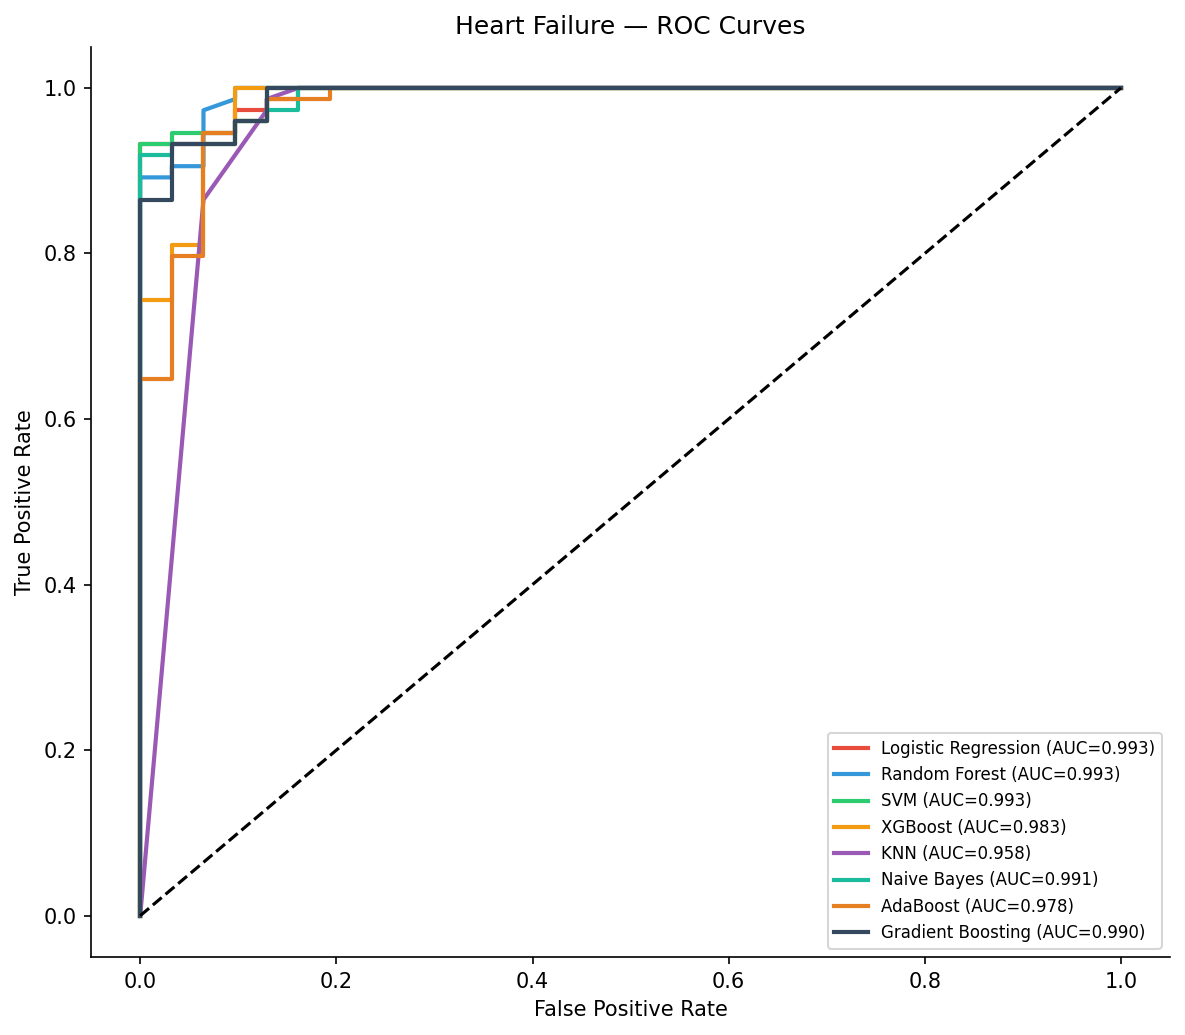

ROC_curves_HF.svg saved


In [102]:

COLORS = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22','#34495e']

for models, Xte, yte, title, fname in [
    (hf_models, hf_Xte, hf_yte, 'Heart Failure', 'ROC_curves_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(8,7))
    for (mname, model), col in zip(models.items(), COLORS):
        yp = model.predict_proba(Xte)[:,1]
        fpr, tpr, _ = roc_curve(yte, yp)
        auc = roc_auc_score(yte, yp)
        ax.plot(fpr, tpr, color=col, lw=2, label=f'{mname} (AUC={auc:.3f})')
    ax.plot([0,1],[0,1],'k--', lw=1.5)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{title} — ROC Curves')
    ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f'{fname} saved')


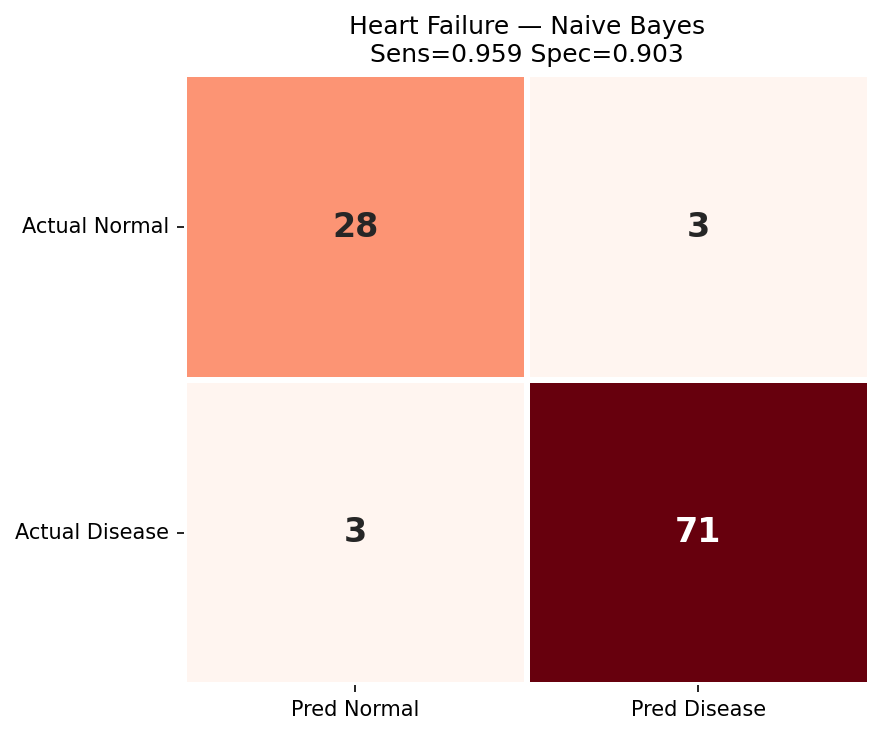

Confusion_Matrix_HF.svg saved


In [103]:

hf_best_name = hf_results.iloc[0]['Model']

for models, Xte, yte, bname, title, cmap, fname in [
    (hf_models, hf_Xte, hf_yte, hf_best_name, 'Heart Failure', 'Reds', 'Confusion_Matrix_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(6,5))
    ypd = models[bname].predict(Xte)
    cm  = confusion_matrix(yte, ypd)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                linewidths=2, linecolor='white',
                annot_kws={'size':16,'weight':'bold'}, cbar=False)
    ax.set_xticklabels(['Pred Normal','Pred Disease'], fontsize=10)
    ax.set_yticklabels(['Actual Normal','Actual Disease'], fontsize=10, rotation=0)
    tn,fp,fn,tp = cm.ravel()
    ax.set_title(f'{title} — {bname}\nSens={tp/(tp+fn):.3f} Spec={tn/(tn+fp):.3f}')

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f'{fname} saved')


Background dataset has 105 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=105 when initializing the masker.


SHAP — Heart Failure...


PermutationExplainer explainer: 106it [00:27,  2.39it/s]                         


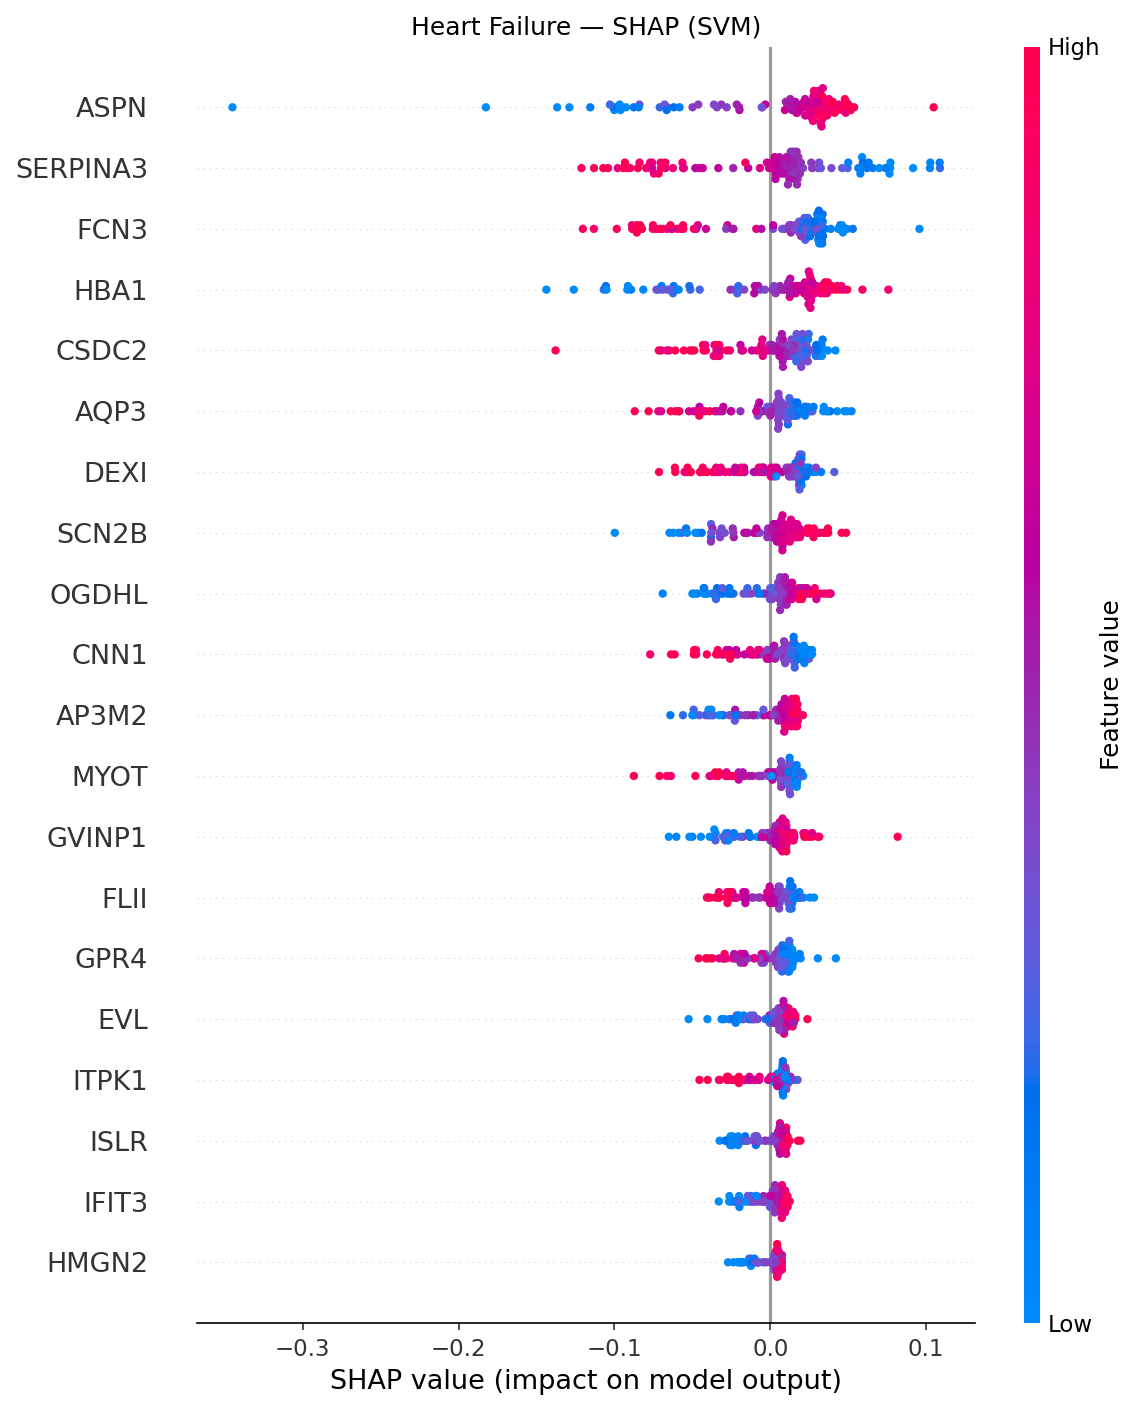

SHAP_beeswarm_HF.svg saved

HF Top genes:
  ASPN: 0.0460
  SERPINA3: 0.0432
  FCN3: 0.0392
  HBA1: 0.0354
  CSDC2: 0.0241
  AQP3: 0.0225
  DEXI: 0.0209
  SCN2B: 0.0205
  OGDHL: 0.0191
  CNN1: 0.0182


In [104]:

import shap

print('SHAP — Heart Failure...')
explainer_hf = shap.Explainer(hf_models['SVM'].predict_proba, hf_Xte,
                               feature_names=hf_genes)
shap_hf = explainer_hf(hf_Xte)


plt.figure(figsize=(10, 10))
shap.plots.beeswarm(shap_hf[:, :, 1], max_display=20, show=False)
plt.title('Heart Failure — SHAP (SVM)', fontsize=12)
plt.tight_layout()
plt.savefig(SAVE / 'SHAP_beeswarm_HF.svg', format='svg', bbox_inches='tight')
plt.show()


hf_imp = np.abs(shap_hf.values[:,:,1]).mean(axis=0)

pd.DataFrame({'Gene': hf_genes, 'SHAP': hf_imp})\
  .sort_values('SHAP', ascending=False)\
  .to_csv(SAVE / 'hf_shap_importance.csv', index=False)

print('SHAP_beeswarm_HF.svg saved')
print('\nHF Top genes:')
for g,v in sorted(zip(hf_genes, hf_imp), key=lambda x:x[1], reverse=True)[:10]:
    print(f'  {g}: {v:.4f}')


Background dataset has 105 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=105 when initializing the masker.


SHAP for SVM ...


PermutationExplainer explainer: 106it [00:27,  2.42it/s]                         
Background dataset has 105 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=105 when initializing the masker.


SHAP for Naive Bayes ...


Background dataset has 105 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=105 when initializing the masker.


SHAP for Random Forest ...


PermutationExplainer explainer: 106it [00:23,  2.63it/s]                         


SVM ranking vs saved hf_shap_importance.csv: Spearman rho = 0.998

 Agreement between models
    Model_A       Model_B  Spearman_rho      p_value Top5_overlap Top10_overlap
        SVM   Naive Bayes         0.008 9.750000e-01          3/5          3/10
        SVM Random Forest         0.078 7.430000e-01          3/5          5/10
Naive Bayes Random Forest         0.889 1.650000e-07          4/5          8/10

 Top 20 genes per model (rank, gene, mean |SHAP|)
 Rank SVM_gene  SVM_meanAbsSHAP Naive Bayes_gene  Naive Bayes_meanAbsSHAP Random Forest_gene  Random Forest_meanAbsSHAP
    1     ASPN           0.0460             FCN3                   0.0388               FCN3                     0.0442
    2 SERPINA3           0.0428         SERPINA3                   0.0347              HMGN2                     0.0433
    3     FCN3           0.0385             ASPN                   0.0328               ASPN                     0.0432
    4     HBA1           0.0353            AP3M2        

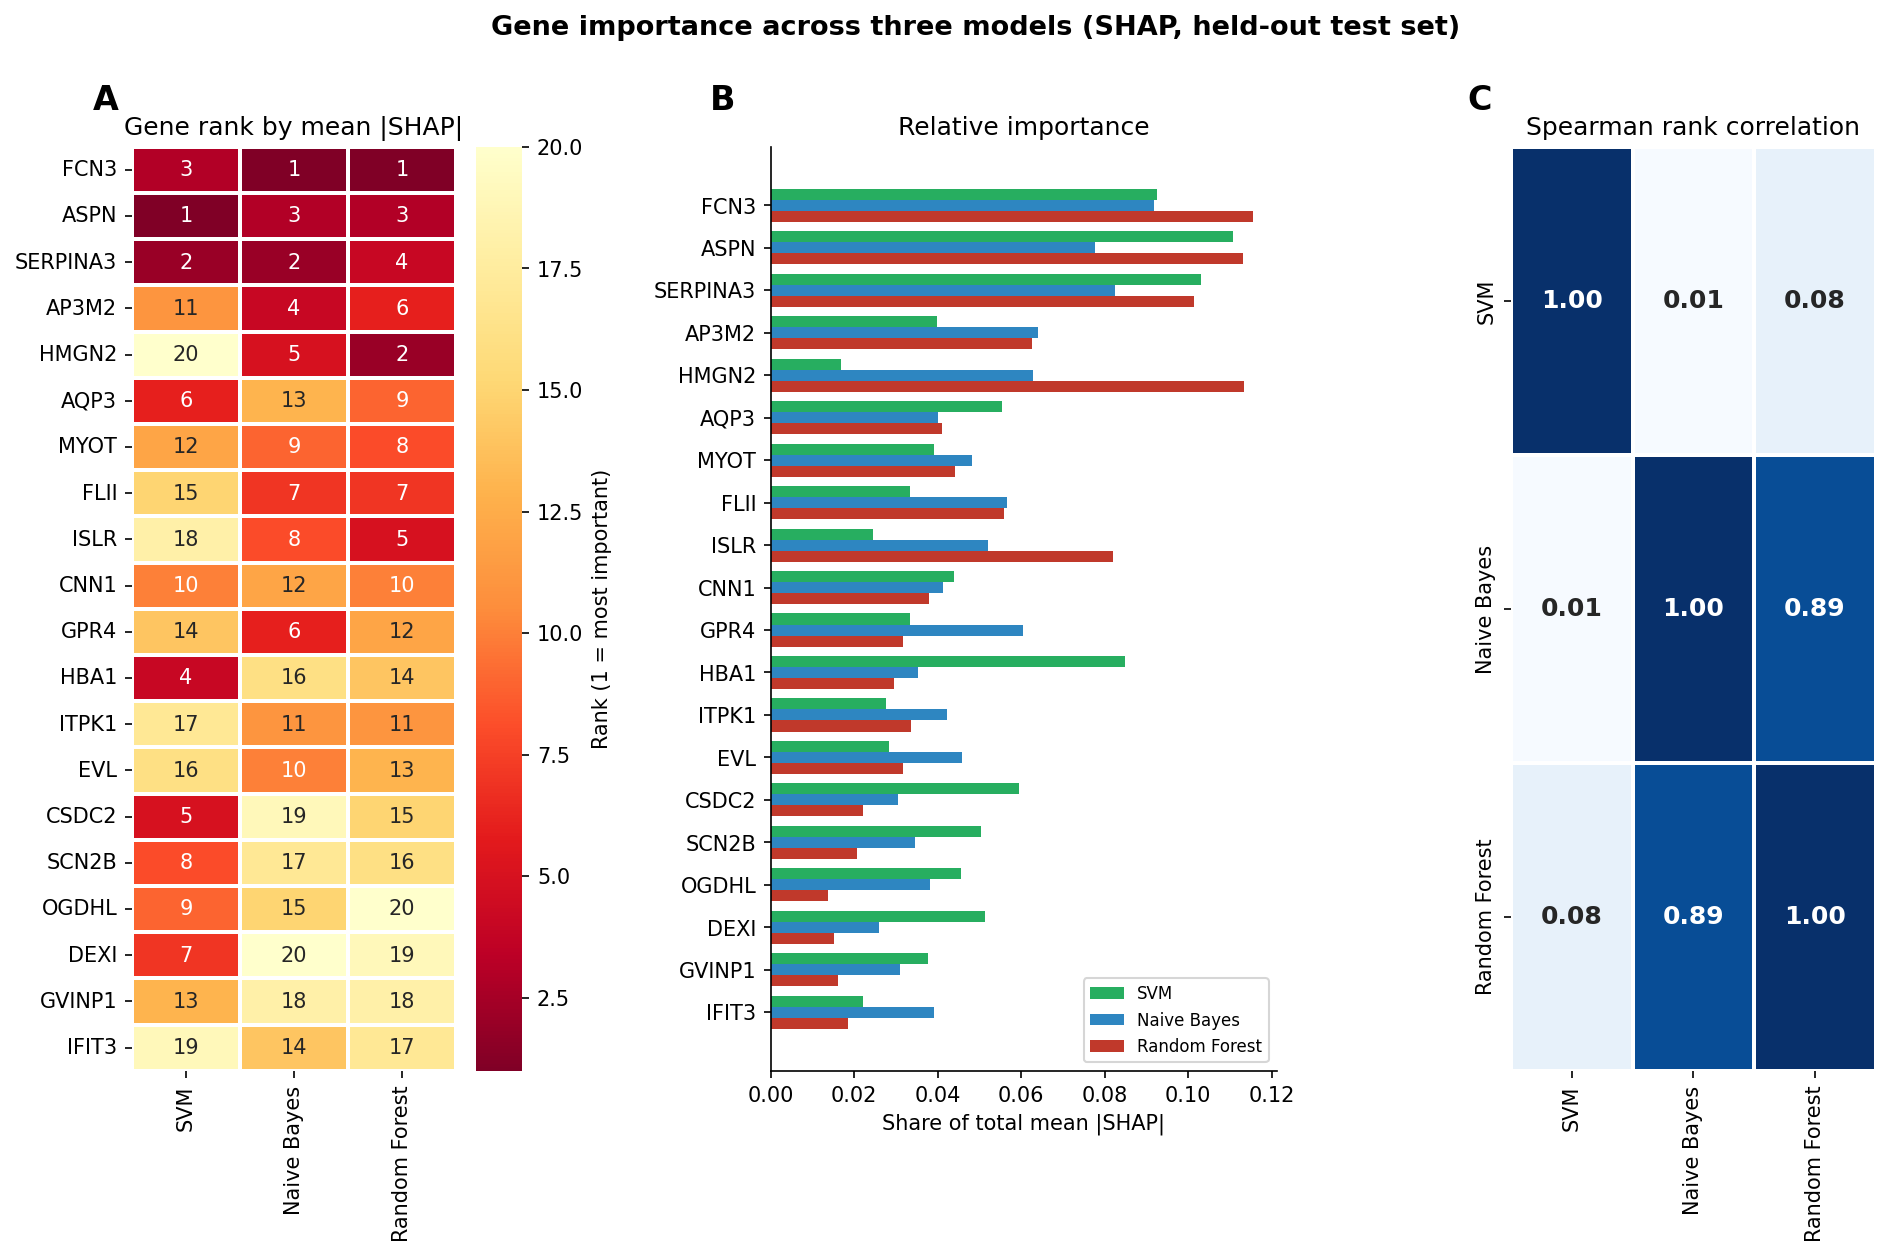


 SHAP_comparison_3models.svg / .png / .csv saved


In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import shap
from scipy.stats import spearmanr

SHAP_MODELS = ['SVM', 'Naive Bayes', 'Random Forest']
COL = {'SVM': '#27AE60', 'Naive Bayes': '#2E86C1', 'Random Forest': '#C0392B'}

imp = {}
for m in SHAP_MODELS:
    print(f'SHAP for {m} ...')
    expl = shap.Explainer(hf_models[m].predict_proba, hf_Xte, feature_names=hf_genes)
    sv   = expl(hf_Xte)
    imp[m] = np.abs(sv.values[:, :, 1]).mean(axis=0)
imp_df = pd.DataFrame(imp, index=hf_genes)

try:
    old = pd.read_csv(SAVE / 'hf_shap_importance.csv').set_index('Gene')['SHAP'].reindex(hf_genes)
    rho_old = spearmanr(old, imp_df['SVM'])[0]
    print(f'SVM ranking vs saved hf_shap_importance.csv: Spearman rho = {rho_old:.3f}')
except Exception as e:
    print('saved SHAP file not compared:', e)

share = imp_df / imp_df.sum()
rank  = imp_df.rank(ascending=False).astype(int)
order = rank.mean(axis=1).sort_values().index

pairs = [('SVM', 'Naive Bayes'), ('SVM', 'Random Forest'), ('Naive Bayes', 'Random Forest')]
rows = []
for a, b in pairs:
    rho, p = spearmanr(imp_df[a], imp_df[b])
    top5  = len(set(rank[a].nsmallest(5).index)  & set(rank[b].nsmallest(5).index))
    top10 = len(set(rank[a].nsmallest(10).index) & set(rank[b].nsmallest(10).index))
    rows.append({'Model_A': a, 'Model_B': b, 'Spearman_rho': round(rho, 3), 'p_value': float(f'{p:.2e}'),
                 'Top5_overlap': f'{top5}/5', 'Top10_overlap': f'{top10}/10'})
agree = pd.DataFrame(rows)
print('\n Agreement between models')
print(agree.to_string(index=False))
print('\n Top 20 genes per model (rank, gene, mean |SHAP|)')
top20 = pd.DataFrame({'Rank': range(1, len(hf_genes) + 1)})
for m in SHAP_MODELS:
    srt = imp_df[m].sort_values(ascending=False)
    top20[m + '_gene'] = srt.index
    top20[m + '_meanAbsSHAP'] = srt.values.round(4)
print(top20.to_string(index=False))
top20.to_csv(SAVE / 'SHAP_top20_per_model.csv', index=False)

out = imp_df.add_prefix('meanAbsSHAP_').join(rank.add_prefix('rank_')).loc[order]
out.round(5).to_csv(SAVE / 'SHAP_comparison_3models.csv')
agree.to_csv(SAVE / 'SHAP_comparison_3models_agreement.csv', index=False)

fig = plt.figure(figsize=(15, 8))
gs  = gridspec.GridSpec(1, 3, figure=fig, width_ratios=[1.0, 1.25, 0.9], wspace=0.55)
axA, axB, axC = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])

sns.heatmap(rank.loc[order, SHAP_MODELS], annot=True, fmt='d', cmap='YlOrRd_r', vmin=1, vmax=len(hf_genes),
            cbar_kws={'label': 'Rank (1 = most important)'}, linewidths=1, linecolor='white', ax=axA)
axA.set_title('Gene rank by mean |SHAP|'); axA.set_ylabel(''); axA.tick_params(axis='y', rotation=0)

y = np.arange(len(order)); h = 0.26
for k, m in enumerate(SHAP_MODELS):
    axB.barh(y + (k - 1) * h, share.loc[order, m], h, color=COL[m], label=m)
axB.set_yticks(y); axB.set_yticklabels(order); axB.invert_yaxis()
axB.set_xlabel('Share of total mean |SHAP|'); axB.set_title('Relative importance')
axB.legend(fontsize=8, loc='lower right'); axB.spines[['top', 'right']].set_visible(False)

rho_mat = pd.DataFrame(index=SHAP_MODELS, columns=SHAP_MODELS, dtype=float)
for a in SHAP_MODELS:
    for b in SHAP_MODELS:
        rho_mat.loc[a, b] = spearmanr(imp_df[a], imp_df[b])[0]
sns.heatmap(rho_mat, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False,
            linewidths=1, linecolor='white', annot_kws={'size': 12, 'weight': 'bold'}, ax=axC)
axC.set_title('Spearman rank correlation')
for ax_, lab in zip([axA, axB, axC], 'ABC'):
    ax_.text(-0.12, 1.04, lab, transform=ax_.transAxes, fontsize=16, fontweight='bold')
fig.suptitle('Gene importance across three models (SHAP, held-out test set)', fontsize=13, fontweight='bold', y=0.99)
for ext, kw in [('svg', {}), ('png', {'dpi': 300})]:
    fig.savefig(SAVE / f'SHAP_comparison_3models.{ext}', format=ext, bbox_inches='tight', facecolor='white', **kw)
plt.show()
print('\n SHAP_comparison_3models.svg / .png / .csv saved')

  29 samples

 Extracting GSE42955...
  GPL6244: gene_assignment → 23985 probes
  n=29 | disease=24 | control=5

 Evaluating...
  GSE42955: n=29 | AUC=0.967 [0.885-1.000] | Sens=0.958 | Spec=0.800 | Coverage=95% (19/20 genes)

 Results:
 Dataset Disease  N   AUC  CI_lo  CI_hi  Sensitivity  Specificity
GSE42955      HF 29 0.967  0.885    1.0        0.958          0.8


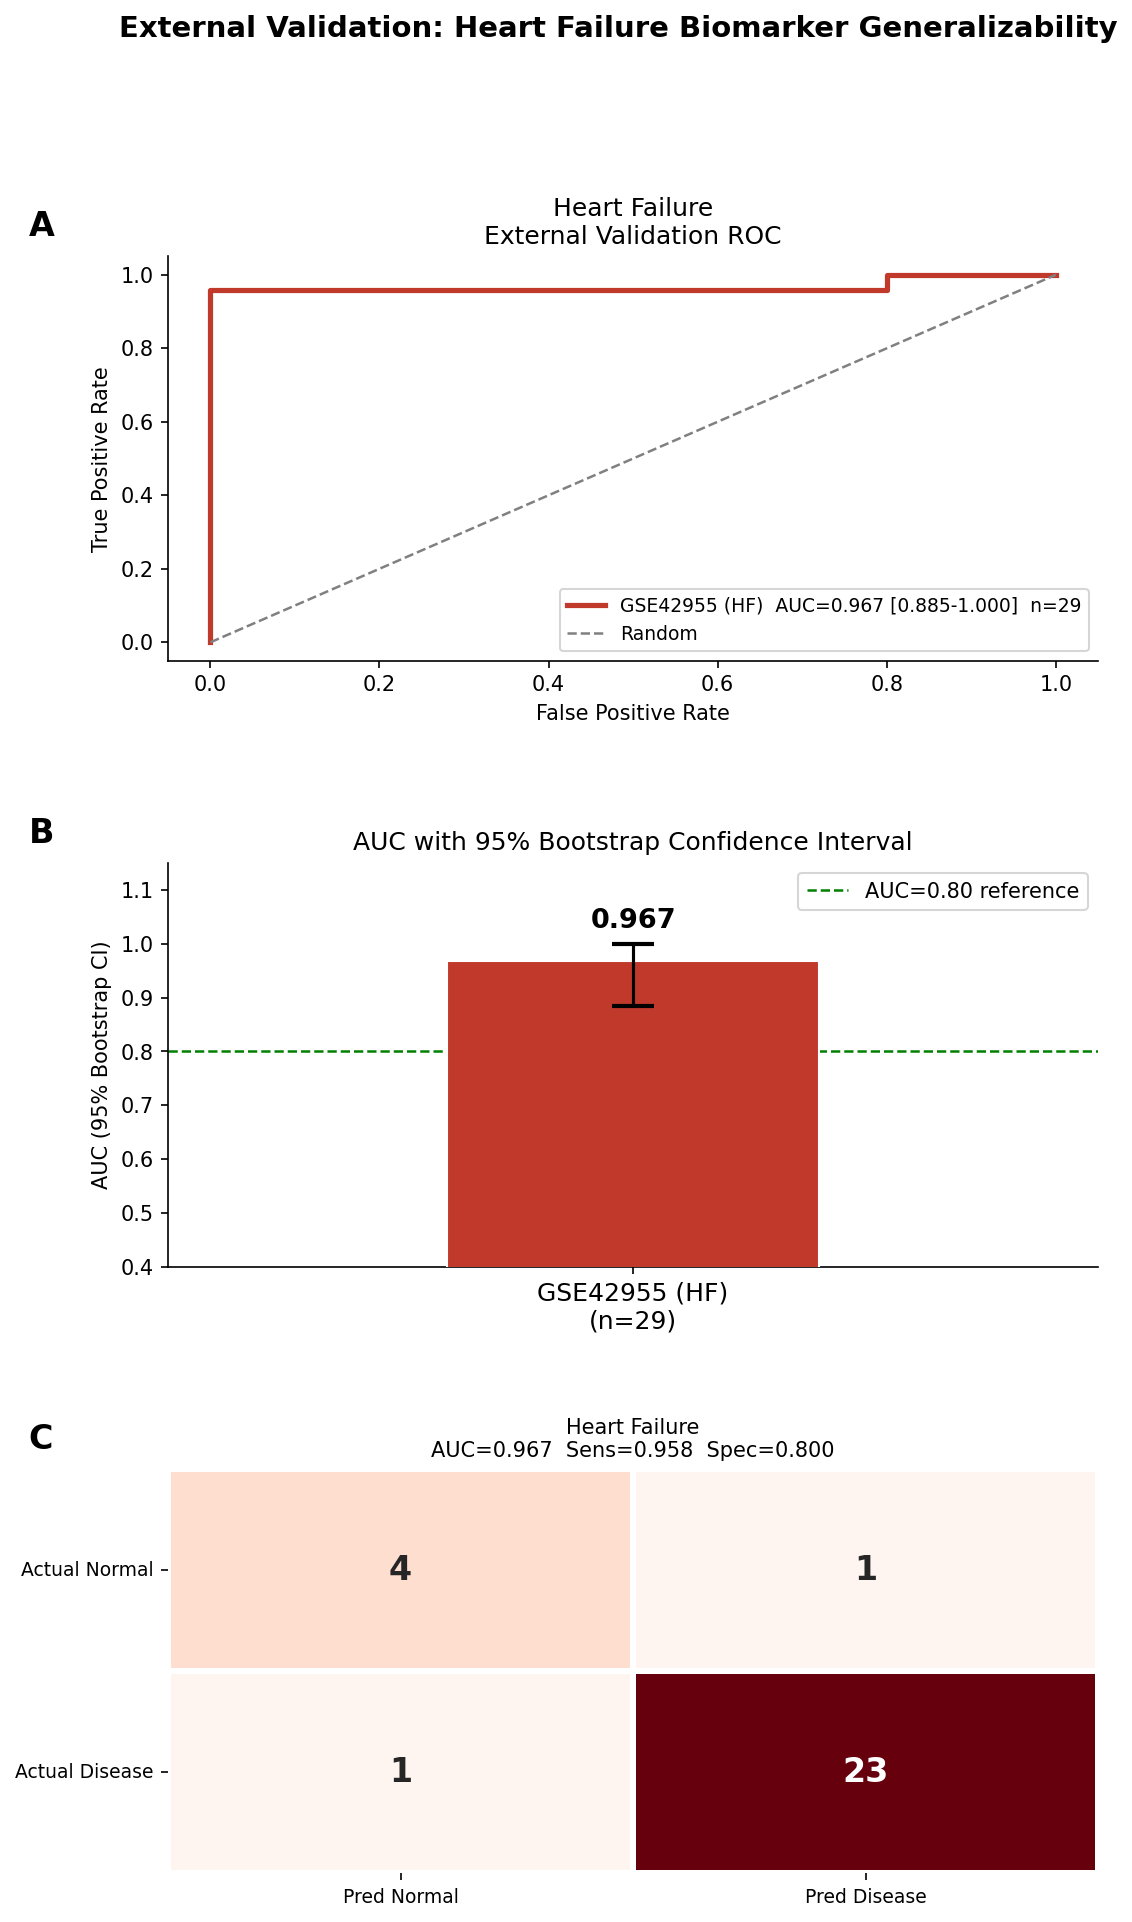

 external_validation_HF.svg saved
External Validation complete


In [105]:

import GEOparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

SAVE_EV = Path('/kaggle/working')


def extract_ev_with_genes(gse_obj, disease_kws, control_kws):
    gene_map = {}
    for gpl_name, gpl in gse_obj.gpls.items():
        cols = gpl.table.columns.tolist()
        if 'gene_assignment' in cols:
            ann = gpl.table[['ID','gene_assignment']].copy()
            ann['Gene'] = ann['gene_assignment'].astype(str)\
                            .str.extract(r'//\s*([A-Z][A-Z0-9]+)\s*//')
            ann = ann[['ID','Gene']].dropna()
            gene_map = dict(zip(ann['ID'].astype(str), ann['Gene']))
            print(f'  {gpl_name}: gene_assignment → {len(gene_map)} probes')
        elif 'Gene Symbol' in cols:
            ann = gpl.table[['ID','Gene Symbol']].copy()
            ann['Gene'] = ann['Gene Symbol'].astype(str)\
                            .str.split(' /// ').str[0].str.strip()
            ann = ann[ann['Gene'].notna() & (ann['Gene'] != 'nan') & (ann['Gene'] != '')]
            gene_map = dict(zip(ann['ID'].astype(str), ann['Gene']))
            print(f'  {gpl_name}: Gene Symbol → {len(gene_map)} probes')
        elif 'GENE_SYMBOL' in cols:
            ann = gpl.table[['ID','GENE_SYMBOL']].copy()
            ann['Gene'] = ann['GENE_SYMBOL'].astype(str)\
                            .str.split(' /// ').str[0].str.strip()
            ann = ann[ann['Gene'].notna() & (ann['Gene'] != 'nan') & (ann['Gene'] != '')]
            gene_map = dict(zip(ann['ID'].astype(str), ann['Gene']))
            print(f'  {gpl_name}: GENE_SYMBOL → {len(gene_map)} probes')

    expr_list, labels = [], []
    for gsm_id, gsm in gse_obj.gsms.items():
        text = ' '.join(
            gsm.metadata.get('characteristics_ch1', []) +
            gsm.metadata.get('source_name_ch1', []) +
            gsm.metadata.get('title', [])
        ).lower()
        if any(k in text for k in disease_kws):
            label = 1
        elif any(k in text for k in control_kws):
            label = 0
        else:
            continue
        try:
            t = gsm.table.copy()
            t['VALUE']  = pd.to_numeric(t['VALUE'], errors='coerce')
            t['ID_REF'] = t['ID_REF'].astype(str)
            if gene_map:
                t['Gene'] = t['ID_REF'].map(gene_map)
                t = t[t['Gene'].notna() & (t['Gene'] != 'nan') & (t['Gene'] != '---')]
                s = t.groupby('Gene')['VALUE'].mean()
            else:
                s = t.set_index('ID_REF')['VALUE']
            expr_list.append(s.rename(gsm_id))
            labels.append(label)
        except Exception as e:
            print(f'  [WARN] {gsm_id} skipped: {e}')
            continue

    if not expr_list:
        print('  [ERROR] No samples extracted!')
        return None, None

    X = pd.concat(expr_list, axis=1).T
    X = np.log2(X.apply(pd.to_numeric, errors='coerce').fillna(0).clip(lower=0) + 1)
    return X, np.array(labels)


def evaluate_ev(X_ev, y_ev, genes, model, dataset_id):
    avail = [g for g in genes if g in X_ev.columns]
    cov   = len(avail) / len(genes) * 100

    X = pd.DataFrame(0.0, index=X_ev.index, columns=genes)
    X[avail] = X_ev[avail].values

    sc = StandardScaler()
    Xs = sc.fit_transform(X.values)

    y_prob = model.predict_proba(Xs)[:, 1]
    y_pred = model.predict(Xs)

    auc = roc_auc_score(y_ev, y_prob)
    fpr, tpr, _ = roc_curve(y_ev, y_prob)
    cm  = confusion_matrix(y_ev, y_pred)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn + 1e-9)
    spec = tn / (tn + fp + 1e-9)

    
    rng  = np.random.default_rng(42)
    boot = []
    for _ in range(1000):
        idx = rng.choice(len(y_ev), len(y_ev), replace=True)
        if len(np.unique(y_ev[idx])) > 1:
            boot.append(roc_auc_score(y_ev[idx], y_prob[idx]))
    ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

    print(f'  {dataset_id}: n={len(y_ev)} | '
          f'AUC={auc:.3f} [{ci_lo:.3f}-{ci_hi:.3f}] | '
          f'Sens={sens:.3f} | Spec={spec:.3f} | '
          f'Coverage={cov:.0f}% ({len(avail)}/{len(genes)} genes)')

    return dict(
        dataset=dataset_id, n=len(y_ev),
        auc=round(auc,3), ci_lo=round(ci_lo,3), ci_hi=round(ci_hi,3),
        sens=round(sens,3), spec=round(spec,3),
        fpr=fpr, tpr=tpr,
        tp=int(tp), tn=int(tn), fp=int(fp), fn=int(fn),
    )


print('Downloading GSE42955 (HF validation)...')
gse42955 = GEOparse.get_GEO('GSE42955', destdir='/kaggle/working/', silent=True)
print(f'  {len(gse42955.gsms)} samples')


print('\n Extracting GSE42955...')
X_42955, y_42955 = extract_ev_with_genes(
    gse42955,
    disease_kws=['ischemic cardiomyopathy', 'dilated cardiomyopathy'],
    control_kws=['normal heart'])
print(f'  n={len(y_42955)} | disease={y_42955.sum()} | control={(y_42955==0).sum()}')


print('\n Evaluating...')
res_hf = evaluate_ev(X_42955, y_42955, hf_genes, hf_models['SVM'], 'GSE42955')


ev_df = pd.DataFrame([
    {'Dataset':'GSE42955','Disease':'HF','N':res_hf['n'],
     'AUC':res_hf['auc'],'CI_lo':res_hf['ci_lo'],'CI_hi':res_hf['ci_hi'],
     'Sensitivity':res_hf['sens'],'Specificity':res_hf['spec']},
])
ev_df.to_csv(SAVE_EV / 'external_validation_results.csv', index=False)
print('\n Results:')
print(ev_df.to_string(index=False))


for res, title, dataset_label, col, cmap, fname in [
    (res_hf, 'Heart Failure', 'GSE42955 (HF)', '#C0392B', 'Reds', 'external_validation_HF.svg'),
]:
    fig = plt.figure(figsize=(8, 14))
    gs  = gridspec.GridSpec(3, 1, figure=fig, hspace=0.5)

    
    ax_a = fig.add_subplot(gs[0])
    ax_a.plot(res['fpr'], res['tpr'], color=col, lw=2.5,
              label=f"{dataset_label}  AUC={res['auc']:.3f} [{res['ci_lo']:.3f}-{res['ci_hi']:.3f}]  n={res['n']}")
    ax_a.plot([0,1],[0,1],'--',color='gray',lw=1.2,label='Random')
    ax_a.set_xlabel('False Positive Rate')
    ax_a.set_ylabel('True Positive Rate')
    ax_a.set_title(f'{title}\nExternal Validation ROC')
    ax_a.legend(loc='lower right', fontsize=9)
    ax_a.text(-0.15, 1.05, 'A', transform=ax_a.transAxes, fontsize=16, fontweight='bold')

    
    ax_b = fig.add_subplot(gs[1])
    ax_b.bar(0, res['auc'], color=col, width=0.4, edgecolor='white', zorder=3)
    ax_b.errorbar(0, res['auc'],
                  yerr=[[res['auc']-res['ci_lo']], [res['ci_hi']-res['auc']]],
                  fmt='none', color='black', capsize=10, capthick=2, zorder=4)
    ax_b.text(0, res['ci_hi']+0.03, f"{res['auc']:.3f}",
              ha='center', fontweight='bold', fontsize=13)
    ax_b.axhline(0.8, color='green', ls='--', lw=1.2, label='AUC=0.80 reference')
    ax_b.set_xticks([0])
    ax_b.set_xticklabels([f"{dataset_label}\n(n={res['n']})"], fontsize=12)
    ax_b.set_ylabel('AUC (95% Bootstrap CI)')
    ax_b.set_title('AUC with 95% Bootstrap Confidence Interval')
    ax_b.set_xlim([-0.5, 0.5])
    ax_b.set_ylim([0.4, 1.15])
    ax_b.legend(fontsize=10)
    ax_b.text(-0.15, 1.05, 'B', transform=ax_b.transAxes, fontsize=16, fontweight='bold')

    
    ax_c = fig.add_subplot(gs[2])
    cm_arr = np.array([[res['tn'],res['fp']],[res['fn'],res['tp']]])
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap=cmap, ax=ax_c,
                cbar=False, linewidths=2, linecolor='white',
                annot_kws={'size':16,'weight':'bold'})
    ax_c.set_xticklabels(['Pred Normal','Pred Disease'], fontsize=9)
    ax_c.set_yticklabels(['Actual Normal','Actual Disease'], fontsize=9, rotation=0)
    ax_c.set_title(f'{title}\nAUC={res["auc"]:.3f}  Sens={res["sens"]:.3f}  Spec={res["spec"]:.3f}', fontsize=10)
    ax_c.text(-0.15, 1.05, 'C', transform=ax_c.transAxes, fontsize=16, fontweight='bold')

    fig.suptitle(f'External Validation: {title} Biomarker Generalizability',
                 fontsize=14, fontweight='bold', y=0.995)
    plt.savefig(SAVE_EV / fname, format='svg', bbox_inches='tight', facecolor='white')
    plt.show()
    print(f' {fname} saved')

print('External Validation complete')


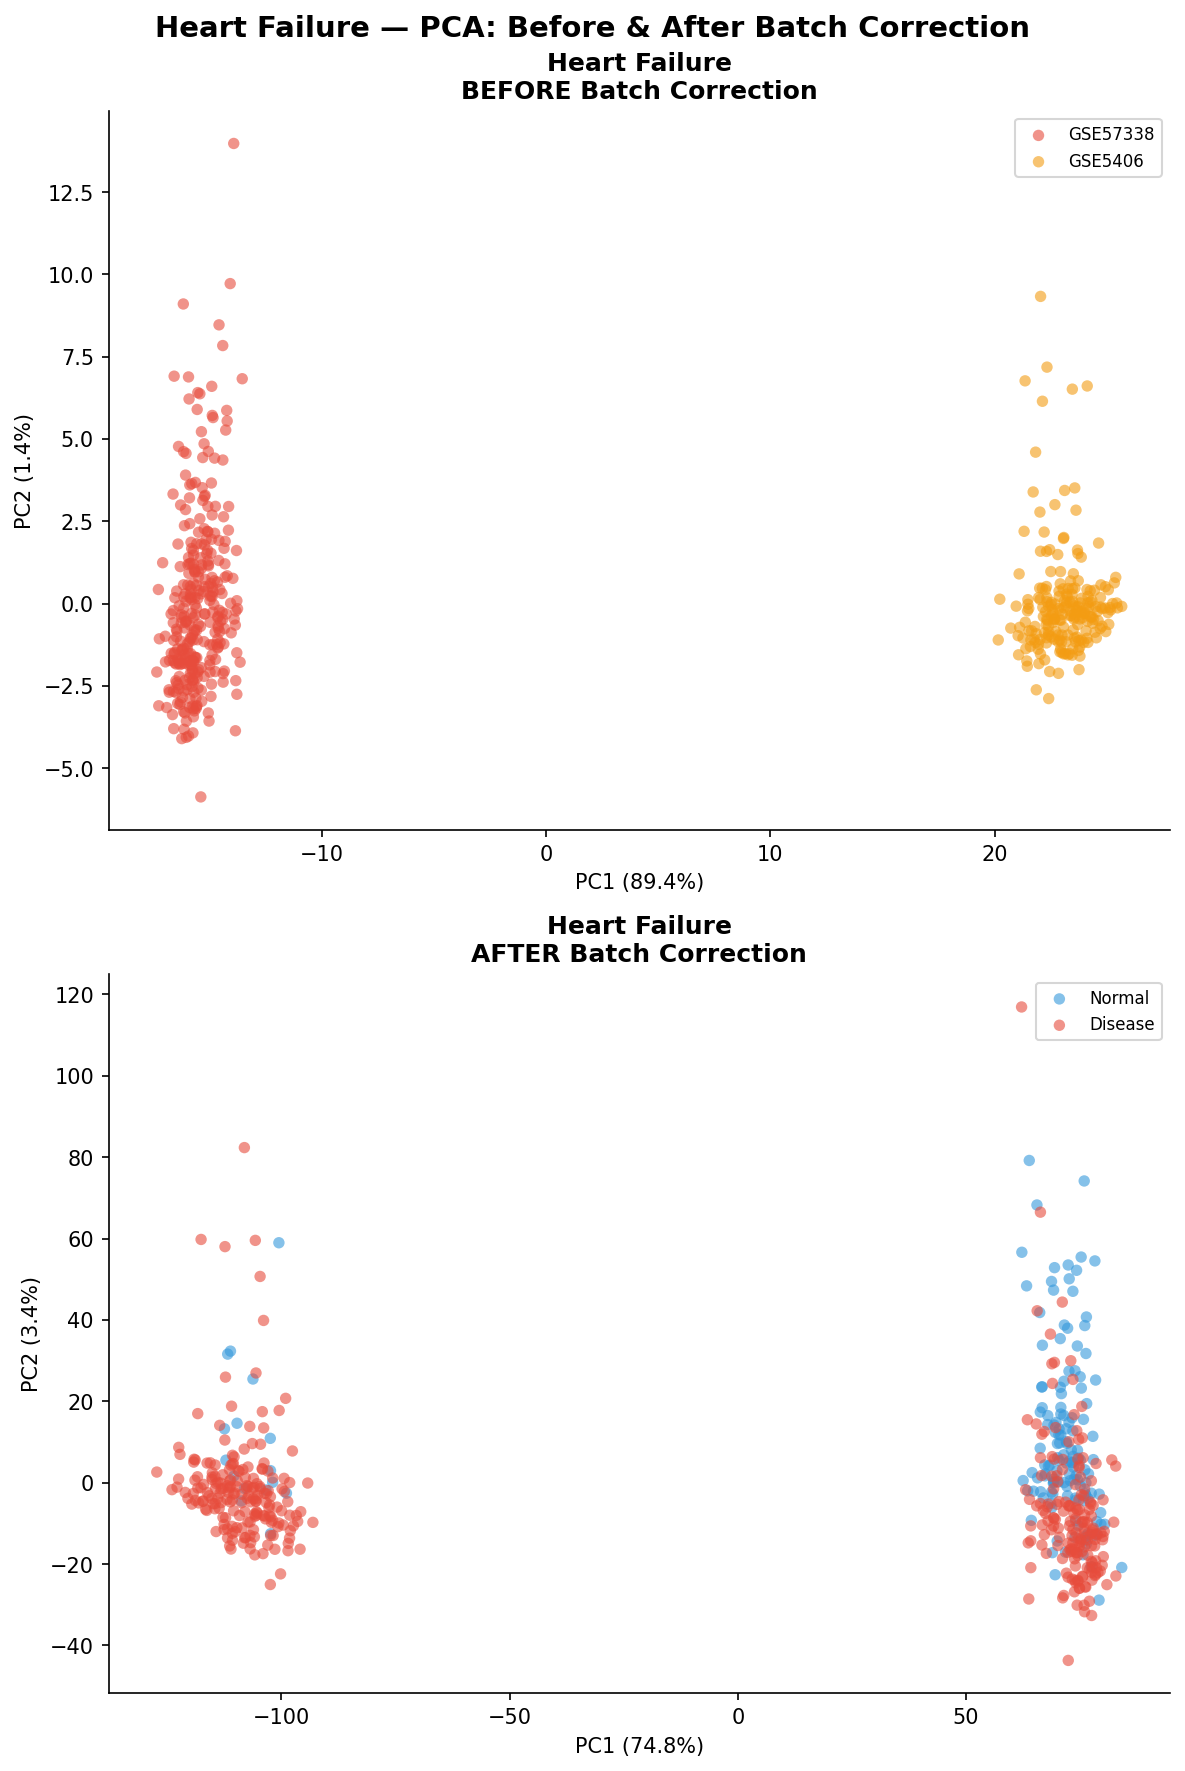

PCA_before_after_HF.svg saved


In [106]:

from sklearn.decomposition import PCA

datasets = [
    
    (heart_merged, heart_corrected, heart_labels,
     'Heart Failure', '#3498db', '#e74c3c',
     ['GSE57338']*len(labels_h1) + ['GSE5406']*len(labels_h2),
     'PCA_before_after_HF.svg'),
]

batch_colors = {'GSE57338':'#e74c3c','GSE5406':'#f39c12'}

for before, after, labels, title, c_ctrl, c_dis, batch_labels, fname in datasets:

    fig, axes = plt.subplots(2, 1, figsize=(8, 12))

    
    ax = axes[0]
    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(before.T.fillna(0))
    for batch in set(batch_labels):
        idx = [i for i,b in enumerate(batch_labels) if b==batch]
        ax.scatter(coords[idx,0], coords[idx,1],
                   c=batch_colors[batch], label=batch,
                   alpha=0.6, s=30, edgecolors='none')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(f'{title}\nBEFORE Batch Correction', fontweight='bold')
    ax.legend(fontsize=8)

    
    ax = axes[1]
    pca2 = PCA(n_components=2, random_state=42)
    coords2 = pca2.fit_transform(after.T.fillna(0))
    for flag, color, label in [(0, c_ctrl, 'Normal'), (1, c_dis, 'Disease')]:
        idx = [i for i,l in enumerate(labels) if l==flag]
        ax.scatter(coords2[idx,0], coords2[idx,1],
                   c=color, label=label,
                   alpha=0.6, s=30, edgecolors='none')
    ax.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(f'{title}\nAFTER Batch Correction', fontweight='bold')
    ax.legend(fontsize=8)

    plt.suptitle(f'{title} — PCA: Before & After Batch Correction', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f'{fname} saved')


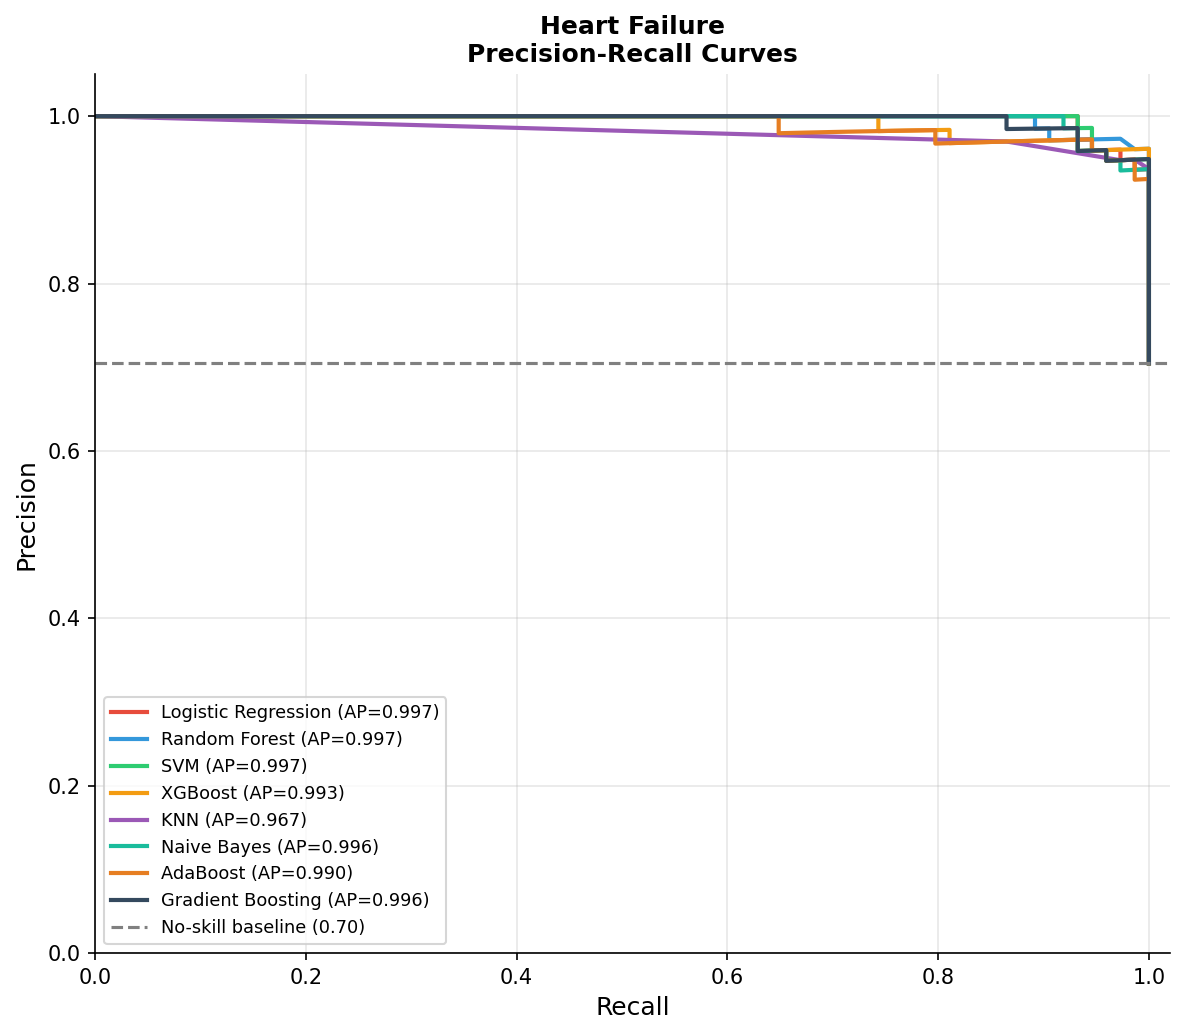

 PR_AUC_curves_HF.svg saved


In [107]:


from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

COLORS = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22','#34495e']

for models, Xte, yte, title, fname in [
    (hf_models, hf_Xte, hf_yte, 'Heart Failure', 'PR_AUC_curves_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(8, 7))

    for (mname, model), color in zip(models.items(), COLORS):
        y_prob = model.predict_proba(Xte)[:, 1]
        prec, rec, _ = precision_recall_curve(yte, y_prob)
        ap = average_precision_score(yte, y_prob)
        ax.plot(rec, prec, color=color, lw=2, label=f'{mname} (AP={ap:.3f})')

    
    baseline = yte.sum() / len(yte)
    ax.axhline(baseline, color='gray', ls='--', lw=1.5,
               label=f'No-skill baseline ({baseline:.2f})')

    ax.set_xlabel('Recall', fontsize=12)
    ax.set_ylabel('Precision', fontsize=12)
    ax.set_title(f'{title}\nPrecision-Recall Curves', fontsize=12, fontweight='bold')
    ax.legend(loc='lower left', fontsize=8.5)
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight', facecolor='white')
    plt.show()
    print(f' {fname} saved')


Heart Failure: Best threshold=0.10 | F1=0.960 | MCC=0.861 | Sens=0.973 | Spec=0.871


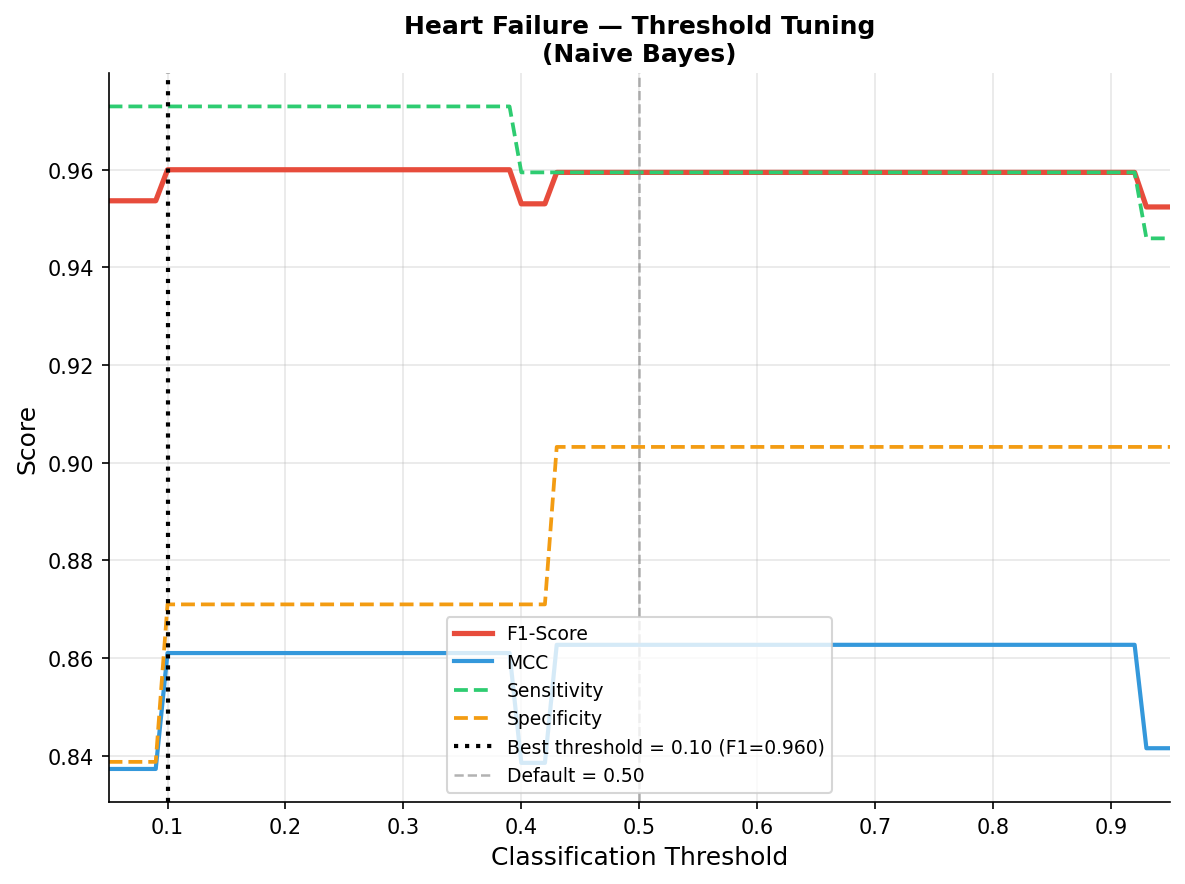

Threshold_Tuning_HF.svg saved


In [108]:


from sklearn.metrics import f1_score, matthews_corrcoef
import matplotlib.pyplot as plt
import numpy as np

best_hf_name = hf_results.iloc[0]['Model']

for model, Xte, yte, best_name, title, main_color, fname in [
    (hf_models[best_hf_name], hf_Xte, hf_yte, best_hf_name, 'Heart Failure', '#E74C3C', 'Threshold_Tuning_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(8, 6))

    y_prob = model.predict_proba(Xte)[:, 1]
    thresholds = np.arange(0.05, 0.96, 0.01)

    f1s, mccs, sens_list, spec_list = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        f1s.append(f1_score(yte, y_pred, zero_division=0))
        mccs.append(matthews_corrcoef(yte, y_pred))
        tn_ = ((y_pred == 0) & (yte == 0)).sum()
        tp_ = ((y_pred == 1) & (yte == 1)).sum()
        fp_ = ((y_pred == 1) & (yte == 0)).sum()
        fn_ = ((y_pred == 0) & (yte == 1)).sum()
        sens_list.append(tp_ / (tp_ + fn_ + 1e-9))
        spec_list.append(tn_ / (tn_ + fp_ + 1e-9))

    best_idx = np.argmax(f1s)
    best_t   = thresholds[best_idx]

    ax.plot(thresholds, f1s,        color=main_color,  lw=2.5, label='F1-Score')
    ax.plot(thresholds, mccs,        color='#3498DB',   lw=2,   label='MCC')
    ax.plot(thresholds, sens_list,   color='#2ECC71',   lw=1.8, ls='--', label='Sensitivity')
    ax.plot(thresholds, spec_list,   color='#F39C12',   lw=1.8, ls='--', label='Specificity')
    ax.axvline(best_t, color='black', ls=':', lw=2,
               label=f'Best threshold = {best_t:.2f} (F1={f1s[best_idx]:.3f})')
    ax.axvline(0.5,    color='gray',  ls='--', lw=1.2, alpha=0.6, label='Default = 0.50')

    ax.set_xlabel('Classification Threshold', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title(f'{title} — Threshold Tuning\n({best_name})', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='lower center')
    ax.grid(alpha=0.3)
    ax.set_xlim(0.05, 0.95)
    ax.spines[['top', 'right']].set_visible(False)

    print(f'{title}: Best threshold={best_t:.2f} | '
          f'F1={f1s[best_idx]:.3f} | MCC={mccs[best_idx]:.3f} | '
          f'Sens={sens_list[best_idx]:.3f} | Spec={spec_list[best_idx]:.3f}')

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'{fname} saved')


In [109]:

from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

def cv_auc_scores(corrected, y_arr, genes, models_dict, n_splits=5):
    """5-fold CV AUC scores for all models"""
    X = corrected.T[genes].values
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    scores = {name: [] for name in models_dict}
    for train_idx, val_idx in skf.split(X, y_arr):
        sc = StandardScaler()
        Xtr = sc.fit_transform(X[train_idx])
        Xva = sc.transform(X[val_idx])
        for name, model in models_dict.items():
            import copy
            m = copy.deepcopy(model)
            m.fit(Xtr, y_arr[train_idx])
            yp = m.predict_proba(Xva)[:, 1]
            scores[name].append(roc_auc_score(y_arr[val_idx], yp))
    return {k: np.array(v) for k, v in scores.items()}

def bootstrap_ci(y_true, y_prob, n_boot=1000, seed=42):
    rng  = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.choice(len(y_true), len(y_true), replace=True)
        if len(np.unique(y_true[idx])) < 2: continue
        aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])


print('Computing 5-fold CV AUC scores on TRAIN split only (leakage-safe, takes ~2 min)...')
hf_cv = cv_auc_scores(heart_corrected[heart_train_cols], heart_ytr, hf_genes, hf_models)
print('ok')

print('\n Friedman test...')
hf_arrays = list(hf_cv.values())
hf_chi2, hf_p = friedmanchisquare(*hf_arrays)
print(f'  Heart Failure  : χ² = {hf_chi2:.3f}, p = {hf_p:.4e}')

print('\n Bootstrap CI for ALL models (test set, held out, touched once)...')
hf_ci_by_model = {}
for mname, model in hf_models.items():
    proba = model.predict_proba(hf_Xte)[:, 1]
    hf_ci_by_model[mname] = bootstrap_ci(hf_yte, proba)

hf_best_name = hf_results.iloc[0]['Model']
hf_ci = hf_ci_by_model[hf_best_name]

print(f'  HF Best ({hf_best_name}): '
      f'AUC={hf_results.iloc[0]["AUC"]:.3f} '
      f'[{hf_ci[0]:.3f}–{hf_ci[1]:.3f}]')


print('\n 5-Fold CV AUC + Bootstrap 95% CI Summary')
rows = []
for name in hf_cv:
    hf_s   = hf_cv[name]
    hf_lo, hf_hi = hf_ci_by_model[name]
    rows.append({
        'Model': name,
        'HF CV AUC': f'{hf_s.mean():.3f} ± {hf_s.std():.3f}',
        'HF Test AUC 95% CI': f'[{hf_lo:.3f}-{hf_hi:.3f}]',
    })
cv_df = pd.DataFrame(rows)
print(cv_df.to_string(index=False))
cv_df.to_csv(SAVE / 'CV_AUC_summary.csv', index=False)


stat_rows = []
for name in hf_cv:
    hf_lo, hf_hi = hf_ci_by_model[name]
    stat_rows.append({'Disease': 'Heart Failure', 'Model': name,
                       'CI_lo': round(hf_lo, 3), 'CI_hi': round(hf_hi, 3)})
stat_summary = pd.DataFrame([
    {'Disease': 'Heart Failure', 'Friedman_chi2': round(hf_chi2, 3),
     'p_value': round(hf_p, 6), 'Best_Model': hf_best_name,
     'Best_AUC': hf_results.iloc[0]['AUC'],
     'CI_lo': round(hf_ci[0], 3), 'CI_hi': round(hf_ci[1], 3)},
])
stat_summary.to_csv(SAVE / 'statistical_validation.csv', index=False)
pd.DataFrame(stat_rows).to_csv(SAVE / 'bootstrap_CI_all_models.csv', index=False)
print('\n CV_AUC_summary.csv + statistical_validation.csv + bootstrap_CI_all_models.csv saved')


Computing 5-fold CV AUC scores on TRAIN split only (leakage-safe, takes ~2 min)...
ok

 Friedman test...
  Heart Failure  : χ² = 12.355, p = 8.9470e-02

 Bootstrap CI for ALL models (test set, held out, touched once)...
  HF Best (Naive Bayes): AUC=0.991 [0.976–0.999]

 5-Fold CV AUC + Bootstrap 95% CI Summary
              Model     HF CV AUC HF Test AUC 95% CI
Logistic Regression 0.982 ± 0.021      [0.981-1.000]
      Random Forest 0.987 ± 0.016      [0.980-1.000]
                SVM 0.981 ± 0.021      [0.981-1.000]
            XGBoost 0.984 ± 0.015      [0.958-1.000]
                KNN 0.984 ± 0.016      [0.902-0.998]
        Naive Bayes 0.990 ± 0.013      [0.976-0.999]
           AdaBoost 0.985 ± 0.016      [0.948-0.999]
  Gradient Boosting 0.987 ± 0.012      [0.974-0.999]

 CV_AUC_summary.csv + statistical_validation.csv + bootstrap_CI_all_models.csv saved



 Heart Failure
  Cell Type                 p-value   adj.p (BH)  Cohen's d  Significant
  --------------------------------------------------------------------
  CD8+ T cells               0.0000       0.0000      1.181          Yes
  CD4+ T cells               0.0000       0.0000      0.969          Yes
  B cells                    0.0000       0.0000      1.026          Yes
  NK cells                   0.0000       0.0000      1.376          Yes
  Macrophages                0.0000       0.0000     -0.946          Yes
  Neutrophils                0.7570       0.7570     -0.057           No
  Monocytes                  0.0008       0.0009     -0.246          Yes
  Dendritic cells            0.0000       0.0000      0.730          Yes


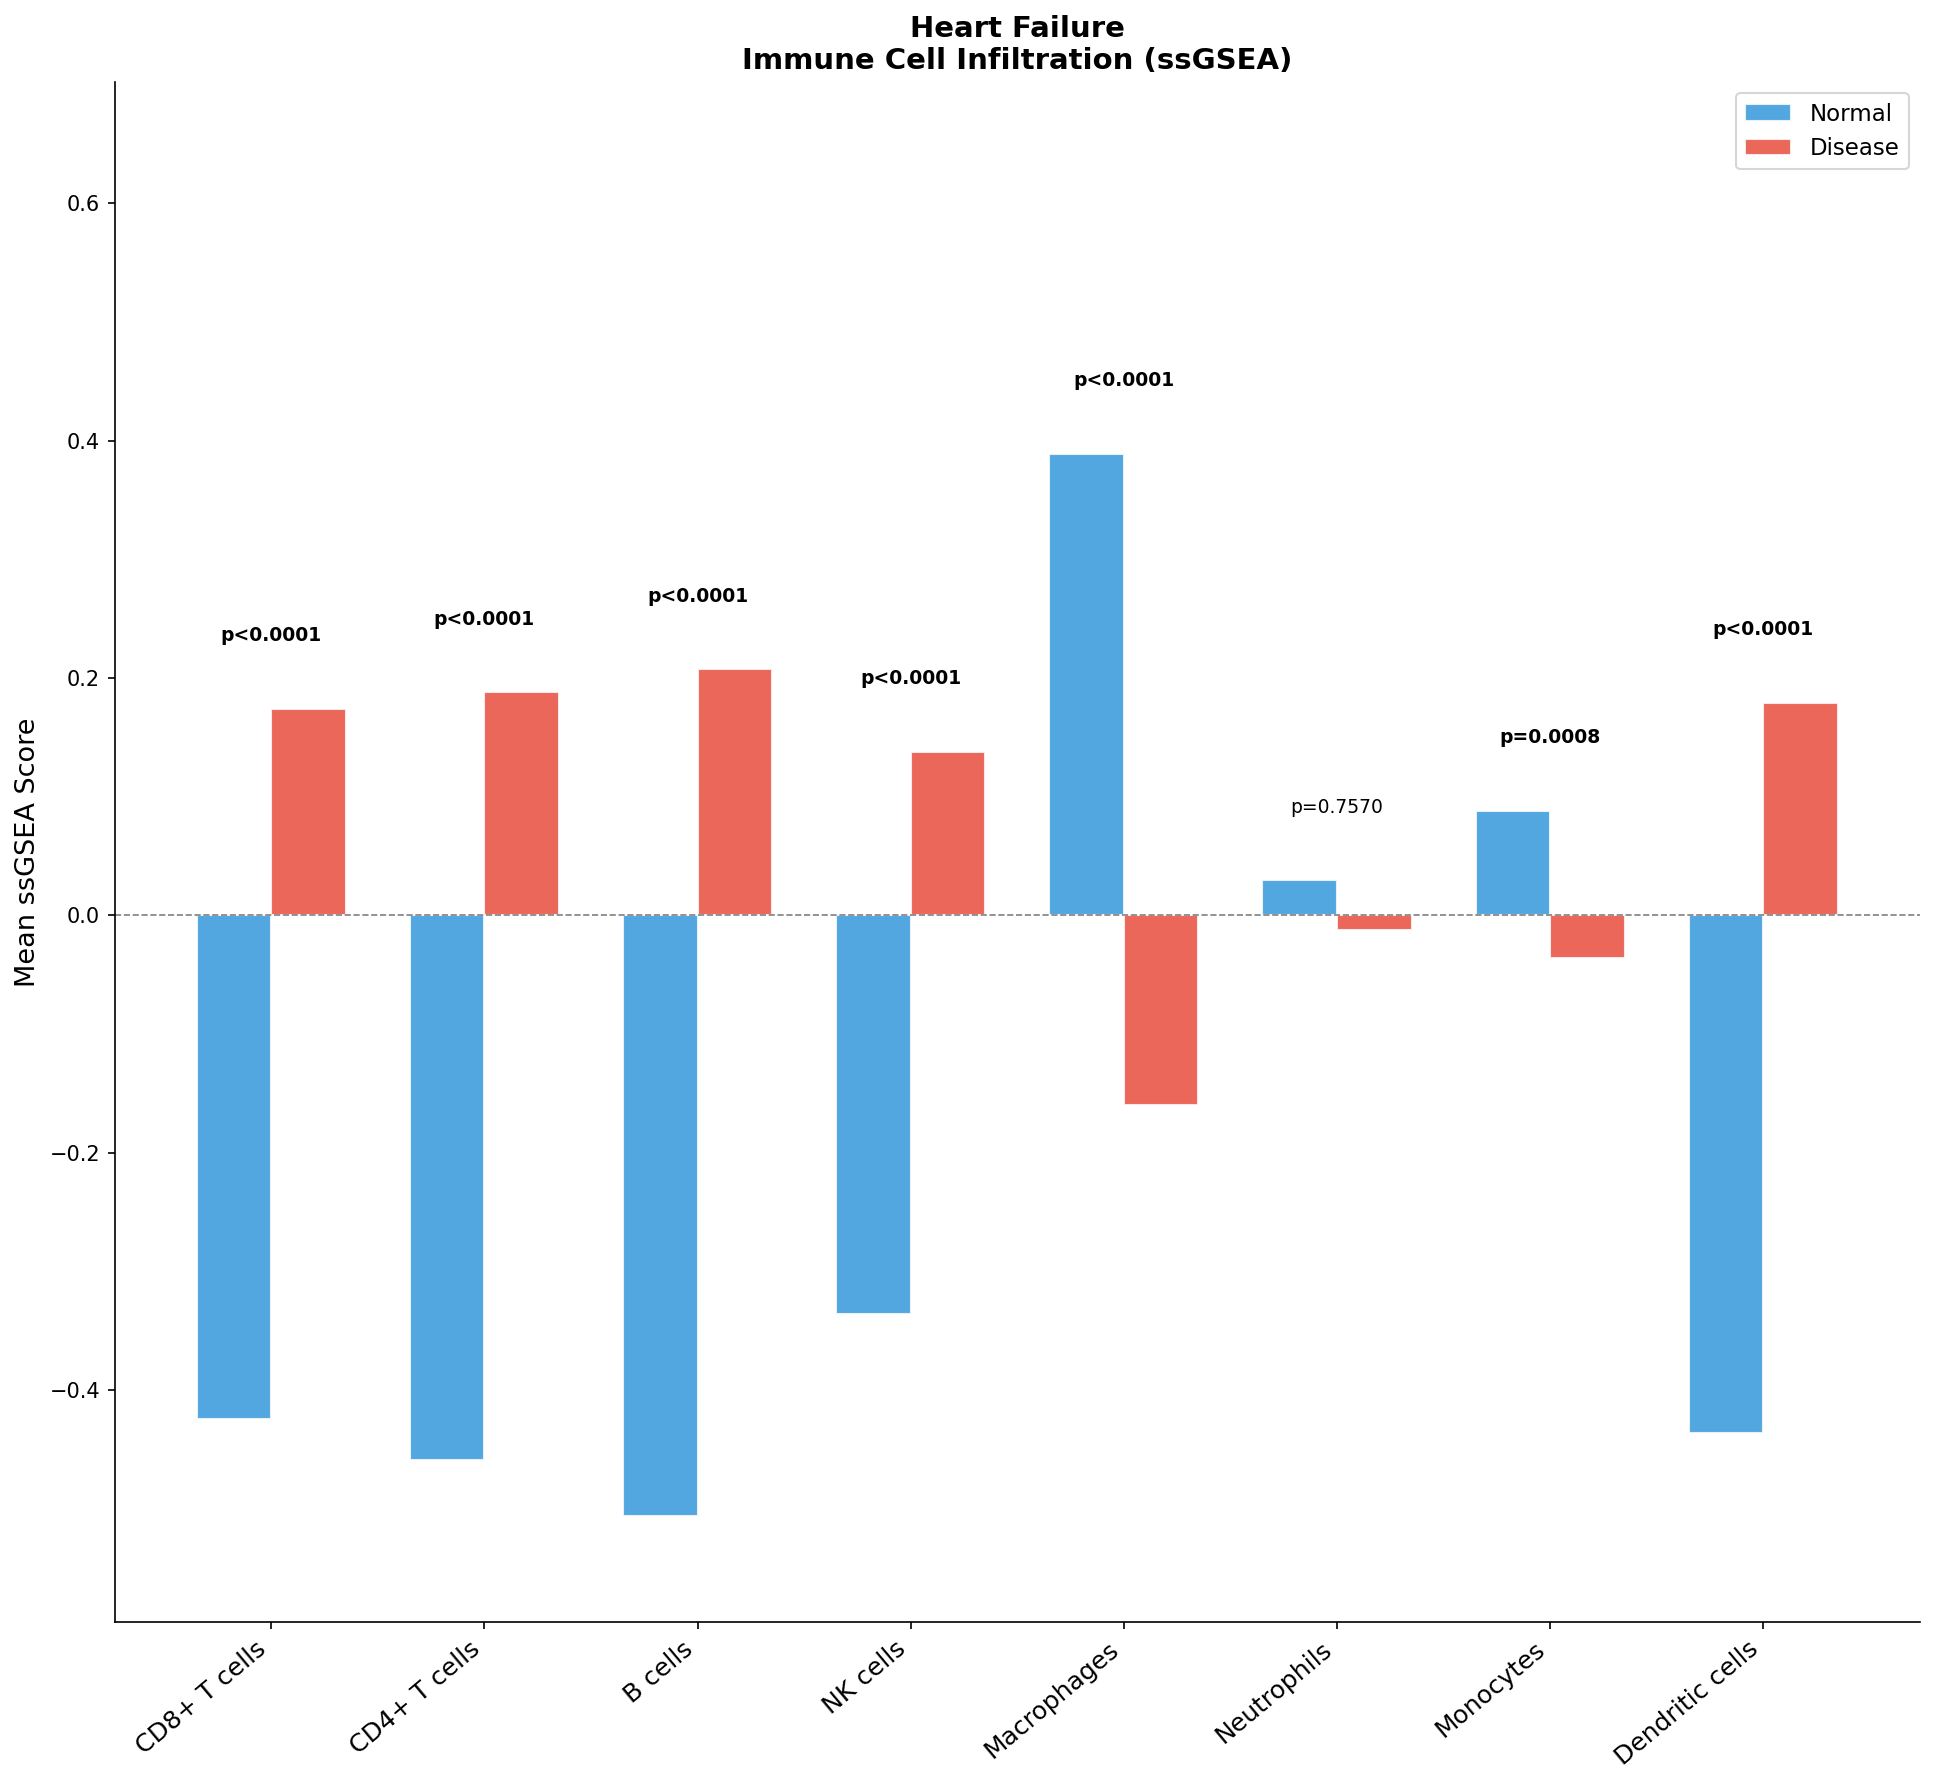

 Immune_Infiltration_HF.svg saved


In [110]:

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

immune_markers = {
    'CD8+ T cells':    ['CD8A','CD8B','GZMB','PRF1','IFNG'],
    'CD4+ T cells':    ['CD4','IL7R','TCF7','CCR7','FOXP3'],
    'B cells':         ['CD19','MS4A1','CD79A','IGHM','BLK'],
    'NK cells':        ['NCAM1','KLRB1','NKG7','GNLY','KLRD1'],
    'Macrophages':     ['CD68','CSF1R','MRC1','VSIG4','MSR1'],
    'Neutrophils':     ['S100A8','S100A9','FCGR3B','CSF3R','CXCR2'],
    'Monocytes':       ['CD14','LYZ','ITGAM','CCR2','CX3CR1'],
    'Dendritic cells': ['ITGAX','HLA-DRA','CLEC9A','CLEC4C','IRF8'],
}

def ssgsea_score(expr_df, gene_set):
    avail = [g for g in gene_set if g in expr_df.index]
    if not avail:
        return np.zeros(expr_df.shape[1])
    return expr_df.loc[avail].mean(axis=0).values

def cohens_d(a, b):
    pooled_std = np.sqrt((np.std(a, ddof=1)**2 + np.std(b, ddof=1)**2) / 2)
    if pooled_std == 0:
        return 0.0
    return (np.mean(a) - np.mean(b)) / pooled_std

for df, labels, title, c_ctrl, c_dis, fname in [
    (heart_corrected, heart_labels, 'Heart Failure', '#3498db', '#e74c3c', 'Immune_Infiltration_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(13, 12))

    labels_arr = np.array(labels)
    cell_names = list(immune_markers.keys())
    ctrl_means, dis_means, pvals, effect_sizes = [], [], [], []

    for cell, genes in immune_markers.items():
        scores = ssgsea_score(df, genes)
        ctrl_s = scores[labels_arr == 0]
        dis_s  = scores[labels_arr == 1]
        ctrl_means.append(ctrl_s.mean())
        dis_means.append(dis_s.mean())
        _, p = mannwhitneyu(ctrl_s, dis_s, alternative='two-sided')
        pvals.append(p)
        effect_sizes.append(cohens_d(dis_s, ctrl_s))

    x     = np.arange(len(cell_names))
    width = 0.35

    ax.bar(x - width/2, ctrl_means, width,
           label='Normal', color=c_ctrl, alpha=0.85, edgecolor='white')
    ax.bar(x + width/2, dis_means, width,
           label='Disease', color=c_dis, alpha=0.85, edgecolor='white')

    
    yrange = max(max(ctrl_means), max(dis_means)) - min(min(ctrl_means), min(dis_means))
    offset = yrange * 0.06

    
    for i, (p, d) in enumerate(zip(pvals, effect_sizes)):
        ymax = max(ctrl_means[i], dis_means[i])
        if p < 0.0001:
            p_text = 'p<0.0001'
        else:
            p_text = f'p={p:.4f}'
        ax.text(i, ymax + offset, p_text,
                ha='center', va='bottom', fontsize=9,
                color='black',
                fontweight='bold' if p < 0.05 else 'normal')

    
    ax.set_ylim(
        min(min(ctrl_means), min(dis_means)) - yrange * 0.1,
        max(max(ctrl_means), max(dis_means)) + yrange * 0.35
    )

    ax.set_xticks(x)
    ax.set_xticklabels(cell_names, rotation=40, ha='right', fontsize=12)
    ax.set_ylabel('Mean ssGSEA Score', fontsize=13)
    ax.set_title(f'{title}\nImmune Cell Infiltration (ssGSEA)',
                 fontweight='bold', fontsize=14)
    ax.legend(fontsize=11)
    ax.axhline(0, color='gray', lw=0.8, ls='--')

    
    print(f'\n {title}')
    print(f'  {"Cell Type":<22} {"p-value":>10} {"adj.p (BH)":>12} {"Cohen\'s d":>10} {"Significant":>12}')
    print('  ' + '-'*68)
    _, adj_p, _, _ = multipletests(pvals, method='fdr_bh')
    for cell, p, ap, d in zip(cell_names, pvals, adj_p, effect_sizes):
        sig = 'Yes' if ap < 0.05 else 'No'
        print(f'  {cell:<22} {p:>10.4f} {ap:>12.4f} {d:>10.3f} {sig:>12}')

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f' {fname} saved')



 Running GO BP enrichment — Heart Failure...
 Running KEGG enrichment — Heart Failure...
HF tables saved


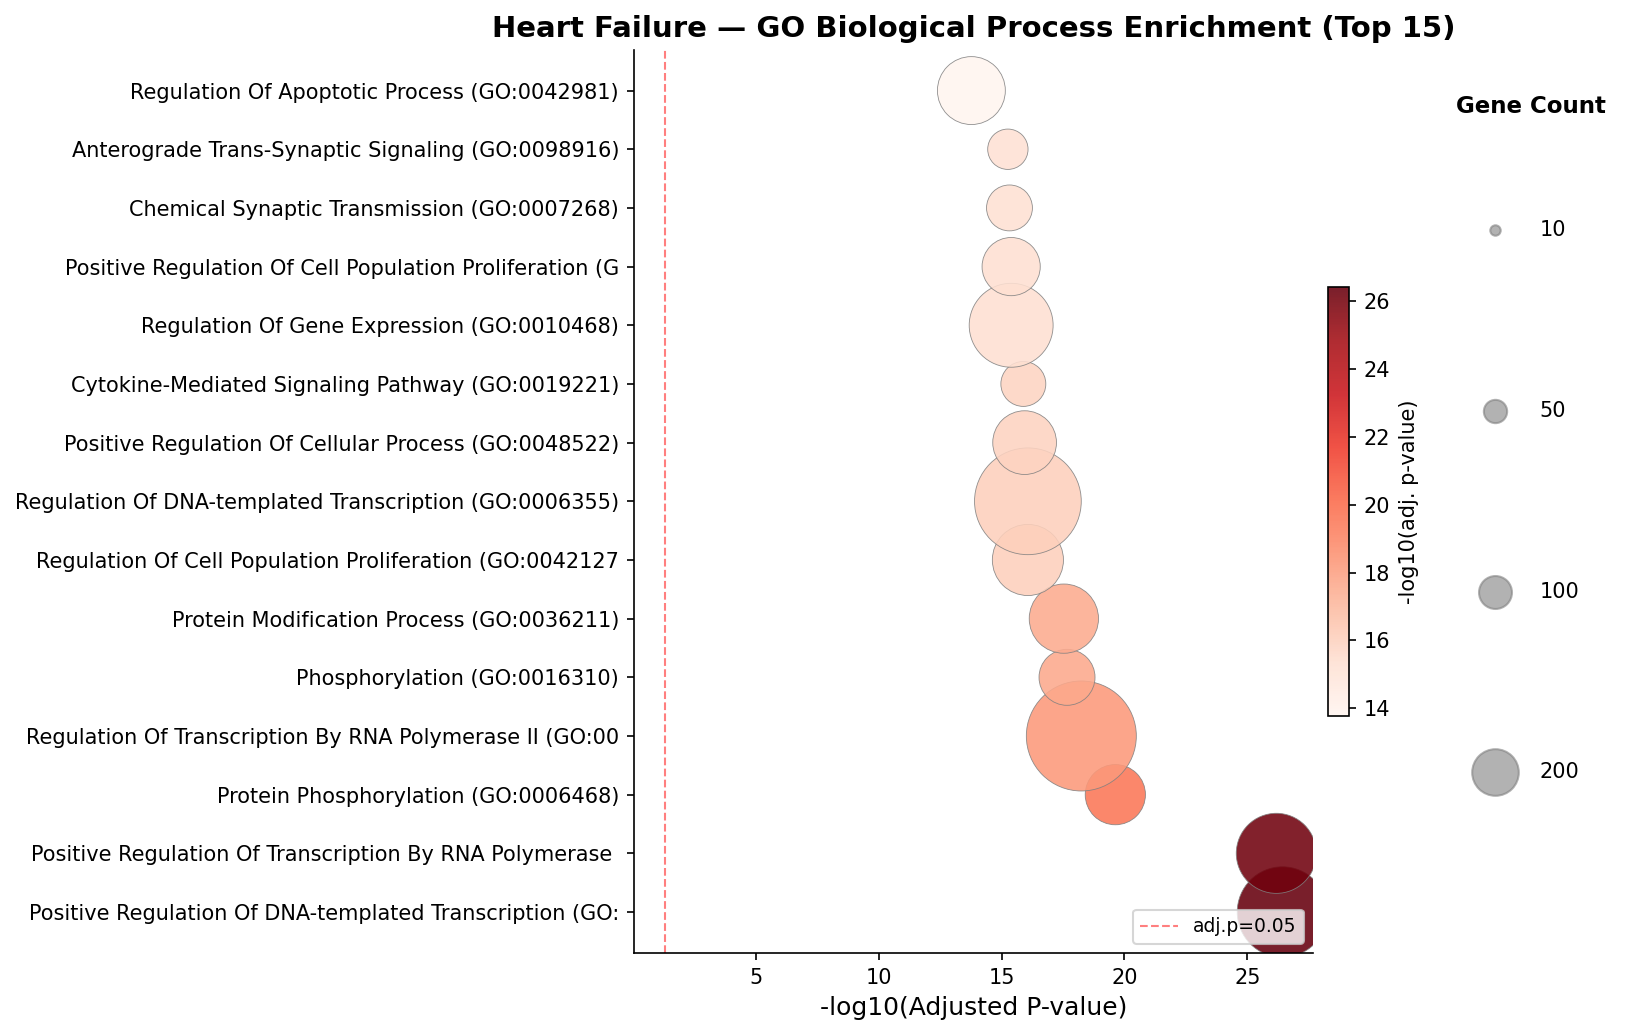

GO_BP_enrichment_HF.svg saved


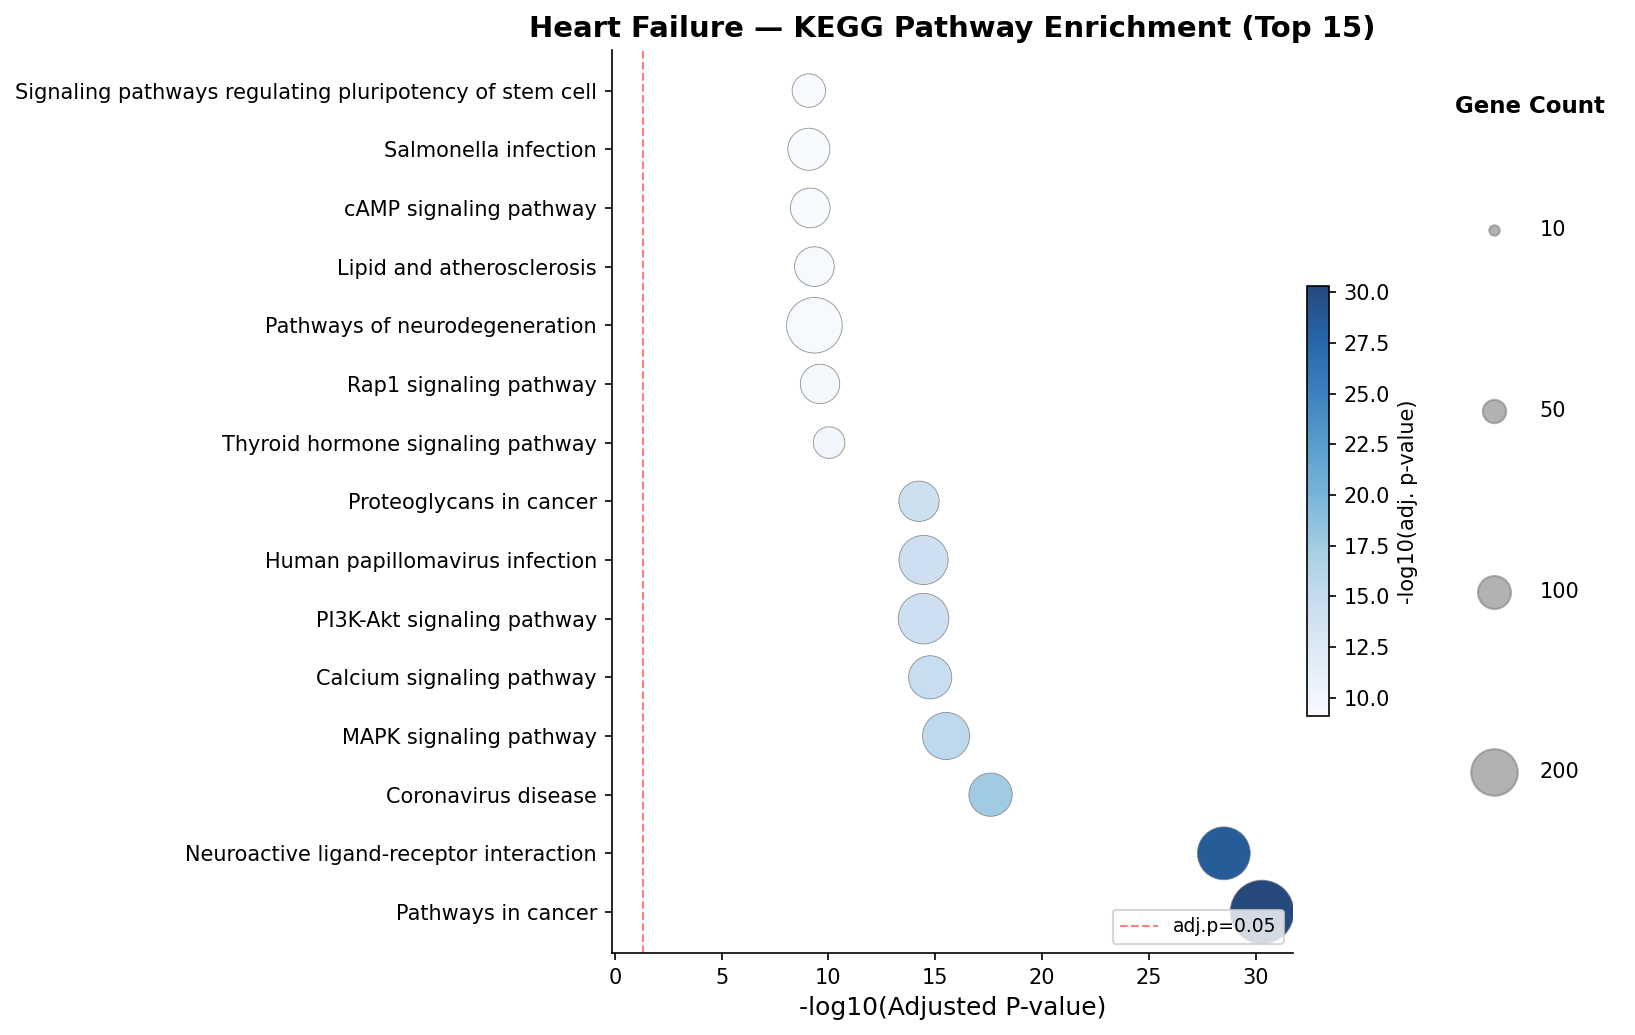

KEGG_enrichment_HF.svg saved

 Heart Failure: Top 10 GO BP Terms
                                                                     Term  Adjusted P-value
0         Positive Regulation Of DNA-templated Transcription (GO:0045893)      3.779212e-27
1  Positive Regulation Of Transcription By RNA Polymerase II (GO:0045944)      6.713448e-27
2                                    Protein Phosphorylation (GO:0006468)      2.356615e-20
3           Regulation Of Transcription By RNA Polymerase II (GO:0006357)      5.681138e-19
4                                            Phosphorylation (GO:0016310)      2.169330e-18
5                               Protein Modification Process (GO:0036211)      2.917581e-18
6                Regulation Of Cell Population Proliferation (GO:0042127)      8.457870e-17
7                  Regulation Of DNA-templated Transcription (GO:0006355)      8.457870e-17
8                    Positive Regulation Of Cellular Process (GO:0048522)      1.150946e-16
9              

In [111]:

import gseapy as gp

plt.rcParams['svg.fonttype'] = 'none'   
plt.rcParams['figure.dpi']   = 150      


heart_degs = heart_deg[heart_deg['DEG']].index.tolist()


def enrichment_bubble(results_df, title, cmap, top_n=15):
    df = results_df[results_df['Adjusted P-value'] < 0.05].head(top_n).copy()
    if df.empty:
        print(f'  [WARN] No significant terms for {title}')
        return plt.figure()
    df = df.sort_values('Adjusted P-value', ascending=True)
    df['Gene_Count'] = df['Genes'].str.split(';').str.len()
    df['-log10p']    = -np.log10(df['Adjusted P-value'])
    df['Short_Term'] = df['Term'].str[:55]

    fig, (ax, ax_leg) = plt.subplots(
        1, 2,
        figsize=(11, 7),
        gridspec_kw={'width_ratios': [4, 1]}
    )

    sc = ax.scatter(
        df['-log10p'],
        range(len(df)),
        s=df['Gene_Count'] * 2.5,
        c=df['-log10p'],
        cmap=cmap,
        alpha=0.88,
        edgecolors='gray',
        linewidth=0.4,
    )
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df['Short_Term'], fontsize=10)
    ax.set_xlabel('-log10(Adjusted P-value)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')

    cbar = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.03)
    cbar.set_label('-log10(adj. p-value)', fontsize=10)

    ax.axvline(-np.log10(0.05), color='red', ls='--',
               lw=1, alpha=0.5, label='adj.p=0.05')
    ax.legend(fontsize=9, loc='lower right')

    ax_leg.set_axis_off()
    legend_sizes = [10, 50, 100, 200]
    legend_y     = np.linspace(0.8, 0.2, len(legend_sizes))
    ax_leg.text(0.5, 0.95, 'Gene Count',
                ha='center', va='top', fontsize=11,
                fontweight='bold', transform=ax_leg.transAxes)
    for size, y in zip(legend_sizes, legend_y):
        ax_leg.scatter(0.3, y, s=size*2.5, c='gray',
                       alpha=0.6, transform=ax_leg.transAxes)
        ax_leg.text(0.55, y, str(size),
                    ha='left', va='center', fontsize=10,
                    transform=ax_leg.transAxes)

    plt.tight_layout()
    return fig


for gene_list, disease_label, tag in [
    (heart_degs, 'Heart Failure', 'HF'),
]:
    print(f'\n Running GO BP enrichment — {disease_label}...')
    go_bp = gp.enrichr(
        gene_list=gene_list,
        gene_sets='GO_Biological_Process_2023',
        organism='human',
        outdir=None,
    )

    print(f' Running KEGG enrichment — {disease_label}...')
    kegg = gp.enrichr(
        gene_list=gene_list,
        gene_sets='KEGG_2021_Human',
        organism='human',
        outdir=None,
    )

    
    go_bp.results.to_csv(SAVE / f'GO_BP_results_{tag}.csv')
    kegg.results.to_csv(SAVE  / f'KEGG_results_{tag}.csv')
    print(f'{tag} tables saved')

    
    fig_go = enrichment_bubble(
        go_bp.results,
        f'{disease_label} — GO Biological Process Enrichment (Top 15)',
        'Reds',
    )
    plt.savefig(SAVE / f'GO_BP_enrichment_{tag}.svg', format='svg', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'GO_BP_enrichment_{tag}.svg saved')

    
    fig_kegg = enrichment_bubble(
        kegg.results,
        f'{disease_label} — KEGG Pathway Enrichment (Top 15)',
        'Blues',
    )
    plt.savefig(SAVE / f'KEGG_enrichment_{tag}.svg', format='svg', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'KEGG_enrichment_{tag}.svg saved')

    # Print top 10 results
    print(f'\n {disease_label}: Top 10 GO BP Terms')
    print(go_bp.results[['Term','Adjusted P-value']].head(10).to_string())

    print(f'\n {disease_label}: Top 10 KEGG Pathways')
    print(kegg.results[['Term','Adjusted P-value']].head(10).to_string())


[WGCNA] 254 training samples (GSE57338: 145 HF / 109 Normal) x 5000 genes
[WGCNA] soft-thresholding power = 4 (signed R^2 = 0.87; target 0.85)
..cutHeight not given, setting it to 0.9983853969974049  ===>  99% of the (truncated) height range in dendro.
[WGCNA] dynamic tree cut: 21 modules -> 16 after merging (unassigned genes: 1)
        module sizes: {'turquoise': 2695, 'yellow': 446, 'brown': 396, 'green': 281, 'pink': 150, 'purple': 144, 'magenta': 144, 'salmon': 143, 'greenyellow': 138, 'cyan': 121, 'tan': 116, 'lightcyan': 48, 'lightgreen': 47, 'lightyellow': 45, 'royalblue': 45, 'darkred': 40, 'grey': 1}
[WGCNA] key module = purple  (r with HF = -0.87, p = 9.2e-78)


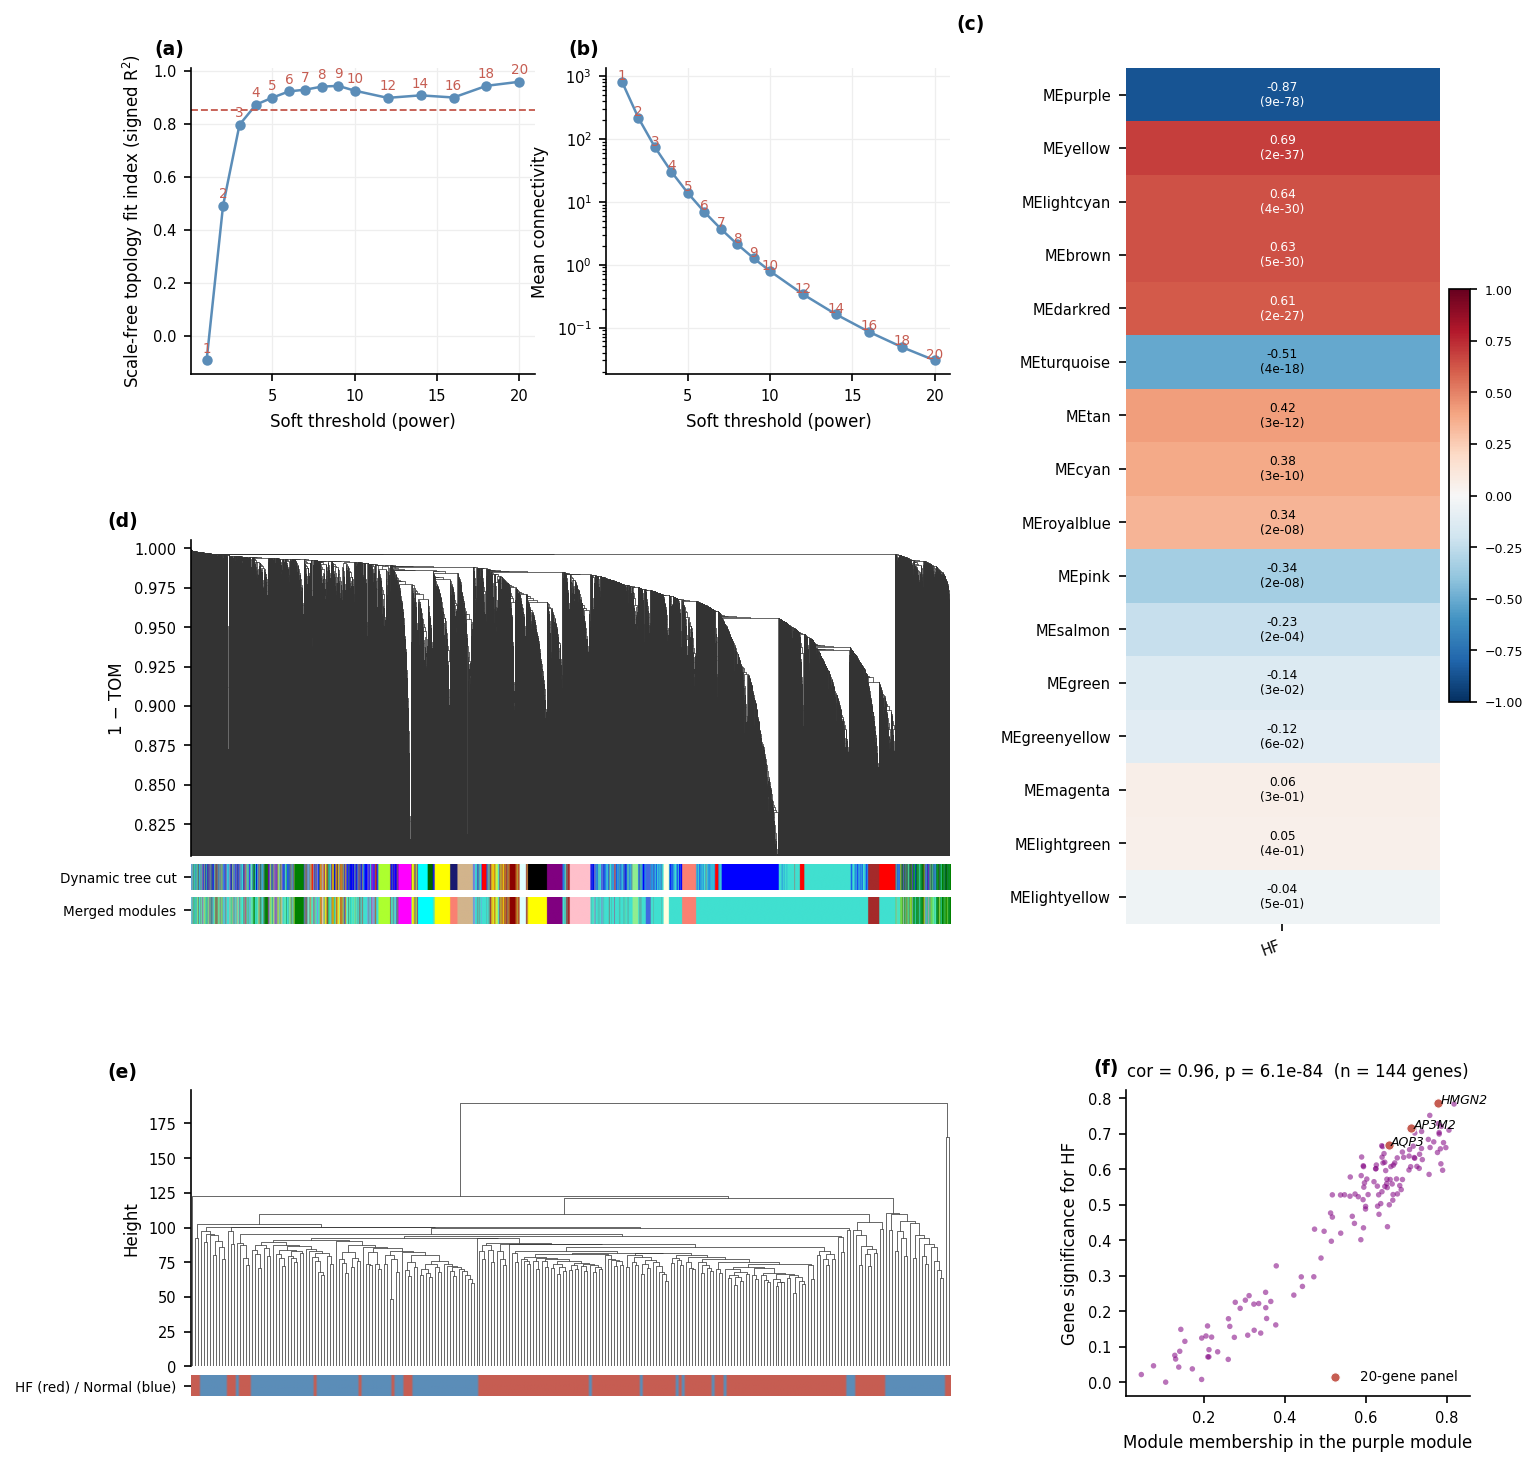

[WGCNA] hub genes (3): ['HMGN2', 'AP3M2', 'AQP3']
WGCNA done in 14s — 1 combined figure + 3 CSV saved


In [112]:

import subprocess, sys, time
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import pearsonr
from matplotlib.colors import to_rgb
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})


N_GENES    = 5000    
SFT_CUT    = 0.85    
MIN_MOD    = 30      
MERGE_CUT  = 0.25    
KEY_MODULE = 'auto'  
POWER      = None    
COHORT     = 'GSE57338'  
t0 = time.time()

try:
    from dynamicTreeCut import cutreeHybrid
except Exception:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dynamicTreeCut', 'fastcluster'], check=False)
    from dynamicTreeCut import cutreeHybrid
import dynamicTreeCut.dynamicTreeCut as _dtc      
import dynamicTreeCut.df_apply as _dfa; _dtc.df_apply = _dfa    
from scipy.stats import rankdata as _scipy_rank       
def _rank_int(a, method='average', **kw):
    r = _scipy_rank(a, method=method, **kw)
    return np.asarray(r).astype(int) if method == 'ordinal' else r
_dtc.rankdata = _rank_int                             
try:
    import fastcluster
    _link = lambda d, m='average': fastcluster.linkage(d, method=m)
except Exception:
    _link = lambda d, m='average': linkage(d, method=m)


wg_lab    = pd.Series(np.asarray(heart_labels).astype(int), index=heart_corrected.columns)
wg_cohort = pd.Series(['GSE57338'] * h1.shape[1] + ['GSE5406'] * h2.shape[1], index=heart_corrected.columns)
tr_cols   = [c for c in heart_train_cols if COHORT is None or wg_cohort[c] == COHORT]
expr      = heart_corrected[tr_cols]
y_tr      = wg_lab.loc[tr_cols].values
mad = expr.sub(expr.median(axis=1), axis=0).abs().median(axis=1)
genes = mad.sort_values(ascending=False).index[:N_GENES].tolist()
genes = list(dict.fromkeys(genes + [g for g in hf_genes if g in expr.index]))
X  = expr.loc[genes].T                                   
Xz = ((X - X.mean()) / X.std(ddof=1)).values
G  = len(genes)
print(f'[WGCNA] {X.shape[0]} training samples ({COHORT or "all cohorts"}: {int((y_tr == 1).sum())} HF / {int((y_tr == 0).sum())} Normal) x {G} genes')


absC = np.abs(np.corrcoef(Xz.T))
np.fill_diagonal(absC, 0.0)

def sft_fit(k, nb=10):
    counts, edges = np.histogram(k, bins=nb)
    idx = np.clip(np.digitize(k, edges[1:-1], right=True), 0, nb - 1)
    mids = (edges[:-1] + edges[1:]) / 2
    dk = np.array([k[idx == b].mean() if (idx == b).any() else mids[b] for b in range(nb)])
    dk = np.where(dk <= 0, mids, dk)
    pdk = counts / len(k)
    slope, intercept = np.polyfit(np.log10(dk), np.log10(pdk + 1e-9), 1)
    r = np.corrcoef(np.log10(dk), np.log10(pdk + 1e-9))[0, 1]
    return -np.sign(slope) * r ** 2                      

powers = list(range(1, 11)) + list(range(12, 22, 2))
rows = []
for p in powers:
    k = (absC ** p).sum(axis=1)
    rows.append({'Power': p, 'SFT_R2': sft_fit(k), 'Mean_connectivity': k.mean()})
sft = pd.DataFrame(rows)
if POWER is not None:
    beta = int(POWER)
else:
    ok = sft[sft['SFT_R2'] >= SFT_CUT]                       
    if not len(ok): ok = sft[sft['SFT_R2'] >= 0.80]          
    beta = int(ok['Power'].iloc[0]) if len(ok) else int(sft.loc[sft['SFT_R2'].idxmax(), 'Power'])
r2_beta = sft.loc[sft.Power == beta, 'SFT_R2'].iloc[0]
print(f'[WGCNA] soft-thresholding power = {beta} (signed R^2 = {r2_beta:.2f}; target {SFT_CUT})')
if r2_beta < SFT_CUT:
    print('        note: the scale-free fit stays below the target (common for pooled two-platform microarray data);')
    print('        report the fit honestly, or set POWER = <integer> above to use another value.')
sft.round(4).to_csv(SAVE / 'WGCNA_soft_threshold.csv', index=False)


from matplotlib.gridspec import GridSpecFromSubplotSpec
multi = COHORT is None
fig = plt.figure(figsize=(11, 11.5))
gs_main = fig.add_gridspec(3, 13, height_ratios=[1.0, 1.25, 1.0], hspace=0.5, wspace=2.2)
a1 = fig.add_subplot(gs_main[0, 0:4]); a2 = fig.add_subplot(gs_main[0, 4:8])
m1 = fig.add_subplot(gs_main[0:2, 9:13])      
_sg = GridSpecFromSubplotSpec(3, 1, subplot_spec=gs_main[1, 0:8], height_ratios=[6, 0.5, 0.5], hspace=0.06)
ax0 = fig.add_subplot(_sg[0]); ax1 = fig.add_subplot(_sg[1]); ax2 = fig.add_subplot(_sg[2])
m2 = fig.add_subplot(gs_main[2, 9:13])
_ss = GridSpecFromSubplotSpec(3 if multi else 2, 1, subplot_spec=gs_main[2, 0:8],
                              height_ratios=[6, 0.45, 0.45] if multi else [6, 0.45], hspace=0.06)
b0 = fig.add_subplot(_ss[0]); b1 = fig.add_subplot(_ss[1])
b2 = fig.add_subplot(_ss[2]) if multi else None
a1.plot(sft.Power, sft.SFT_R2, 'o-', color='#5B8DB8', lw=1.2, ms=4)
for _, r in sft.iterrows(): a1.text(r.Power, r.SFT_R2 + 0.03, str(int(r.Power)), ha='center', fontsize=6.5, color='#C65D52')
a1.axhline(SFT_CUT, color='#C65D52', ls='--', lw=0.9)
a1.set_xlabel('Soft threshold (power)', fontsize=8); a1.set_ylabel('Scale-free topology fit index (signed R$^2$)', fontsize=8)
a2.plot(sft.Power, sft.Mean_connectivity, 'o-', color='#5B8DB8', lw=1.2, ms=4)
for _, r in sft.iterrows(): a2.text(r.Power, r.Mean_connectivity * 1.08, str(int(r.Power)), ha='center', fontsize=6.5, color='#C65D52')
a2.set_yscale('log'); a2.set_xlabel('Soft threshold (power)', fontsize=8); a2.set_ylabel('Mean connectivity', fontsize=8)
for a, l in zip((a1, a2), 'ab'):
    a.tick_params(labelsize=7); a.grid(color='#EEEEEE', lw=0.6); a.set_axisbelow(True)
    a.text(-0.02, 1.03, f'({l})', transform=a.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='right')


A = absC ** beta
k = A.sum(axis=1)
TOM = (A @ A + A) / (np.minimum.outer(k, k) + 1 - A)
np.fill_diagonal(TOM, 1.0)
D = 1.0 - TOM
np.fill_diagonal(D, 0.0)
del TOM, A
Zg = _link(squareform(D, checks=False), 'average')
cut = cutreeHybrid(Zg, D, minClusterSize=MIN_MOD, deepSplit=2, pamRespectsDendro=False, verbose=0)
lab_dyn = np.asarray(cut['labels']).astype(int)           
del D

WG_COLORS = ['turquoise', 'blue', 'brown', 'yellow', 'green', 'red', 'black', 'pink', 'magenta', 'purple',
             'greenyellow', 'tan', 'salmon', 'cyan', 'midnightblue', 'lightcyan', 'lightgreen', 'lightyellow',
             'royalblue', 'darkred', 'darkgreen', 'darkturquoise', 'orange', 'skyblue', 'saddlebrown',
             'steelblue', 'paleturquoise', 'violet', 'darkolivegreen', 'darkmagenta']
sizes = pd.Series(lab_dyn[lab_dyn > 0]).value_counts()
cmap_ = {lbl: WG_COLORS[i % len(WG_COLORS)] for i, lbl in enumerate(sizes.index)}
cols_dyn = np.array([cmap_.get(l, 'grey') for l in lab_dyn], dtype=object)

def module_eigengenes(colors):
    out = {}
    for c in sorted(set(colors) - {'grey'}):
        sub = Xz[:, np.where(colors == c)[0]]
        u, s, _ = np.linalg.svd(sub, full_matrices=False)
        me = u[:, 0]
        if np.corrcoef(me, sub.mean(axis=1))[0, 1] < 0: me = -me
        out[c] = me
    return pd.DataFrame(out, index=X.index)

def merge_close(colors, cut=MERGE_CUT, max_iter=5):
    colors = colors.copy()
    for _ in range(max_iter):
        ME = module_eigengenes(colors)
        if ME.shape[1] < 2: break
        grp = fcluster(linkage(squareform(1 - ME.corr().values, checks=False), 'average'), t=cut, criterion='distance')
        if len(set(grp)) == ME.shape[1]: break
        sz = pd.Series(colors).value_counts()
        for g in set(grp):
            mods = [m for m, gg in zip(ME.columns, grp) if gg == g]
            if len(mods) > 1:
                keep = max(mods, key=lambda m: sz[m])
                for m in mods: colors[colors == m] = keep
    return colors

cols_mrg = merge_close(cols_dyn)
ME = module_eigengenes(cols_mrg)
mod_sizes = pd.Series(cols_mrg).value_counts()
print(f'[WGCNA] dynamic tree cut: {len(sizes)} modules -> {ME.shape[1]} after merging '
      f'(unassigned genes: {(cols_mrg == "grey").sum()})')
print('        module sizes:', mod_sizes.to_dict())

def thin(ax, lw=0.35):
    for coll in ax.collections: coll.set_linewidth(lw)

def draw_color_bar(ax, colors, order, label):
    ax.imshow(np.array([[to_rgb('#BBBBBB' if c == 'grey' else c) for c in np.asarray(colors)[order]]]), aspect='auto')
    ax.set_yticks([0]); ax.set_yticklabels([label], fontsize=6.5); ax.set_xticks([])
    for s in ax.spines.values(): s.set_visible(False)

_rl = sys.getrecursionlimit(); sys.setrecursionlimit(max(_rl, 30000))     
dn = dendrogram(Zg, ax=ax0, no_labels=True, color_threshold=0, above_threshold_color='#333333')
order_g = np.array(dn['leaves'])
thin(ax0)
ax0.set_ylim(max(0, np.percentile(Zg[:, 2], 1) - 0.02), 1.005)   
ax0.set_ylabel('1 − TOM', fontsize=8); ax0.tick_params(labelsize=7); ax0.set_xticks([])
for s in ('bottom',): ax0.spines[s].set_visible(False)
draw_color_bar(ax1, cols_dyn, order_g, 'Dynamic tree cut')
draw_color_bar(ax2, cols_mrg, order_g, 'Merged modules')
sys.setrecursionlimit(_rl)


Zs = linkage(Xz, 'average')
dns = dendrogram(Zs, ax=b0, no_labels=True, color_threshold=0, above_threshold_color='#333333')
order_s = np.array(dns['leaves'])
thin(b0)
b0.set_ylabel('Height', fontsize=8); b0.tick_params(labelsize=7); b0.set_xticks([])
b0.spines['bottom'].set_visible(False)
hf_col = np.where(y_tr == 1, '#C65D52', '#5B8DB8')
co_col = np.where(wg_cohort.loc[tr_cols].values == 'GSE5406', '#F2B84B', '#8E7CC3')
draw_color_bar(b1, hf_col, order_s, 'HF (red) / Normal (blue)')
if multi:
    draw_color_bar(b2, co_col, order_s, 'GSE5406 (orange) / GSE57338 (purple)')


traits = pd.DataFrame({'HF': y_tr}, index=X.index)
if COHORT is None:
    traits['Cohort (GSE5406)'] = (wg_cohort.loc[tr_cols].values == 'GSE5406').astype(int)
mt_r = pd.DataFrame({t: [pearsonr(ME[m], traits[t])[0] for m in ME.columns] for t in traits}, index=ME.columns)
mt_p = pd.DataFrame({t: [pearsonr(ME[m], traits[t])[1] for m in ME.columns] for t in traits}, index=ME.columns)
order_m = mt_r['HF'].abs().sort_values(ascending=False).index
mt_r, mt_p = mt_r.loc[order_m], mt_p.loc[order_m]
km = KEY_MODULE
if km != 'auto' and km not in mt_r.index:
    print(f'[WGCNA] module "{km}" does not exist after merging; available: {list(mt_r.index)} -> using the automatic choice')
    km = 'auto'
key = mt_r['HF'].abs().idxmax() if km == 'auto' else km
print(f'[WGCNA] key module = {key}  (r with HF = {mt_r.loc[key, "HF"]:+.2f}, p = {mt_p.loc[key, "HF"]:.1e})')
mt_r.add_prefix('r_').join(mt_p.add_prefix('p_')).rename_axis('Module').to_csv(SAVE / 'WGCNA_module_trait.csv')

gene_df = pd.DataFrame({'Gene': genes, 'Module': cols_mrg})
gene_df['kME_own'] = [np.corrcoef(Xz[:, i], ME[m].values)[0, 1] if m != 'grey' else np.nan
                      for i, m in enumerate(cols_mrg)]
gene_df['GS_HF'] = [np.corrcoef(Xz[:, i], y_tr)[0, 1] for i in range(G)]
gene_df['kME_key'] = [np.corrcoef(Xz[:, i], ME[key].values)[0, 1] for i in range(G)]
gene_df['In_panel'] = gene_df['Gene'].isin(hf_genes)
gene_df.round(4).to_csv(SAVE / 'WGCNA_gene_module_membership.csv', index=False)

im = m1.imshow(mt_r.values, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
m1.set_xticks(range(mt_r.shape[1])); m1.set_xticklabels(mt_r.columns, fontsize=7, rotation=20, ha='right')
m1.set_yticks(range(mt_r.shape[0])); m1.set_yticklabels(['ME' + m for m in mt_r.index], fontsize=7)
for i in range(mt_r.shape[0]):
    for j in range(mt_r.shape[1]):
        m1.text(j, i, f'{mt_r.iat[i, j]:.2f}\n({mt_p.iat[i, j]:.0e})', ha='center', va='center', fontsize=5.8,
                color='white' if abs(mt_r.iat[i, j]) > 0.55 else 'black')
for s in m1.spines.values(): s.set_visible(False)
plt.colorbar(im, ax=m1, fraction=0.06, pad=0.03).ax.tick_params(labelsize=6)
sub = gene_df[gene_df.Module == key]
mm, gs_ = sub['kME_own'].abs(), sub['GS_HF'].abs()
r_, p_ = pearsonr(mm, gs_)
m2.scatter(mm, gs_, s=7, color=('#2E5FA8' if key == 'blue' else key), alpha=0.55, edgecolors='none')
pan = sub[sub.In_panel]
m2.scatter(pan['kME_own'].abs(), pan['GS_HF'].abs(), s=20, color='#C65D52', edgecolors='white', lw=0.5, label='20-gene panel')
for _, rr in pan.sort_values('GS_HF', key=abs, ascending=False).head(6).iterrows():
    m2.text(abs(rr.kME_own) + 0.005, abs(rr.GS_HF), rr.Gene, fontsize=6, fontstyle='italic')
m2.set_xlabel(f'Module membership in the {key} module', fontsize=8)
m2.set_ylabel('Gene significance for HF', fontsize=8)
m2.set_title(f'cor = {r_:.2f}, p = {p_:.1e}  (n = {len(sub)} genes)', fontsize=8)
m2.legend(frameon=False, fontsize=6.5, loc='lower right')
for a, l in zip((m1, m2), 'cf'):
    a.tick_params(labelsize=7)
    a.text(-0.02 if a is m2 else -0.45, 1.04, f'({l})', transform=a.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='right')
for a, l in zip((ax0, b0), 'de'):
    a.text(-0.07, 1.03, f'({l})', transform=a.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='right')
plt.savefig(SAVE / 'WGCNA_combined_figure.svg', format='svg', bbox_inches='tight')
plt.savefig(SAVE / 'WGCNA_combined_figure.png', format='png', bbox_inches='tight', dpi=300)
plt.show()


wgcna_hub_genes = (gene_df[(gene_df.Module == key) & gene_df.In_panel]
                   .assign(_a=lambda d: d['kME_own'].abs()).sort_values('_a', ascending=False)['Gene'].tolist())
print(f'[WGCNA] hub genes ({len(wgcna_hub_genes)}): {wgcna_hub_genes}')

wg = {'genes': genes, 'colors': cols_mrg, 'ME': ME, 'key': key, 'gene_df': gene_df, 'beta': beta}   
print(f'WGCNA done in {time.time() - t0:.0f}s — 1 combined figure + 3 CSV saved')

Total hub genes: 3 -> ['HMGN2', 'AP3M2', 'AQP3']


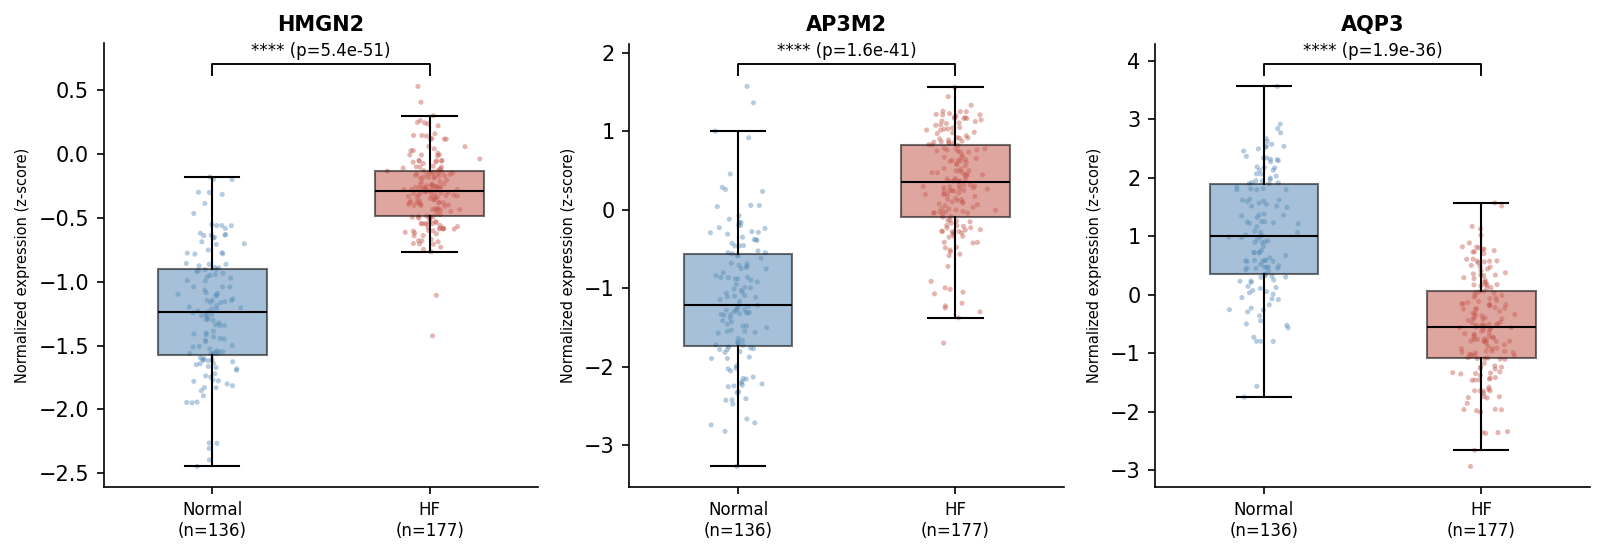

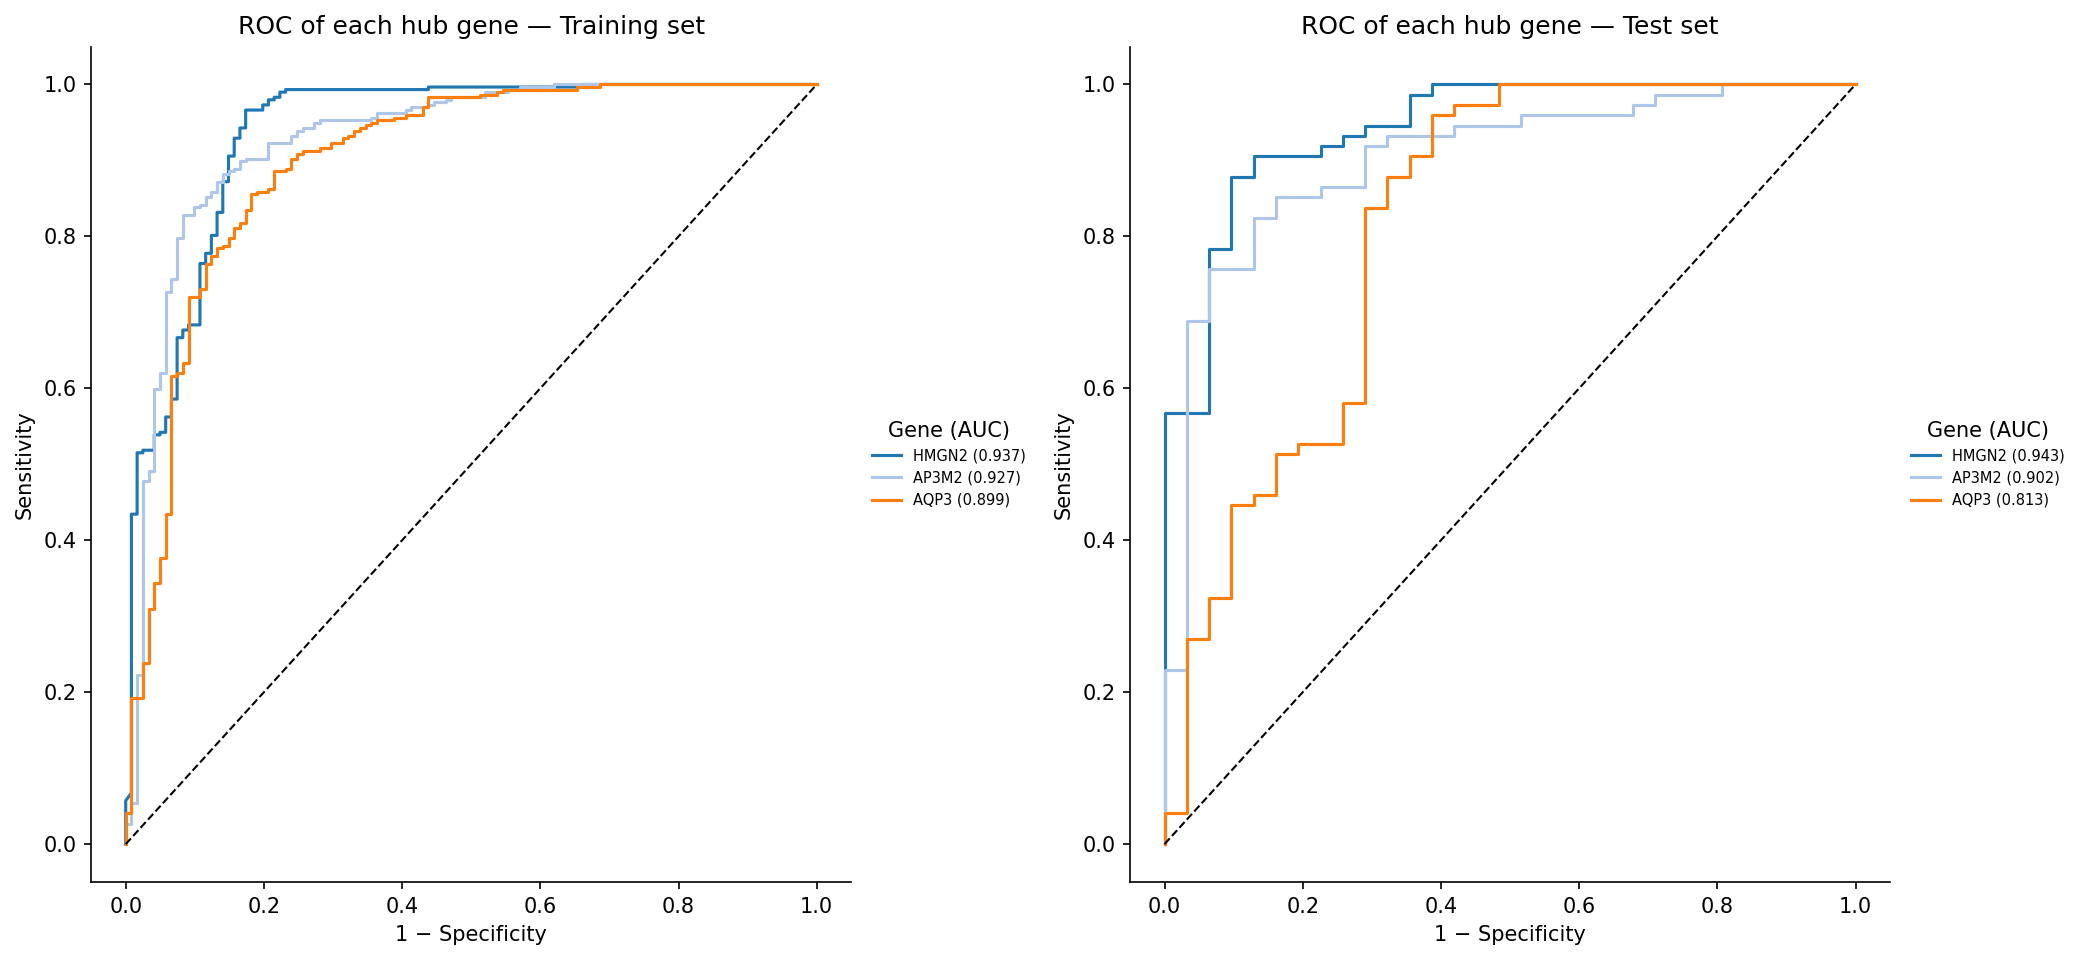

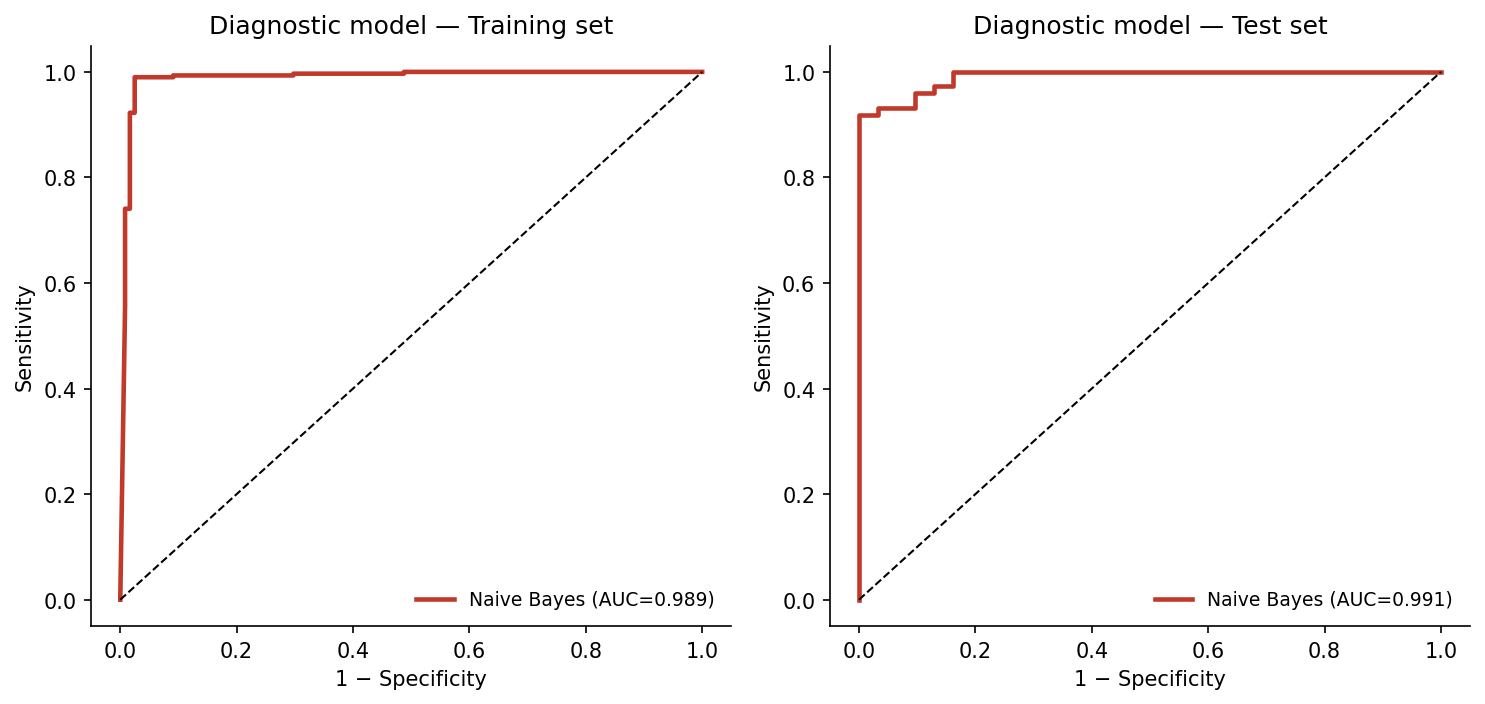

       p_value  mean_HF  mean_Normal  AUC_training  AUC_test
Gene                                                        
HMGN2      0.0  -0.2926      -1.2324        0.9370    0.9433
AP3M2      0.0   0.3162      -1.1428        0.9272    0.9024
AQP3       0.0  -0.5454       1.0530        0.8993    0.8134
Saved. 3 hub genes | model: Naive Bayes | expression cohort: GSE57338


In [113]:

from scipy.stats import ttest_ind
from sklearn.metrics import roc_curve, roc_auc_score

plt.rcParams['svg.fonttype'] = 'none'


EXPR_COHORT = 'GSE57338'     
N_COLS      = 5              
C_NORMAL, C_HF = '#5B8DB8', '#C65D52'

hubs = list(wgcna_hub_genes)   
assert len(hubs) > 0, 'no hub genes found'
print(f'Total hub genes: {len(hubs)} -> {hubs}')
lab_all  = np.asarray(heart_labels).astype(int)
n_all    = heart_corrected.shape[1]
if EXPR_COHORT == 'GSE57338':
    cohort_mask = np.arange(n_all) < len(labels_h1)
elif EXPR_COHORT == 'GSE5406':
    cohort_mask = np.arange(n_all) >= len(labels_h1)
else:
    cohort_mask = np.ones(n_all, dtype=bool)

def stars(p):
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'

def gene_roc(g, cols, y):
    s = heart_corrected.loc[g, cols].values.astype(float)
    auc = roc_auc_score(y, s)
    if auc < 0.5:                       
        s, auc = -s, 1 - auc
    fpr, tpr, _ = roc_curve(y, s)
    return fpr, tpr, auc


ncols = min(N_COLS, len(hubs)); nrows = int(np.ceil(len(hubs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.8 * nrows), squeeze=False)
stat_rows = []
rng = np.random.RandomState(42)
for ax in axes.ravel():
    ax.axis('off')
for ax, g in zip(axes.ravel(), hubs):
    ax.axis('on')
    v  = heart_corrected.loc[g].values.astype(float)
    vn = v[cohort_mask & (lab_all == 0)]
    vh = v[cohort_mask & (lab_all == 1)]
    bp = ax.boxplot([vn, vh], positions=[0, 1], widths=0.5, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black'))
    for patch, c in zip(bp['boxes'], [C_NORMAL, C_HF]):
        patch.set_facecolor(c); patch.set_alpha(0.55)
    ax.scatter(rng.normal(0, 0.06, len(vn)), vn, s=6, color=C_NORMAL, alpha=0.45, edgecolors='none')
    ax.scatter(rng.normal(1, 0.06, len(vh)), vh, s=6, color=C_HF, alpha=0.45, edgecolors='none')
    _, p = ttest_ind(vh, vn, equal_var=False)
    top = max(vn.max(), vh.max()); rv = top - min(vn.min(), vh.min())
    ax.plot([0, 0, 1, 1], [top + 0.03*rv, top + 0.06*rv, top + 0.06*rv, top + 0.03*rv], 'k', lw=0.9)
    ax.text(0.5, top + 0.07*rv, f'{stars(p)} (p={p:.1e})', ha='center', va='bottom', fontsize=8)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f'Normal\n(n={len(vn)})', f'HF\n(n={len(vh)})'], fontsize=8)
    ax.set_title(g, fontweight='bold', fontsize=10)
    ax.set_ylabel('Normalized expression (z-score)', fontsize=7)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    stat_rows.append({'Gene': g, 'p_value': p, 'mean_HF': vh.mean(), 'mean_Normal': vn.mean()})
plt.tight_layout()
plt.savefig(SAVE / 'Hub_gene_expression_all.svg', format='svg', bbox_inches='tight')
plt.show()


cmap = plt.get_cmap('tab20')
y_tr, y_te = np.asarray(heart_ytr), np.asarray(heart_yte)
auc_rows = {g: {} for g in hubs}
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, cols, y, nm in [(axes[0], heart_train_cols, y_tr, 'Training set'),
                        (axes[1], heart_test_cols,  y_te, 'Test set')]:
    for i, g in enumerate(hubs):
        fpr, tpr, auc = gene_roc(g, cols, y)
        auc_rows[g][f'AUC_{nm.split()[0].lower()}'] = auc
        ax.plot(fpr, tpr, color=cmap(i % 20), lw=1.5, label=f'{g} ({auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('1 − Specificity'); ax.set_ylabel('Sensitivity')
    ax.set_title(f'ROC of each hub gene — {nm}')
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=7, frameon=False, title='Gene (AUC)', ncol=1 if len(hubs) <= 20 else 2)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'Hub_gene_ROC_all.svg', format='svg', bbox_inches='tight')
plt.show()


best_name  = hf_results.iloc[0]['Model']
best_model = hf_models[best_name]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, Xm, y, nm in [(axes[0], hf_Xtr, np.asarray(hf_ytr), 'Training set'),
                      (axes[1], hf_Xte, np.asarray(hf_yte), 'Test set')]:
    yp = best_model.predict_proba(Xm)[:, 1]
    fpr, tpr, _ = roc_curve(y, yp)
    ax.plot(fpr, tpr, color='#C0392B', lw=2.2, label=f'{best_name} (AUC={roc_auc_score(y, yp):.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('1 − Specificity'); ax.set_ylabel('Sensitivity')
    ax.set_title(f'Diagnostic model — {nm}'); ax.legend(loc='lower right', fontsize=9, frameon=False)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'Diagnostic_model_ROC.svg', format='svg', bbox_inches='tight')
plt.show()


summ = pd.DataFrame(stat_rows).set_index('Gene').join(pd.DataFrame(auc_rows).T)
summ.to_csv(SAVE / 'Hub_gene_validation_summary.csv')
print(summ.round(4).to_string())
print(f'Saved. {len(hubs)} hub genes | model: {best_name} | expression cohort: {EXPR_COHORT or "all"}')

Training Deep Learning models...
       (MLP + 1D-CNN × Heart Failure)

  Heart Failure — MLP: AUC=0.993 [0.978-1.000]
  Heart Failure — 1D-CNN: AUC=0.993 [0.980-1.000]


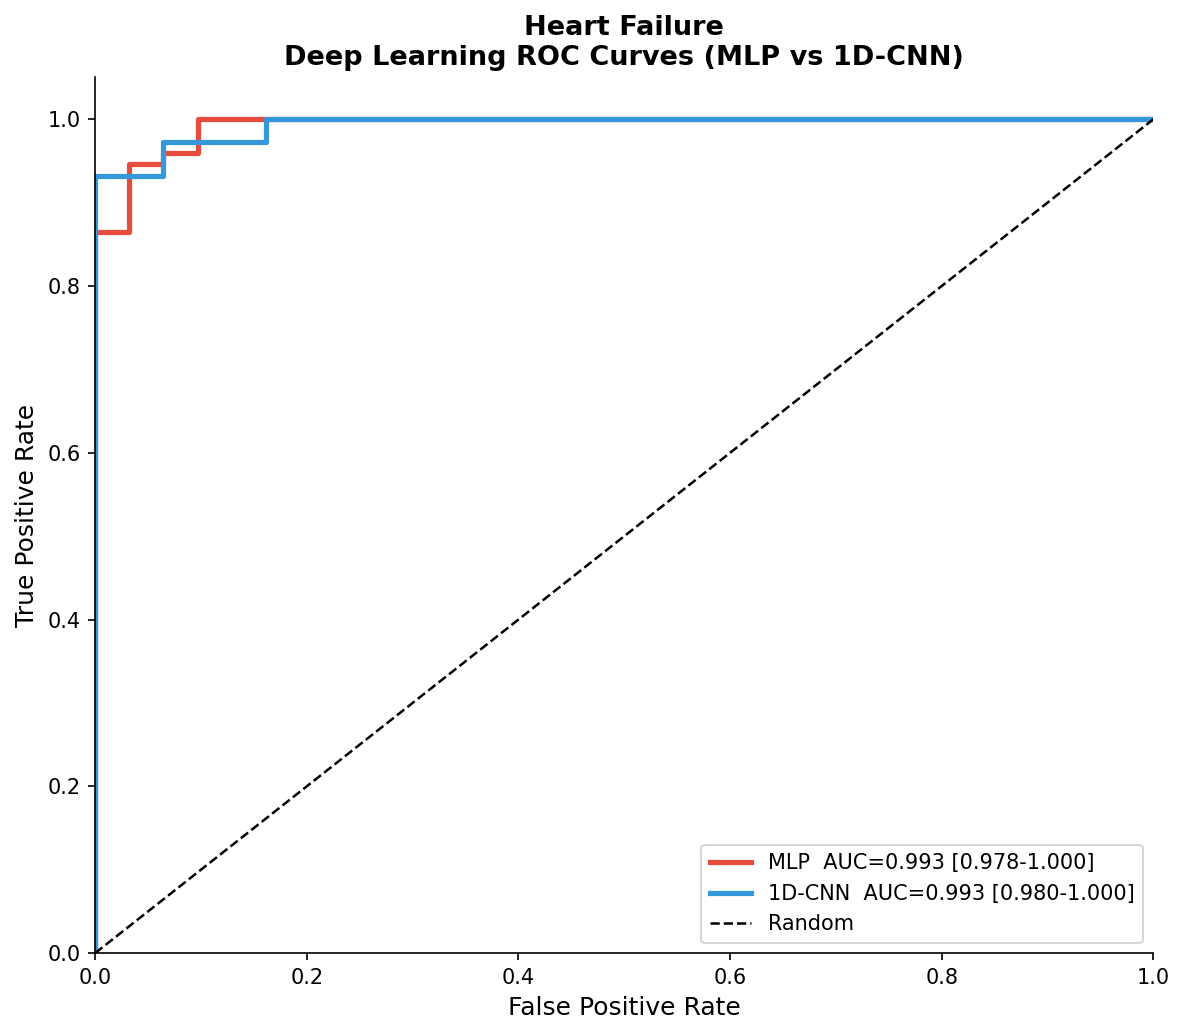

 DL_ROC_curves_HF.svg saved


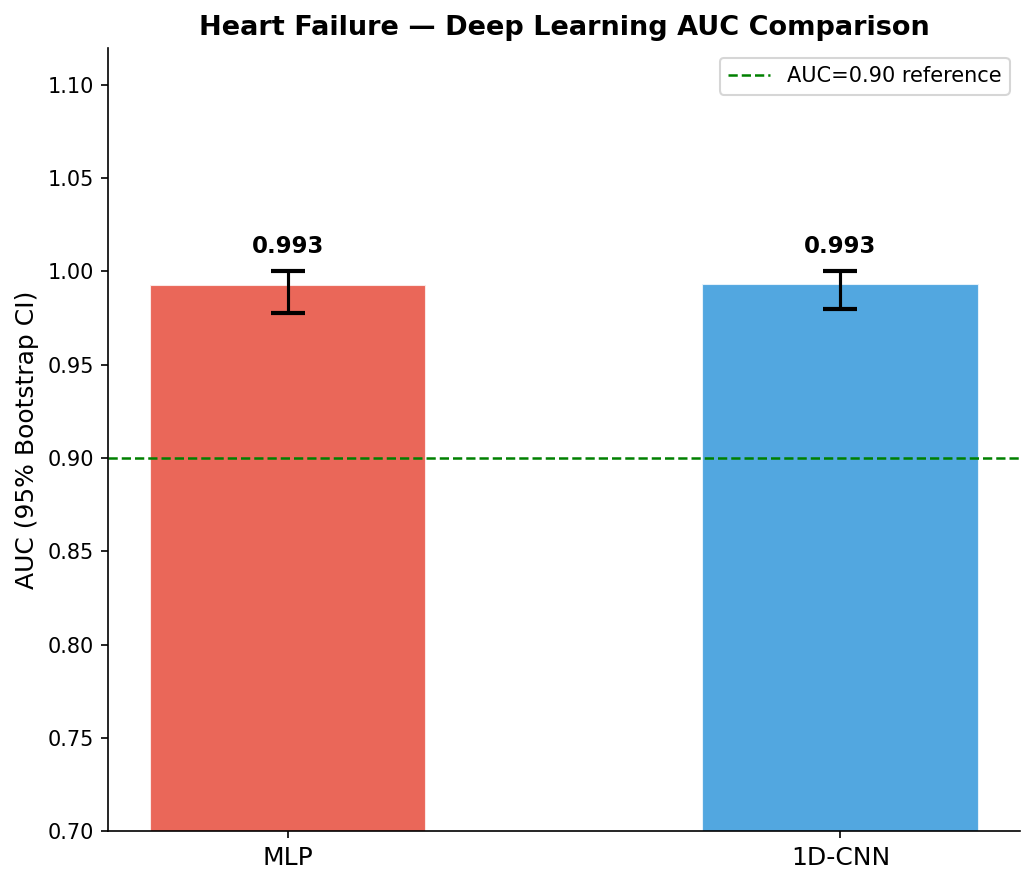

 DL_AUC_comparison_HF.svg saved

 Deep Learning Summary
  Disease          Model         AUC   CI_lo   CI_hi
  --------------------------------------------------
  Heart Failure    MLP         0.993   0.978   1.000
  Heart Failure    1D-CNN      0.993   0.980   1.000
DL_summary.csv saved


In [114]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, f1_score, matthews_corrcoef, confusion_matrix


class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64),        nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32),         nn.ReLU(),
            nn.Linear(32, 1),          nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

class CNN1D(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
        )
        self.fc = nn.Sequential(
            nn.Linear(128 * input_dim, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1), nn.Sigmoid(),
        )
    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv(x)
        return self.fc(x.view(x.size(0), -1))


def train_dl(Xtr, Xte, ytr, yte, ModelClass, epochs=60, lr=0.001):
    torch.manual_seed(42)
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)
    Xte_t = torch.tensor(Xte, dtype=torch.float32)

    loader    = DataLoader(TensorDataset(Xtr_t, ytr_t),
                           batch_size=32, shuffle=True)
    model     = ModelClass(Xtr.shape[1])
    optimizer = torch.optim.Adam(model.parameters(),
                                 lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(
                    optimizer, step_size=20, gamma=0.5)

    
    pos_weight = torch.tensor([(ytr==0).sum() / (ytr==1).sum()],
                               dtype=torch.float32)
    criterion  = nn.BCELoss()

    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()

    model.eval()
    with torch.no_grad():
        y_prob = model(Xte_t).squeeze().numpy()

    auc = roc_auc_score(yte, y_prob)
    fpr, tpr, _ = roc_curve(yte, y_prob)
    y_pred = (y_prob >= 0.5).astype(int)
    acc    = accuracy_score(yte, y_pred)
    f1     = f1_score(yte, y_pred, zero_division=0)
    mcc    = matthews_corrcoef(yte, y_pred)
    tn, fp, fn, tp = confusion_matrix(yte, y_pred).ravel()
    sens   = tp / (tp + fn + 1e-9)
    spec   = tn / (tn + fp + 1e-9)

    # Bootstrap 95% CI
    rng  = np.random.default_rng(42)
    boot = []
    for _ in range(1000):
        idx = rng.choice(len(yte), len(yte), replace=True)
        if len(np.unique(yte[idx])) > 1:
            boot.append(roc_auc_score(yte[idx], y_prob[idx]))
    ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

    return auc, ci_lo, ci_hi, fpr, tpr, y_prob, acc, sens, spec, f1, mcc


print('Training Deep Learning models...')
print('       (MLP + 1D-CNN × Heart Failure)\n')

diseases = ['Heart Failure']
dl_results = {}
for disease, Xtr, Xte, ytr, yte in [
    ('Heart Failure', hf_Xtr, hf_Xte, hf_ytr, hf_yte),
]:
    dl_results[disease] = {}
    for arch_name, Arch in [('MLP', MLP), ('1D-CNN', CNN1D)]:
        auc, ci_lo, ci_hi, fpr, tpr, y_prob, acc, sens, spec, f1, mcc = train_dl(
            Xtr.astype(np.float32),
            Xte.astype(np.float32),
            ytr.astype(np.float32),
            yte.astype(np.float32),
            Arch,
        )
        dl_results[disease][arch_name] = {
            'auc': auc, 'ci_lo': ci_lo, 'ci_hi': ci_hi,
            'fpr': fpr, 'tpr': tpr, 'y_prob': y_prob,
            'accuracy': acc, 'sensitivity': sens, 'specificity': spec,
            'f1': f1, 'mcc': mcc,
        }
        print(f'  {disease} — {arch_name}: '
              f'AUC={auc:.3f} [{ci_lo:.3f}-{ci_hi:.3f}]')


DL_COLORS = {'MLP': '#e74c3c', '1D-CNN': '#3498db'}

for disease, yte, fname in [
    ('Heart Failure', hf_yte, 'DL_ROC_curves_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(8, 7))
    for arch_name, res in dl_results[disease].items():
        ax.plot(res['fpr'], res['tpr'],
                color=DL_COLORS[arch_name], lw=2.5,
                label=f"{arch_name}  AUC={res['auc']:.3f} "
                      f"[{res['ci_lo']:.3f}-{res['ci_hi']:.3f}]")
    ax.plot([0,1],[0,1], 'k--', lw=1.2, label='Random')
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title(f'{disease}\nDeep Learning ROC Curves (MLP vs 1D-CNN)',
                 fontweight='bold', fontsize=13)
    ax.legend(fontsize=10)
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1.05])

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f' {fname} saved')


archs    = ['MLP', '1D-CNN']
bar_cols = ['#e74c3c', '#3498db']

for disease, fname in [
    ('Heart Failure', 'DL_AUC_comparison_HF.svg'),
]:
    fig, ax = plt.subplots(figsize=(7, 6))
    x = np.arange(len(archs))
    aucs   = [dl_results[disease][a]['auc']   for a in archs]
    ci_los = [dl_results[disease][a]['ci_lo'] for a in archs]
    ci_his = [dl_results[disease][a]['ci_hi'] for a in archs]

    bars = ax.bar(x, aucs, width=0.5, color=bar_cols, alpha=0.85, edgecolor='white')
    ax.errorbar(x, aucs,
                yerr=[[a-l for a,l in zip(aucs,ci_los)],
                      [h-a for a,h in zip(aucs,ci_his)]],
                fmt='none', color='black', capsize=8, capthick=2)
    for j, (auc, ci_hi) in enumerate(zip(aucs, ci_his)):
        ax.text(x[j], ci_hi + 0.01, f'{auc:.3f}', ha='center',
                fontsize=11, fontweight='bold')

    ax.axhline(0.9, color='green', ls='--', lw=1.2, label='AUC=0.90 reference')
    ax.set_xticks(x)
    ax.set_xticklabels(archs, fontsize=12)
    ax.set_ylabel('AUC (95% Bootstrap CI)', fontsize=12)
    ax.set_title(f'{disease} — Deep Learning AUC Comparison',
                 fontsize=13, fontweight='bold')
    ax.set_ylim([0.7, 1.12])
    ax.legend(fontsize=10)

    plt.tight_layout()
    plt.savefig(SAVE / fname, format='svg', bbox_inches='tight')
    plt.show()
    print(f' {fname} saved')


print('\n Deep Learning Summary')
print(f'  {"Disease":<16} {"Model":<10} {"AUC":>6} {"CI_lo":>7} {"CI_hi":>7}')
print('  ' + '-'*50)
for disease in diseases:
    for arch in archs:
        r = dl_results[disease][arch]
        print(f'  {disease:<16} {arch:<10} '
              f'{r["auc"]:>6.3f} {r["ci_lo"]:>7.3f} {r["ci_hi"]:>7.3f}')


rows = []
for disease in diseases:
    for arch in archs:
        r = dl_results[disease][arch]
        rows.append({'Disease': disease, 'Model': arch,
                     'AUC': r['auc'], 'CI_lo': r['ci_lo'], 'CI_hi': r['ci_hi'],
                     'Accuracy': r['accuracy'], 'Sensitivity': r['sensitivity'],
                     'Specificity': r['specificity'], 'F1': r['f1'], 'MCC': r['mcc']})
pd.DataFrame(rows).to_csv(SAVE / 'DL_summary.csv', index=False)
print('DL_summary.csv saved')


In [115]:

import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from scipy.stats import friedmanchisquare


class ResMLP(nn.Module):
    """ResNet-style tabular network (Gorishniy et al., NeurIPS 2021)."""
    def __init__(self, input_dim, d=64, n_blocks=2, drop=0.2):
        super().__init__()
        self.inp = nn.Linear(input_dim, d)
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.BatchNorm1d(d), nn.Linear(d, 2 * d), nn.ReLU(), nn.Dropout(drop),
                          nn.Linear(2 * d, d), nn.Dropout(drop))
            for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.BatchNorm1d(d), nn.ReLU(), nn.Linear(d, 1), nn.Sigmoid())
    def forward(self, x):
        h = self.inp(x)
        for blk in self.blocks:
            h = h + blk(h)                      
        return self.head(h)

class FTTransformer(nn.Module):
    """Feature-Tokenizer Transformer (Gorishniy et al., NeurIPS 2021), small version: one token per gene."""
    def __init__(self, input_dim, d=16, n_layers=2, n_heads=2, drop=0.1):
        super().__init__()
        self.w = nn.Parameter(torch.randn(input_dim, d) * 0.1)   
        self.b = nn.Parameter(torch.zeros(input_dim, d))         
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.1)      
        layer = nn.TransformerEncoderLayer(d_model=d, nhead=n_heads, dim_feedforward=2 * d,
                                           dropout=drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 1), nn.Sigmoid())
    def forward(self, x):
        tok = x.unsqueeze(-1) * self.w + self.b                  
        tok = torch.cat([self.cls.expand(x.size(0), -1, -1), tok], dim=1)
        return self.head(self.enc(tok)[:, 0])                    


dl_extra = {}
for arch_name, Arch in [('ResMLP', ResMLP), ('FT-Transformer', FTTransformer)]:
    auc, ci_lo, ci_hi, fpr, tpr, y_prob, acc, sens, spec, f1, mcc = train_dl(
        hf_Xtr.astype(np.float32), hf_Xte.astype(np.float32),
        hf_ytr.astype(np.float32), hf_yte.astype(np.float32), Arch)
    dl_extra[arch_name] = {'auc': auc, 'ci_lo': ci_lo, 'ci_hi': ci_hi, 'fpr': fpr, 'tpr': tpr,
                           'y_prob': y_prob, 'accuracy': acc, 'sensitivity': sens,
                           'specificity': spec, 'f1': f1, 'mcc': mcc}
    print(f'  {arch_name}: test AUC = {auc:.3f} [{ci_lo:.3f}-{ci_hi:.3f}]')


X_all = heart_corrected[heart_train_cols].T[hf_genes].values
y_all = np.asarray(hf_ytr)
skf   = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
dl_arch = {'MLP': MLP, '1D-CNN': CNN1D, 'ResMLP': ResMLP, 'FT-Transformer': FTTransformer}

dl_cv = {}
for arch_name, Arch in dl_arch.items():
    aucs = []
    for k, (tr, va) in enumerate(skf.split(X_all, y_all)):
        sc = StandardScaler()
        Xtr_k = sc.fit_transform(X_all[tr]).astype(np.float32)    
        Xva_k = sc.transform(X_all[va]).astype(np.float32)
        out = train_dl(Xtr_k, Xva_k, y_all[tr].astype(np.float32), y_all[va].astype(np.float32), Arch)
        aucs.append(float(out[0]))
    dl_cv[arch_name] = np.array(aucs)
    print(f'  {arch_name}: 5-fold CV AUC = {dl_cv[arch_name].mean():.3f} ± {dl_cv[arch_name].std():.3f}   '
          f'folds = {[round(a, 3) for a in aucs]}')


all_cv = {**hf_cv, **dl_cv}
chi2, p = friedmanchisquare(*all_cv.values())
print(f'\nFriedman ({len(all_cv)} models, 5 folds): chi2 = {chi2:.3f}, p = {p:.4f}')


rows = []
for m in dl_arch:
    r = dl_results['Heart Failure'][m] if m in dl_results['Heart Failure'] else dl_extra[m]
    rows.append({'Model': m, 'CV_AUC_mean': dl_cv[m].mean(), 'CV_AUC_std': dl_cv[m].std(),
                 'Test_AUC': r['auc'], 'Test_AUC_CI_lo': r['ci_lo'], 'Test_AUC_CI_hi': r['ci_hi'],
                 'Accuracy': r['accuracy'], 'Sensitivity': r['sensitivity'],
                 'Specificity': r['specificity'], 'F1': r['f1'], 'MCC': r['mcc']})
dl4 = pd.DataFrame(rows).sort_values('CV_AUC_mean', ascending=False).reset_index(drop=True)
print('\n Deep-learning models: 5-fold CV (training set) + held-out test set')
print(dl4.round(3).to_string(index=False))

dl4.round(3).to_csv(SAVE / 'DL_4models_CV_and_test.csv', index=False)
pd.DataFrame(all_cv).assign(fold=range(1, 6)).to_csv(SAVE / 'CV_fold_AUCs_12models.csv', index=False)
pd.DataFrame([{'Friedman_chi2': round(chi2, 3), 'p_value': round(p, 6), 'n_models': len(all_cv), 'n_folds': 5}]
             ).to_csv(SAVE / 'statistical_validation_12models.csv', index=False)
print('DL_4models_CV_and_test.csv, CV_fold_AUCs_12models.csv, statistical_validation_12models.csv saved')

  ResMLP: test AUC = 0.992 [0.978-1.000]
  FT-Transformer: test AUC = 0.986 [0.960-1.000]
  MLP: 5-fold CV AUC = 0.984 ± 0.015   folds = [0.974, 1.0, 0.993, 0.994, 0.96]
  1D-CNN: 5-fold CV AUC = 0.986 ± 0.015   folds = [0.979, 1.0, 0.994, 0.996, 0.959]
  ResMLP: 5-fold CV AUC = 0.988 ± 0.016   folds = [0.997, 1.0, 0.991, 0.995, 0.956]
  FT-Transformer: 5-fold CV AUC = 0.970 ± 0.025   folds = [0.95, 1.0, 0.985, 0.982, 0.931]

Friedman (12 models, 5 folds): chi2 = 20.777, p = 0.0358

 Deep-learning models: 5-fold CV (training set) + held-out test set
         Model  CV_AUC_mean  CV_AUC_std  Test_AUC  Test_AUC_CI_lo  Test_AUC_CI_hi  Accuracy  Sensitivity  Specificity    F1   MCC
        ResMLP        0.988       0.016     0.992           0.978             1.0     0.962        1.000        0.871 0.974 0.909
        1D-CNN        0.986       0.015     0.993           0.980             1.0     0.952        0.973        0.903 0.966 0.885
           MLP        0.984       0.015     0.993     

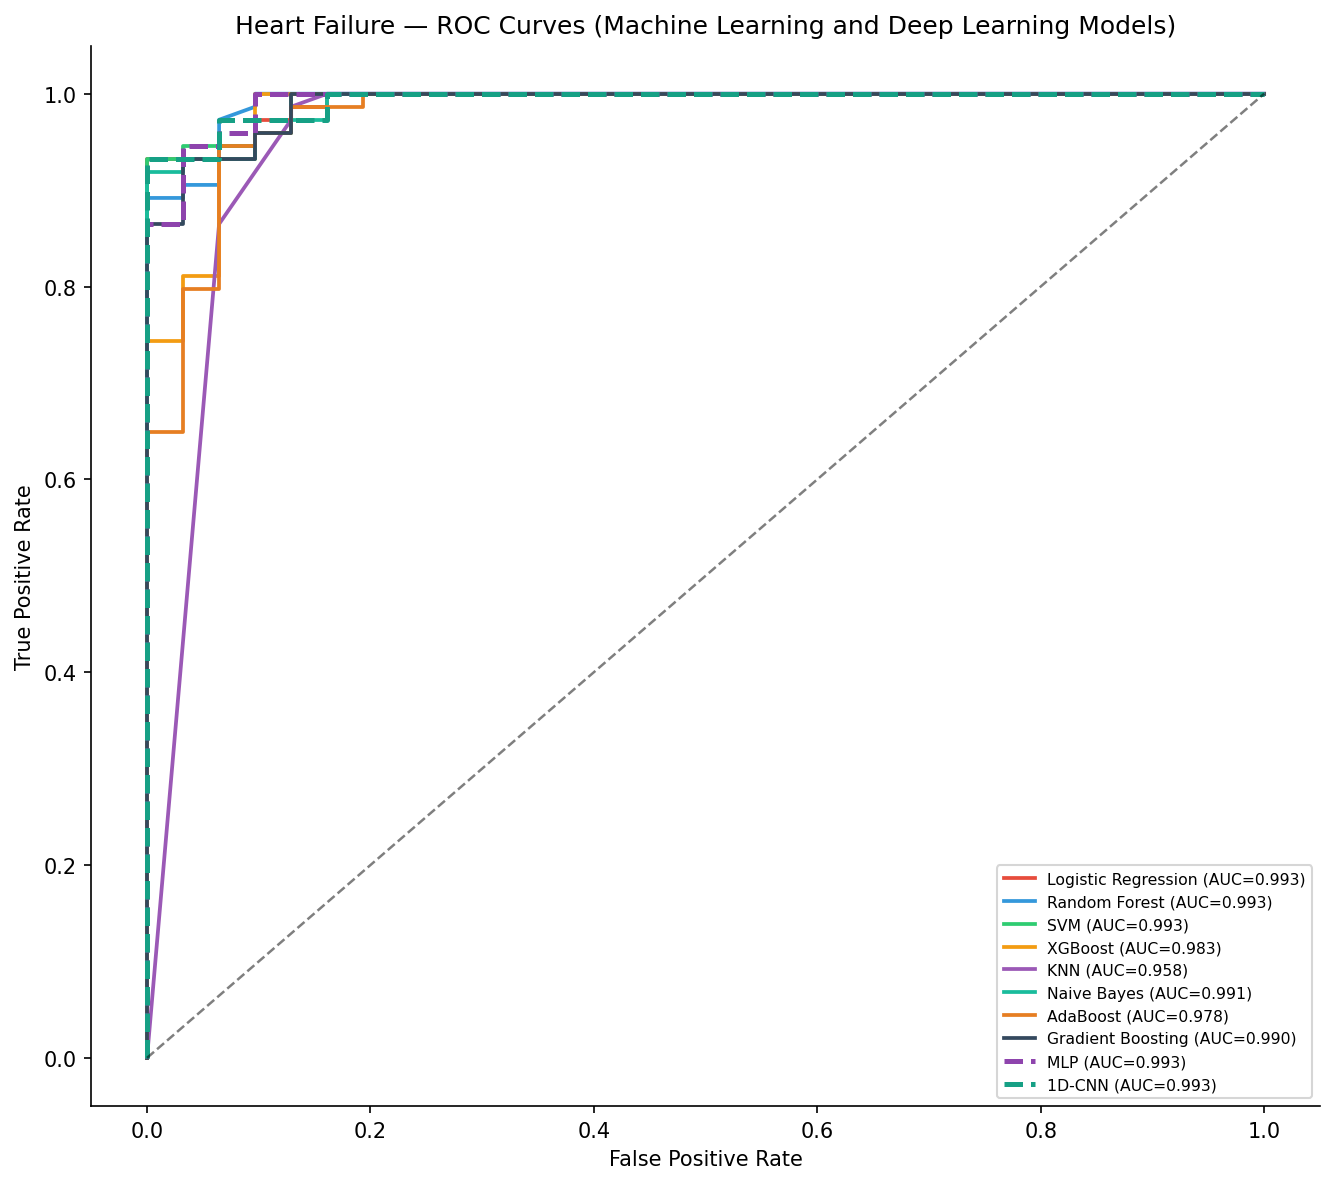

ROC_curves_HF_all10.svg saved


In [116]:

COLORS = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6','#1abc9c','#e67e22','#34495e']
DL_COLORS = {'MLP': '#8e44ad', '1D-CNN': '#16a085'}

fig, ax = plt.subplots(figsize=(9, 8))


for (mname, model), col in zip(hf_models.items(), COLORS):
    yp = model.predict_proba(hf_Xte)[:,1]
    fpr, tpr, _ = roc_curve(hf_yte, yp)
    auc = roc_auc_score(hf_yte, yp)
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f'{mname} (AUC={auc:.3f})')


for arch_name, dl_col in DL_COLORS.items():
    res = dl_results['Heart Failure'][arch_name]
    ax.plot(res['fpr'], res['tpr'], color=dl_col, lw=2.4, ls='--',
            label=f'{arch_name} (AUC={res["auc"]:.3f})')

ax.plot([0,1],[0,1],'k--', lw=1.2, alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Heart Failure — ROC Curves (Machine Learning and Deep Learning Models)')
ax.legend(loc='lower right', fontsize=7.5)

plt.tight_layout()
plt.savefig(SAVE / 'ROC_curves_HF_all10.svg', format='svg', bbox_inches='tight')
plt.show()
print('ROC_curves_HF_all10.svg saved')

In [117]:

from sklearn.metrics import brier_score_loss

y_te = np.asarray(hf_yte).astype(int)
DL_ALL = {**dl_results['Heart Failure'], **dl_extra}
DL_NAMES = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']


probs12 = {m: hf_models[m].predict_proba(hf_Xte)[:, 1] for m in hf_models}
for m in DL_NAMES:
    probs12[m] = np.asarray(DL_ALL[m]['y_prob']).ravel()
assert len(probs12) == 12, f'expected 12 models, found {len(probs12)}'


cv12 = {**hf_cv, **dl_cv}

ci12   = {m: bootstrap_ci(y_te, pr) for m, pr in probs12.items()}
brier  = {m: brier_score_loss(y_te, pr) for m, pr in probs12.items()}
cls_tb = hf_results.set_index('Model')

rows = []
for m in probs12:
    if m in cls_tb.index:
        r = cls_tb.loc[m]
        typ, auc, acc, sens, spec, f1, mcc = ('Classical ML', r['AUC'], r['Accuracy'], r['Sensitivity'],
                                              r['Specificity'], r['F1'], r['MCC'])
    else:
        r = DL_ALL[m]
        typ, auc, acc, sens, spec, f1, mcc = ('Deep learning', r['auc'], r['accuracy'], r['sensitivity'],
                                              r['specificity'], r['f1'], r['mcc'])
    rows.append({'Model': m, 'Type': typ,
                 'CV_AUC_mean': cv12[m].mean(), 'CV_AUC_std': cv12[m].std(),
                 'Test_AUC': auc, 'Test_AUC_CI_lo': ci12[m][0], 'Test_AUC_CI_hi': ci12[m][1],
                 'Accuracy': acc, 'Sensitivity': sens, 'Specificity': spec,
                 'F1': f1, 'MCC': mcc, 'Brier_score': brier[m]})
master12 = (pd.DataFrame(rows).sort_values('CV_AUC_mean', ascending=False)
            .reset_index(drop=True).round(3))
master12.to_csv(SAVE / 'HF_12models_master_table.csv', index=False)


pd.DataFrame([{'Disease': 'Heart Failure', 'Model': m,
               'CI_lo': round(ci12[m][0], 3), 'CI_hi': round(ci12[m][1], 3)} for m in probs12]
             ).to_csv(SAVE / 'bootstrap_CI_12models.csv', index=False)
pd.DataFrame([{'Model': m,
               'HF CV AUC': f'{cv12[m].mean():.3f} ± {cv12[m].std():.3f}',
               'HF Test AUC 95% CI': f'[{ci12[m][0]:.3f}-{ci12[m][1]:.3f}]'} for m in probs12]
             ).to_csv(SAVE / 'CV_AUC_summary_12models.csv', index=False)


brier12 = pd.DataFrame({'Model': list(brier), 'Brier_score': [round(v, 4) for v in brier.values()]})
brier12.to_csv(SAVE / 'Brier_scores_HF_12models.csv', index=False)

print('Heart Failure: 12-model master table (ranked by 5-fold CV AUC on the training set)')
print(master12.to_string(index=False))
print('\n HF_12models_master_table.csv, bootstrap_CI_12models.csv, CV_AUC_summary_12models.csv, Brier_scores_HF_12models.csv saved')


Heart Failure: 12-model master table (ranked by 5-fold CV AUC on the training set)
              Model          Type  CV_AUC_mean  CV_AUC_std  Test_AUC  Test_AUC_CI_lo  Test_AUC_CI_hi  Accuracy  Sensitivity  Specificity    F1   MCC  Brier_score
        Naive Bayes  Classical ML        0.990       0.013     0.991           0.976           0.999     0.943        0.959        0.903 0.959 0.863        0.053
             ResMLP Deep learning        0.988       0.016     0.992           0.978           1.000     0.962        1.000        0.871 0.974 0.909        0.034
      Random Forest  Classical ML        0.987       0.016     0.993           0.980           1.000     0.971        1.000        0.903 0.980 0.932        0.032
  Gradient Boosting  Classical ML        0.987       0.012     0.990           0.974           0.999     0.962        1.000        0.871 0.974 0.909        0.038
             1D-CNN Deep learning        0.986       0.015     0.993           0.980           1.000     0.

Friedman (12 models, 5 folds): chi2 = 20.777, p = 0.0358
Nemenyi critical difference (alpha = 0.05) = 7.45 rank units

              Model  Mean_rank  Mean_CV_AUC
        Naive Bayes        2.9        0.990
             1D-CNN        4.5        0.986
             ResMLP        4.9        0.988
      Random Forest        5.5        0.987
                MLP        5.6        0.984
                KNN        5.7        0.984
Logistic Regression        6.6        0.982
  Gradient Boosting        7.2        0.987
            XGBoost        7.8        0.984
           AdaBoost        8.1        0.985
                SVM        8.7        0.981
     FT-Transformer       10.5        0.970

Significant pairs (Nemenyi p < 0.05): 1 of 66
    Model_A        Model_B  Rank_diff  p_value  Significant_0.05
Naive Bayes FT-Transformer        7.6   0.0408              True

Smallest 5 pairwise p-values:
    Model_A        Model_B  Rank_diff  p_value  Significant_0.05
Naive Bayes FT-Transformer        7.

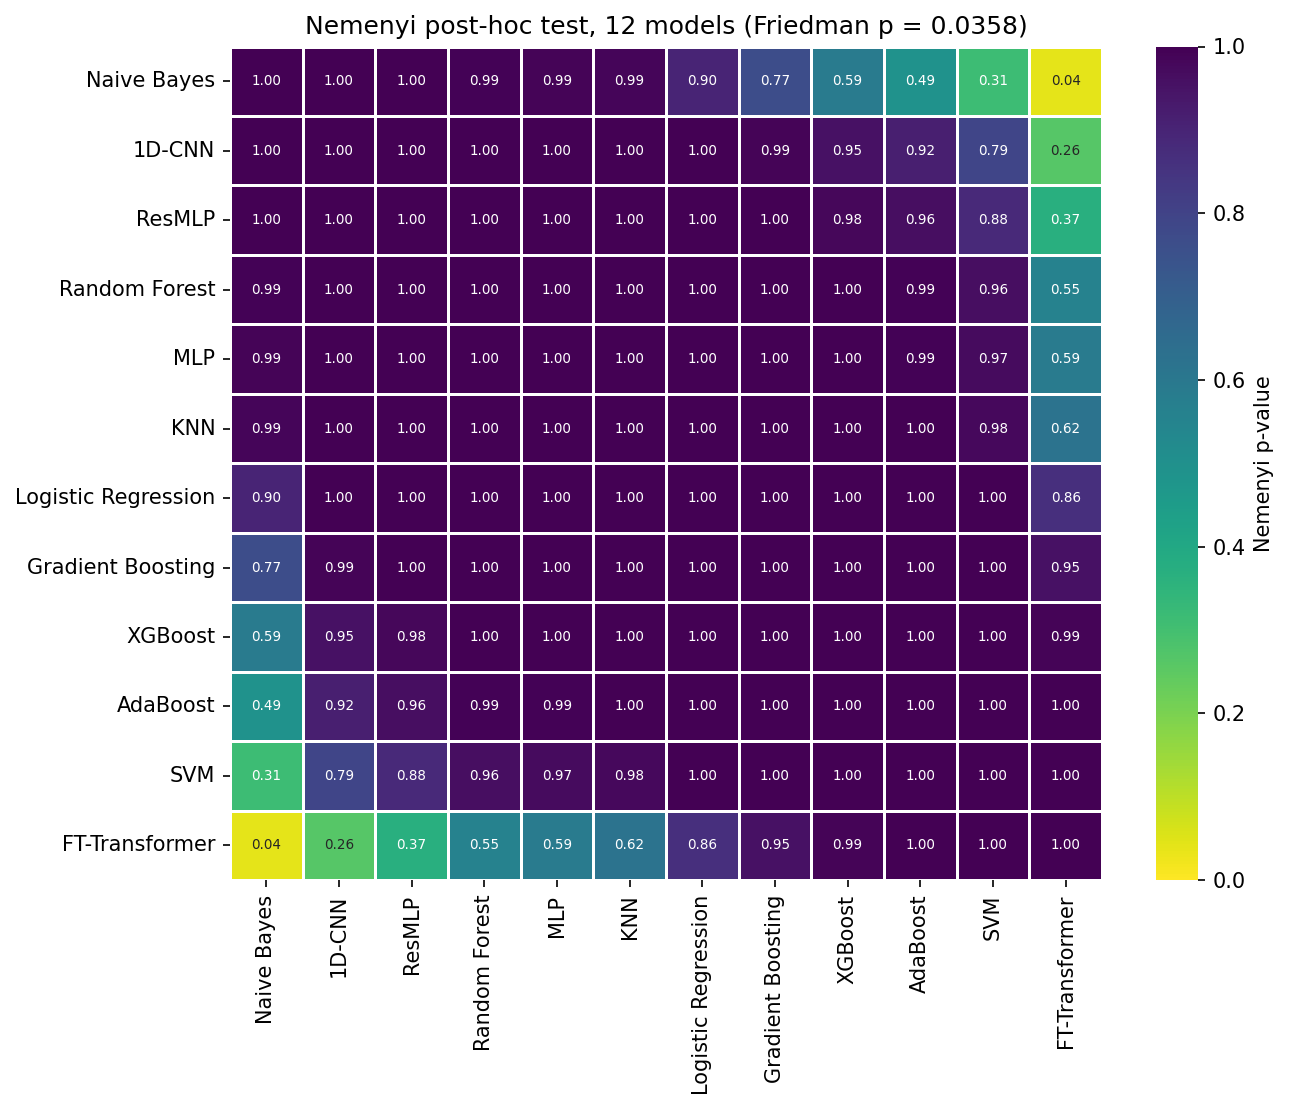

Nemenyi_pvalues_12models.csv, Friedman_mean_ranks_12models.csv, Nemenyi_pairwise_12models.csv, Nemenyi_heatmap_12models.svg saved


In [118]:

from scipy.stats import rankdata, studentized_range, friedmanchisquare

names = list(all_cv.keys())
fr_chi2, fr_p = friedmanchisquare(*[all_cv[m] for m in names])
A = np.column_stack([all_cv[m] for m in names])         
N, k = A.shape
ranks = np.vstack([rankdata(-row) for row in A])         
mean_rank = ranks.mean(axis=0)


se   = np.sqrt(k * (k + 1) / (12 * N))
diff = np.abs(mean_rank[:, None] - mean_rank[None, :])
P    = studentized_range.sf(diff / se, k, np.inf)
np.fill_diagonal(P, 1.0)
P    = np.clip(P, 0, 1)
CD   = studentized_range.ppf(0.95, k, np.inf) * se       

print(f'Friedman ({k} models, {N} folds): chi2 = {fr_chi2:.3f}, p = {fr_p:.4f}')
print(f'Nemenyi critical difference (alpha = 0.05) = {CD:.2f} rank units\n')

rank_df = pd.DataFrame({'Model': names, 'Mean_rank': mean_rank}).sort_values('Mean_rank').reset_index(drop=True)
rank_df['Mean_CV_AUC'] = [all_cv[m].mean() for m in rank_df['Model']]
print(rank_df.round(3).to_string(index=False))

pairs = [{'Model_A': names[i], 'Model_B': names[j], 'Rank_diff': round(diff[i, j], 3),
          'p_value': round(P[i, j], 4), 'Significant_0.05': bool(P[i, j] < 0.05)}
         for i in range(k) for j in range(i + 1, k)]
pairs_df = pd.DataFrame(pairs).sort_values('p_value').reset_index(drop=True)
sig = pairs_df[pairs_df['Significant_0.05']]
print(f'\nSignificant pairs (Nemenyi p < 0.05): {len(sig)} of {len(pairs_df)}')
if len(sig):
    print(sig.to_string(index=False))
else:
    print('None. With only 5 folds the Nemenyi test has low power; report this honestly.')
print('\nSmallest 5 pairwise p-values:')
print(pairs_df.head(5).to_string(index=False))

pd.DataFrame(P, index=names, columns=names).round(4).to_csv(SAVE / 'Nemenyi_pvalues_12models.csv')
rank_df.round(3).to_csv(SAVE / 'Friedman_mean_ranks_12models.csv', index=False)
pairs_df.to_csv(SAVE / 'Nemenyi_pairwise_12models.csv', index=False)

# Heat map of pairwise p-values
order = rank_df['Model'].tolist()
Pm = pd.DataFrame(P, index=names, columns=names).loc[order, order]
plt.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(Pm, annot=True, fmt='.2f', cmap='viridis_r', vmin=0, vmax=1, linewidths=0.5,
            annot_kws={'size': 6.5}, cbar_kws={'label': 'Nemenyi p-value'}, ax=ax)
ax.set_title(f'Nemenyi post-hoc test, 12 models (Friedman p = {fr_p:.4f})')
plt.tight_layout()
plt.savefig(SAVE / 'Nemenyi_heatmap_12models.svg', format='svg', bbox_inches='tight')
plt.show()
print('Nemenyi_pvalues_12models.csv, Friedman_mean_ranks_12models.csv, Nemenyi_pairwise_12models.csv, Nemenyi_heatmap_12models.svg saved')


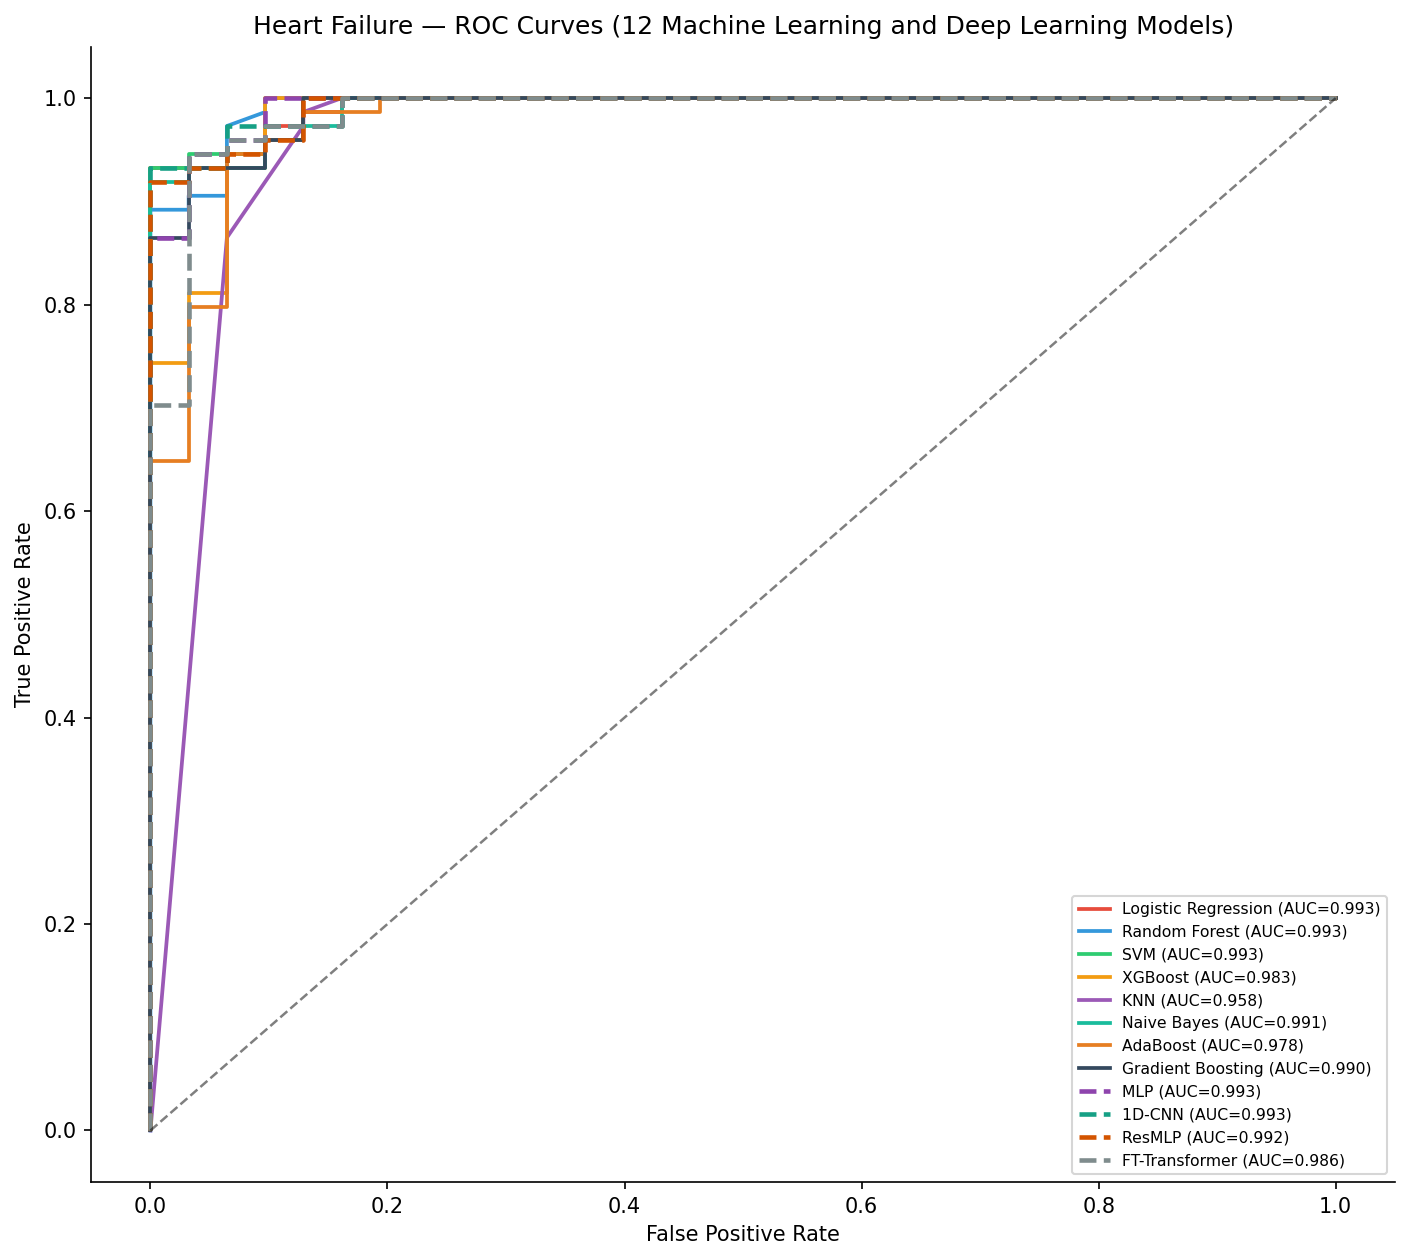

ROC_curves_HF_all12.svg saved


In [119]:

COLORS12 = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22', '#34495e',
            '#8e44ad', '#16a085', '#d35400', '#7f8c8d']
CLASSICAL = list(hf_models.keys())
DEEP      = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']

fig, ax = plt.subplots(figsize=(9.5, 8.5))
for (mname, col) in zip(CLASSICAL + DEEP, COLORS12):
    yp = probs12[mname]
    fpr, tpr, _ = roc_curve(hf_yte, yp)
    auc = roc_auc_score(hf_yte, yp)
    is_dl = mname in DEEP
    ax.plot(fpr, tpr, color=col, lw=2.2 if is_dl else 1.8, ls='--' if is_dl else '-',
            label=f'{mname} (AUC={auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.5)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Heart Failure — ROC Curves (12 Machine Learning and Deep Learning Models)')
ax.legend(loc='lower right', fontsize=7.5, ncol=1)
plt.tight_layout()
plt.savefig(SAVE / 'ROC_curves_HF_all12.svg', format='svg', bbox_inches='tight')
plt.show()
print('ROC_curves_HF_all12.svg saved')


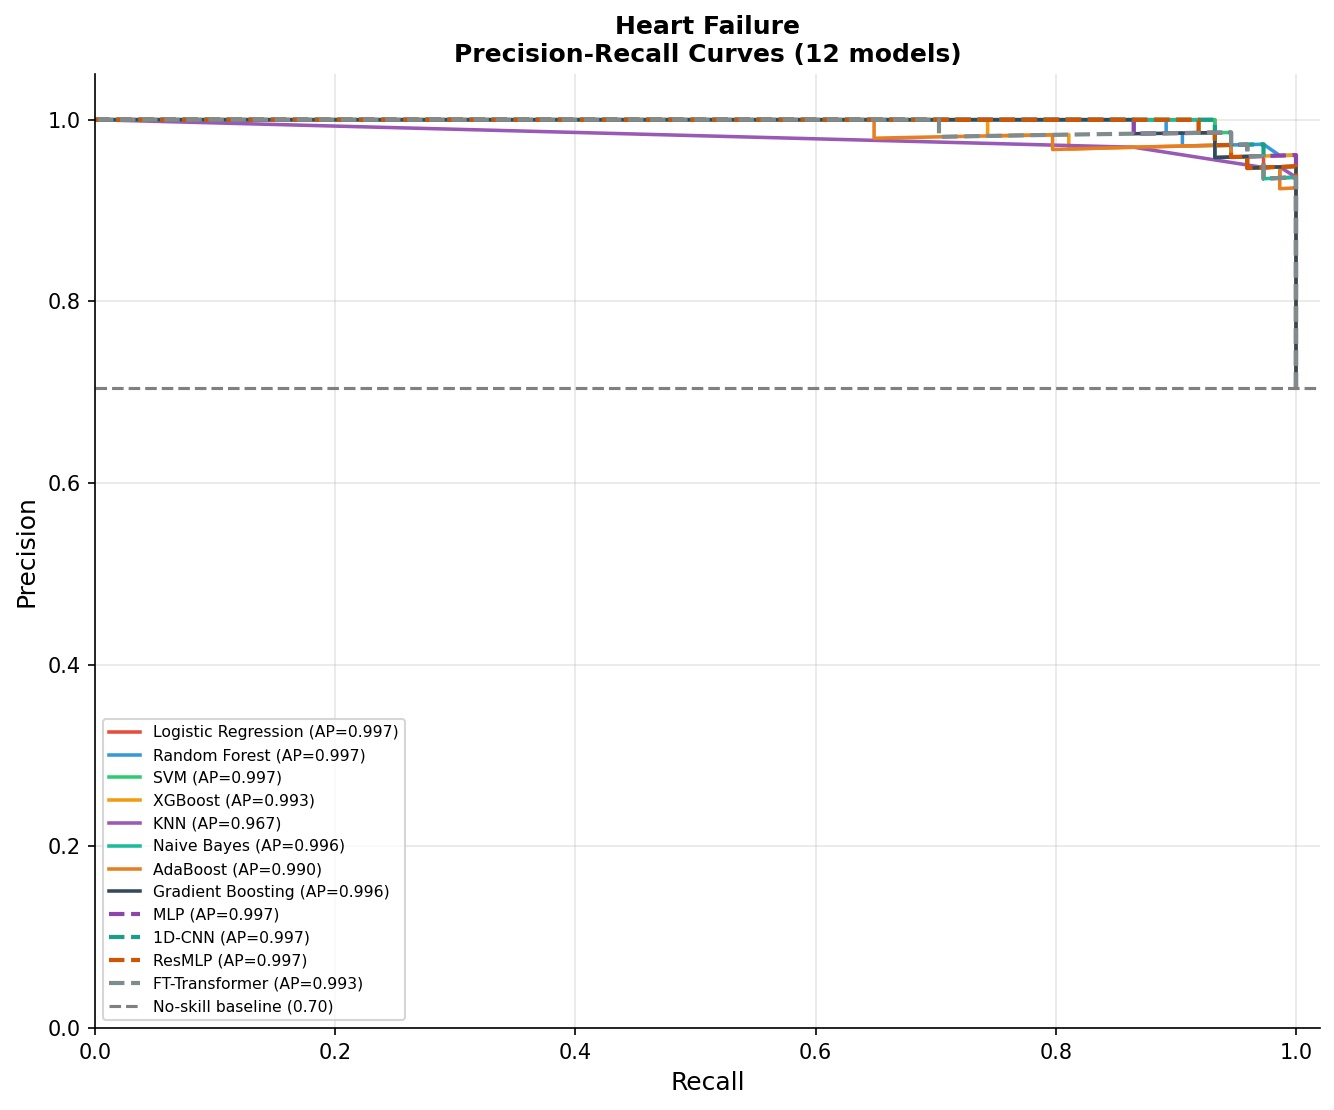

PR_AUC_curves_HF_12models.svg + PR_AUC_values_HF_12models.csv saved


In [120]:

from sklearn.metrics import precision_recall_curve, average_precision_score

COLORS12 = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22', '#34495e',
            '#8e44ad', '#16a085', '#d35400', '#7f8c8d']
CLASSICAL = list(hf_models.keys())
DEEP      = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']

fig, ax = plt.subplots(figsize=(9, 7.5))
ap_rows = []
for mname, color in zip(CLASSICAL + DEEP, COLORS12):
    y_prob = probs12[mname]
    prec, rec, _ = precision_recall_curve(hf_yte, y_prob)
    ap = average_precision_score(hf_yte, y_prob)
    is_dl = mname in DEEP
    ax.plot(rec, prec, color=color, lw=2.0 if is_dl else 1.7, ls='--' if is_dl else '-',
            label=f'{mname} (AP={ap:.3f})')
    ap_rows.append({'Model': mname, 'Average_precision': round(ap, 4)})

baseline = np.asarray(hf_yte).sum() / len(hf_yte)
ax.axhline(baseline, color='gray', ls='--', lw=1.5, label=f'No-skill baseline ({baseline:.2f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Heart Failure\nPrecision-Recall Curves (12 models)', fontsize=12, fontweight='bold')
ax.legend(loc='lower left', fontsize=7.5)
ax.grid(alpha=0.3)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(SAVE / 'PR_AUC_curves_HF_12models.svg', format='svg', bbox_inches='tight', facecolor='white')
plt.show()
pd.DataFrame(ap_rows).to_csv(SAVE / 'PR_AUC_values_HF_12models.csv', index=False)
print('PR_AUC_curves_HF_12models.svg + PR_AUC_values_HF_12models.csv saved')


In [121]:

ids_h1 = set(map(str, h1.columns))
ids_h2 = set(map(str, h2.columns))
ds_te  = np.array(['GSE57338' if str(c) in ids_h1 else 'GSE5406' if str(c) in ids_h2 else 'unknown'
                   for c in heart_test_cols])
assert len(ds_te) == len(hf_yte), 'test-set order mismatch'
assert (ds_te != 'unknown').all(), 'some test samples were not found in h1/h2'
y_te = np.asarray(hf_yte).astype(int)


comp = pd.DataFrame([{'Dataset': d, 'n_test': int((ds_te == d).sum()),
                      'n_HF': int(((ds_te == d) & (y_te == 1)).sum()),
                      'n_Normal': int(((ds_te == d) & (y_te == 0)).sum())}
                     for d in ['GSE57338', 'GSE5406']])
print('Test-set composition per dataset')
print(comp.to_string(index=False))
for _, r in comp.iterrows():
    if r['n_Normal'] < 5 or r['n_HF'] < 5:
        print(f"  [WARNING] {r['Dataset']}: only {r['n_Normal']} Normal / {r['n_HF']} HF test samples -> "
              f"AUC and its CI are unstable here; report with caution.")

def _boot_auc(y, p, n_boot=1000, seed=42):
    rng, aucs = np.random.default_rng(seed), []
    for _ in range(n_boot):
        idx = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[idx])) > 1:
            aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5]) if len(aucs) > 50 else (np.nan, np.nan)

rows = []
for scope, mask in [('GSE57338', ds_te == 'GSE57338'), ('GSE5406', ds_te == 'GSE5406'), ('Pooled test set', np.ones(len(y_te), bool))]:
    y_s = y_te[mask]
    for m, p_all in probs12.items():
        p_s = p_all[mask]
        if len(np.unique(y_s)) < 2:
            auc, lo, hi, sens, spec = (np.nan,) * 5
        else:
            auc = roc_auc_score(y_s, p_s)
            lo, hi = _boot_auc(y_s, p_s)
            pred = (p_s >= 0.5).astype(int)
            tp = ((pred == 1) & (y_s == 1)).sum(); fn = ((pred == 0) & (y_s == 1)).sum()
            tn = ((pred == 0) & (y_s == 0)).sum(); fp = ((pred == 1) & (y_s == 0)).sum()
            sens, spec = tp / (tp + fn + 1e-9), tn / (tn + fp + 1e-9)
        rows.append({'Dataset': scope, 'Model': m, 'n': int(mask.sum()),
                     'n_HF': int(y_s.sum()), 'n_Normal': int((y_s == 0).sum()),
                     'AUC': auc, 'CI_lo': lo, 'CI_hi': hi, 'Sensitivity': sens, 'Specificity': spec})
per_ds = pd.DataFrame(rows).round(3)
per_ds.to_csv(SAVE / 'HF_test_AUC_per_dataset.csv', index=False)

print('\n Test AUC per dataset (threshold 0.5 for sensitivity/specificity)')
print(per_ds.pivot(index='Model', columns='Dataset', values='AUC')[['GSE57338', 'GSE5406', 'Pooled test set']]
      .loc[list(probs12.keys())].to_string())
print('\n HF_test_AUC_per_dataset.csv saved')


Test-set composition per dataset
 Dataset  n_test  n_HF  n_Normal
GSE57338      59    32        27
 GSE5406      46    42         4
  [WARNING] GSE5406: only 4 Normal / 42 HF test samples -> AUC and its CI are unstable here; report with caution.

 Test AUC per dataset (threshold 0.5 for sensitivity/specificity)
Dataset              GSE57338  GSE5406  Pooled test set
Model                                                  
Logistic Regression     0.985    1.000            0.993
Random Forest           0.983    1.000            0.993
SVM                     0.987    1.000            0.993
XGBoost                 0.964    1.000            0.983
KNN                     0.951    0.988            0.958
Naive Bayes             0.985    1.000            0.991
AdaBoost                0.961    1.000            0.978
Gradient Boosting       0.979    1.000            0.990
MLP                     0.987    1.000            0.993
1D-CNN                  0.988    0.994            0.993
ResMLP         

External validation on GSE42955 with several models...
  Model: Naive Bayes
  GSE42955: n=29 | AUC=0.950 [0.833-1.000] | Sens=0.917 | Spec=0.800 | Coverage=95% (19/20 genes)
  Model: Random Forest
  GSE42955: n=29 | AUC=0.967 [0.897-1.000] | Sens=0.917 | Spec=0.800 | Coverage=95% (19/20 genes)
  Model: SVM
  GSE42955: n=29 | AUC=0.967 [0.885-1.000] | Sens=0.958 | Spec=0.800 | Coverage=95% (19/20 genes)

 Results:
 Dataset Disease         Model  N   AUC  CI_lo  CI_hi  Sensitivity  Specificity
GSE42955      HF   Naive Bayes 29 0.950  0.833    1.0        0.917          0.8
GSE42955      HF Random Forest 29 0.967  0.897    1.0        0.917          0.8
GSE42955      HF           SVM 29 0.967  0.885    1.0        0.958          0.8


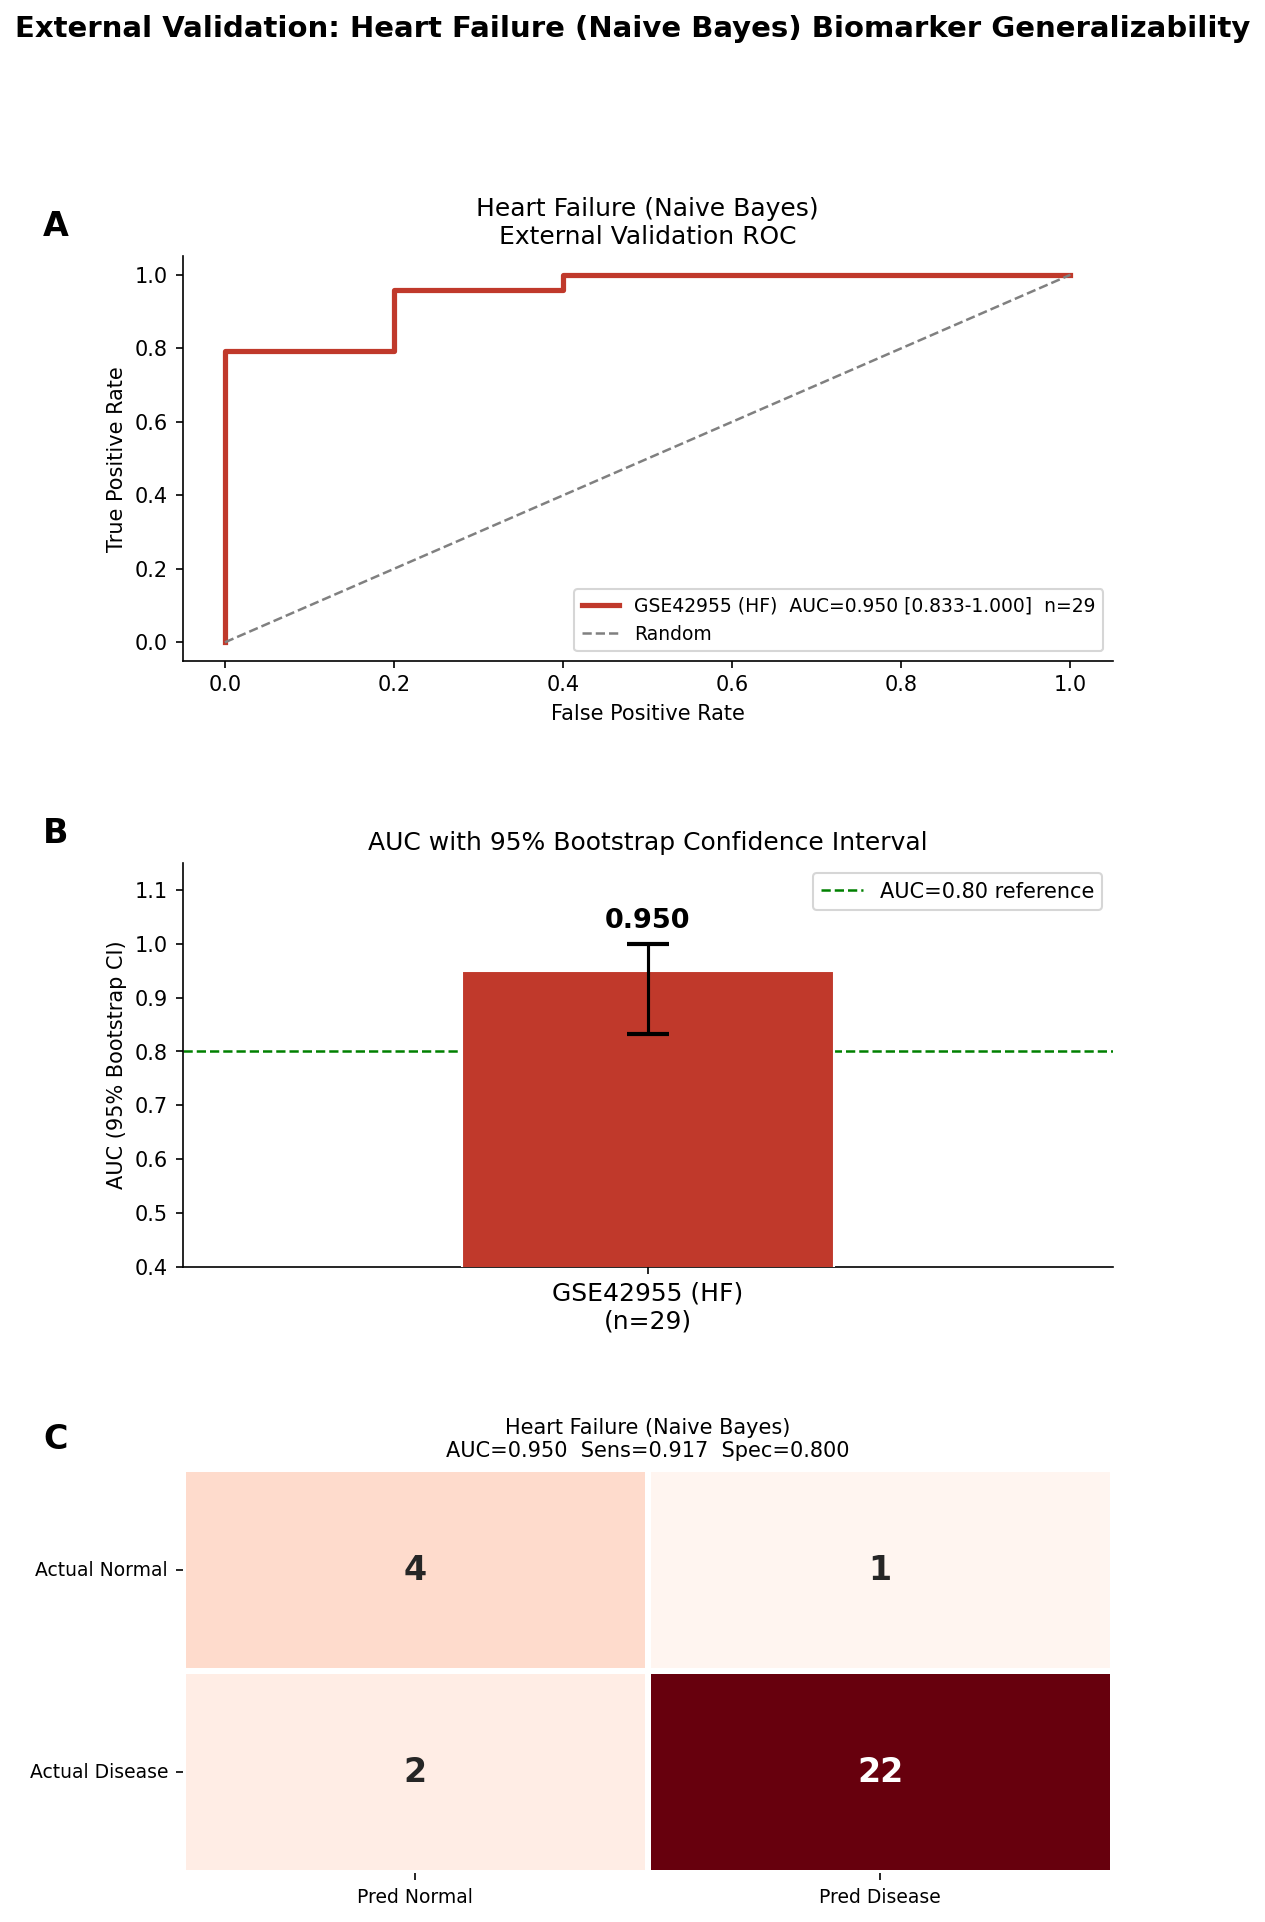

external_validation_HF_Naive_Bayes.svg saved


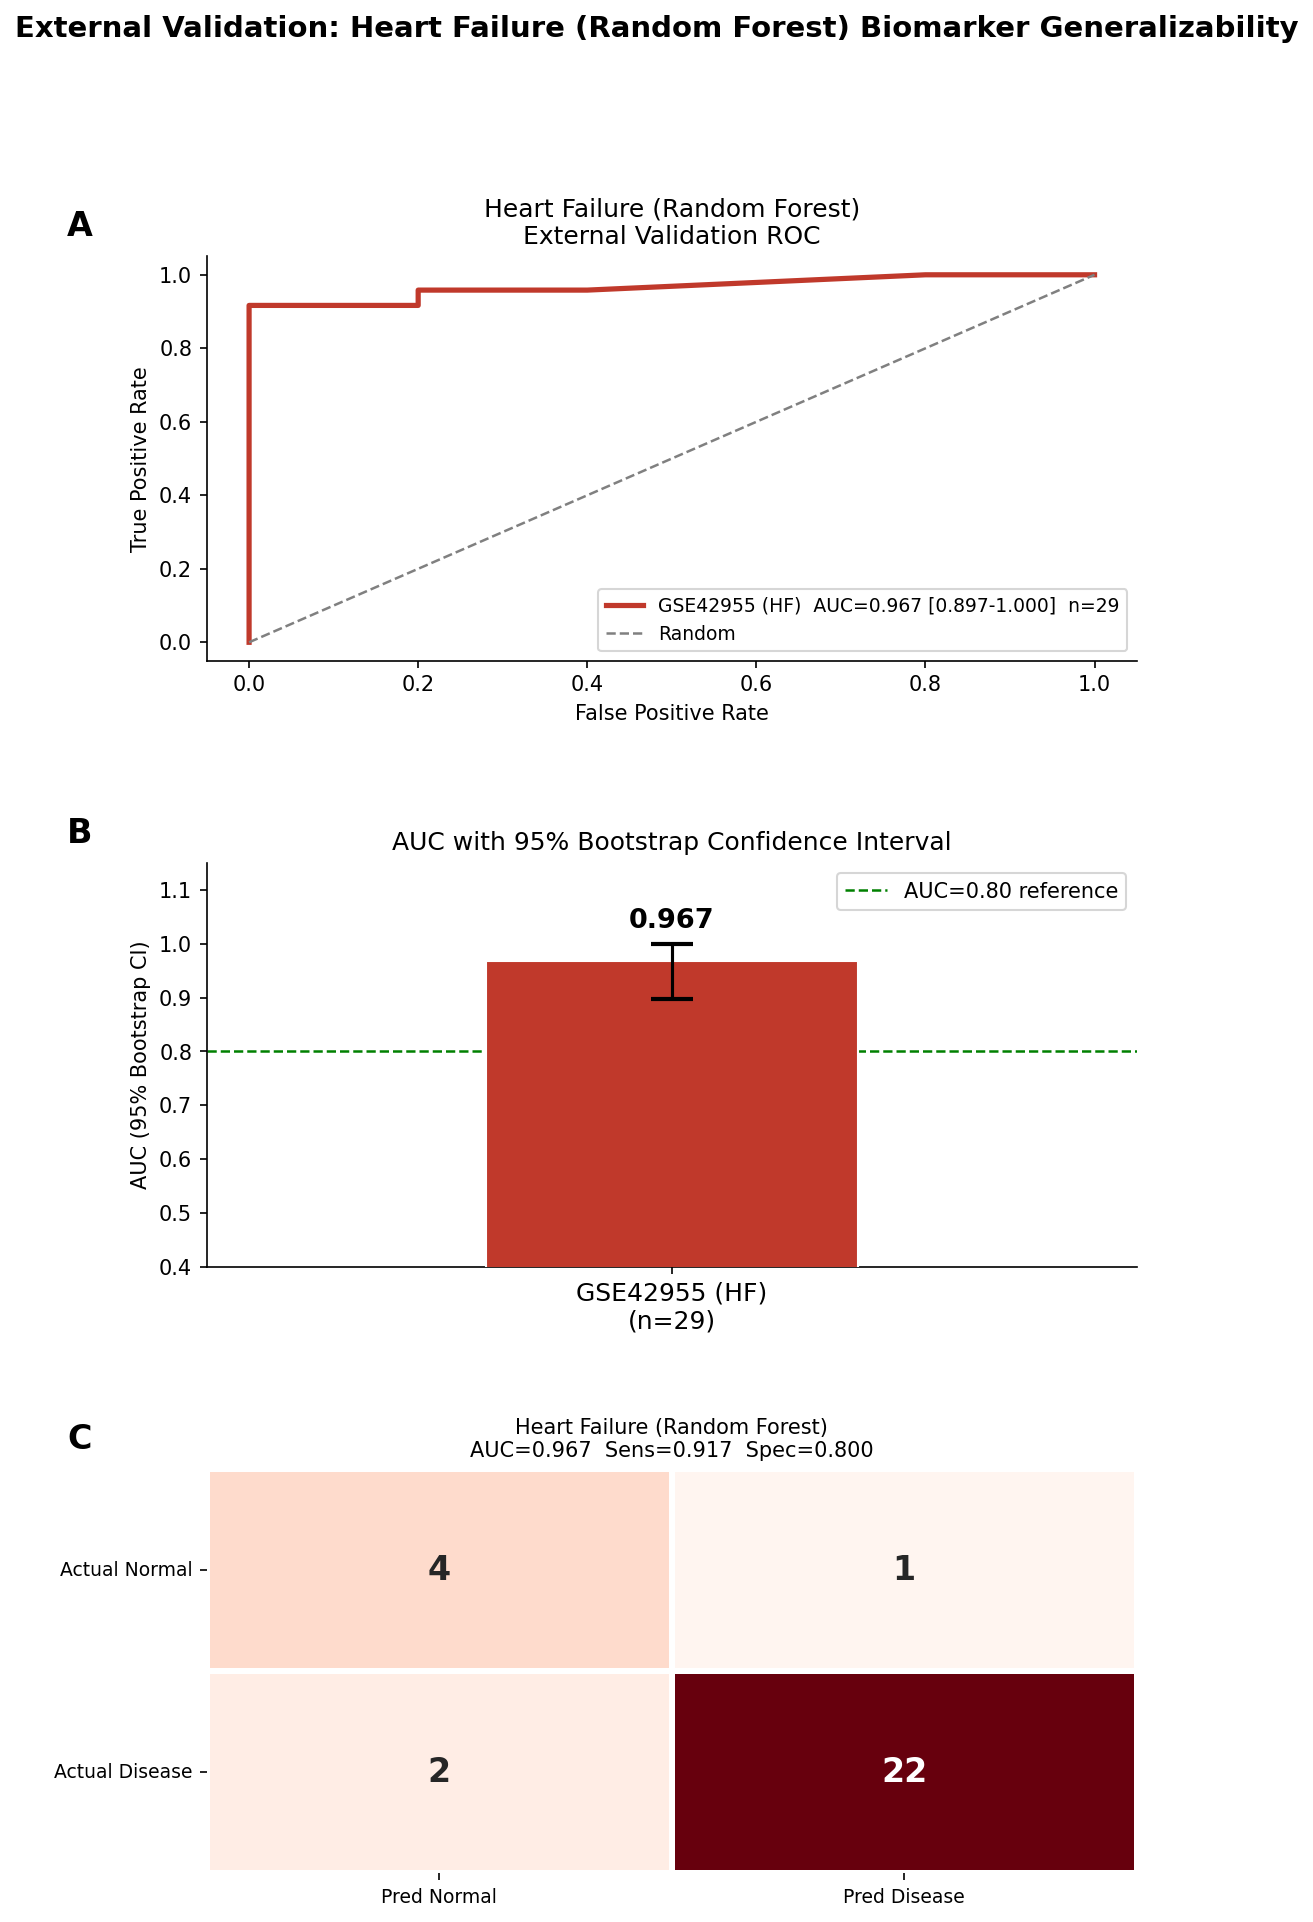

external_validation_HF_Random_Forest.svg saved


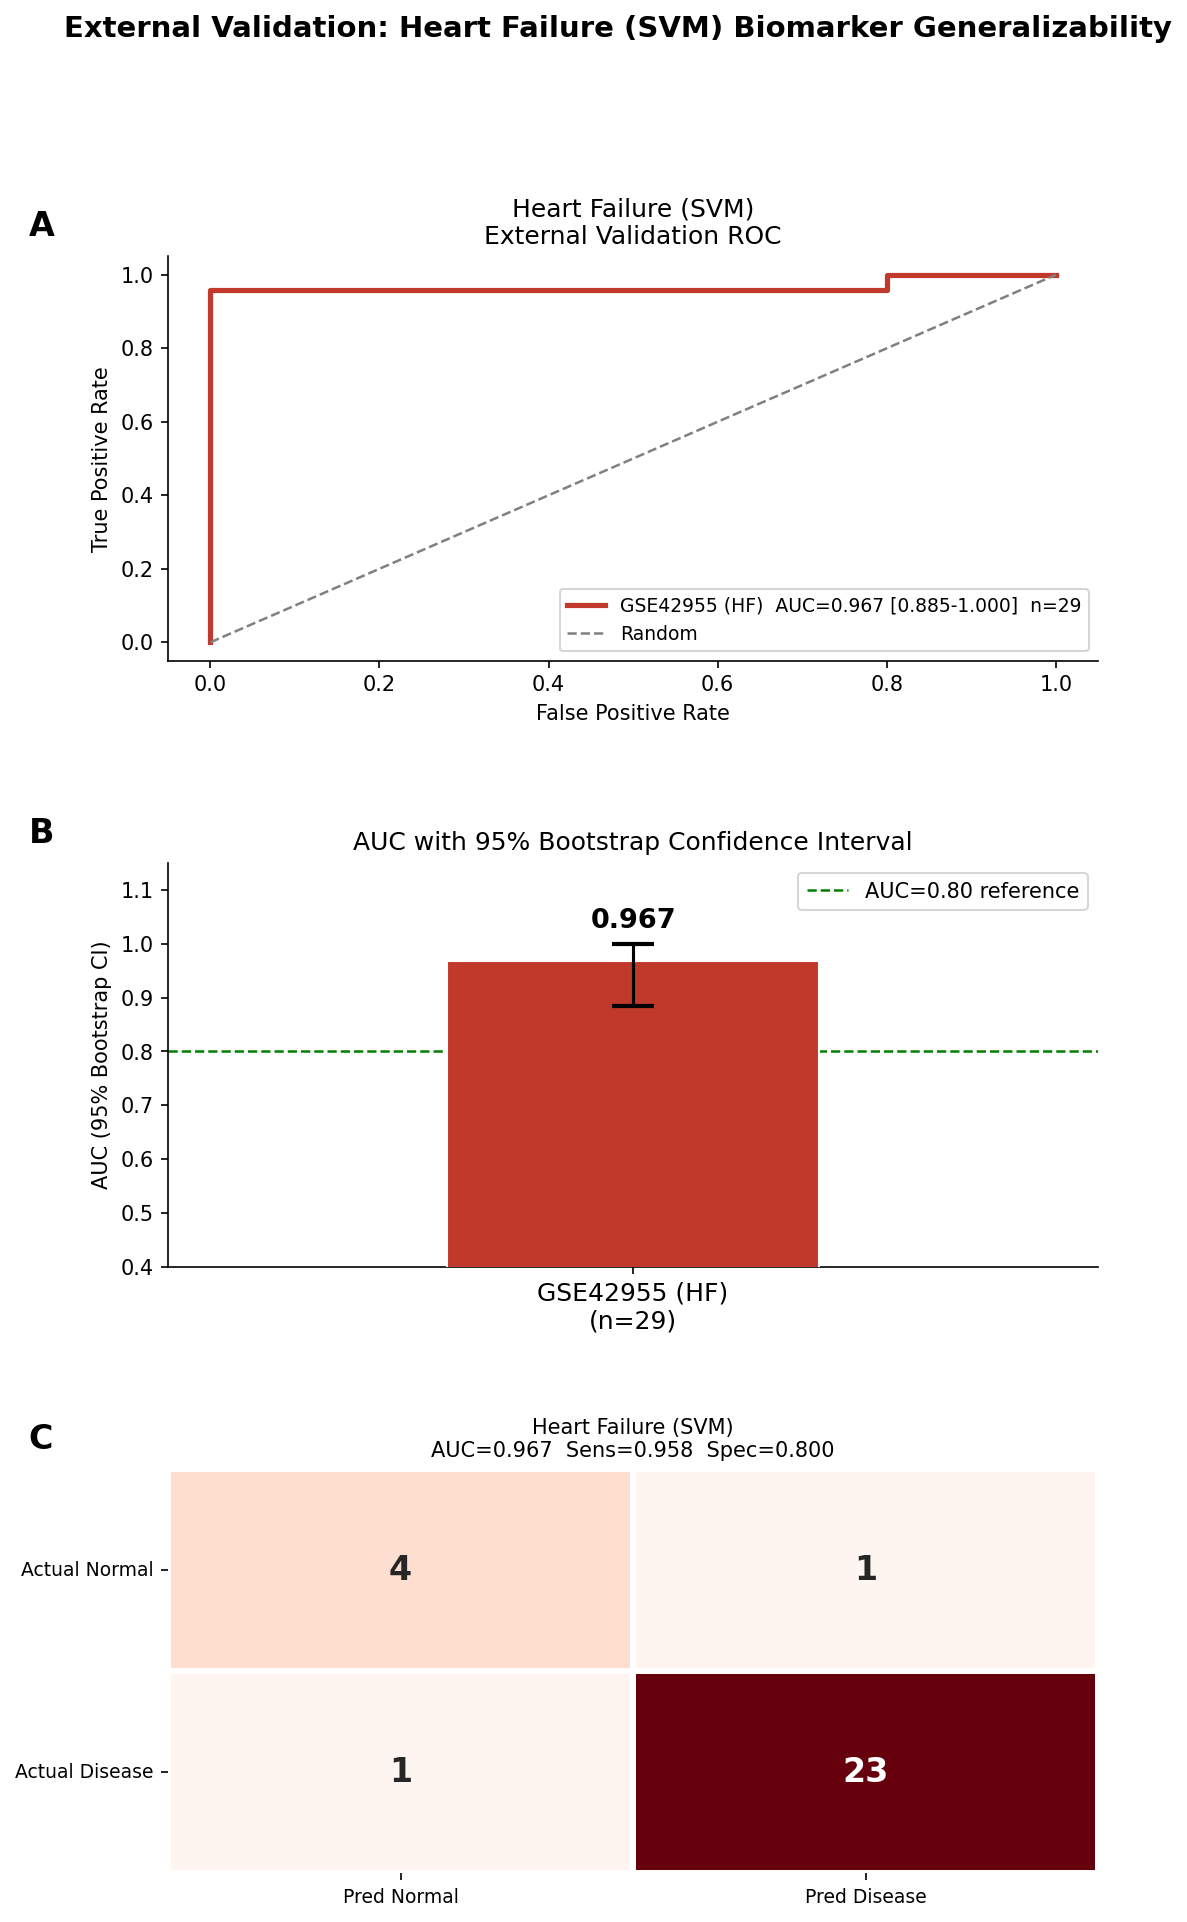

external_validation_HF_SVM.svg saved
Multi-model external validation complete


In [122]:

print('External validation on GSE42955 with several models...')
EV_MODELS = []
for _m in [hf_results.iloc[0]['Model'], 'Naive Bayes', 'Random Forest', 'SVM']:
    if _m not in EV_MODELS:
        EV_MODELS.append(_m)
ev_res = {}
for _m in EV_MODELS:
    print(f'  Model: {_m}')
    ev_res[_m] = evaluate_ev(X_42955, y_42955, hf_genes, hf_models[_m], 'GSE42955')

ev_multi = pd.DataFrame([
    {'Dataset': 'GSE42955', 'Disease': 'HF', 'Model': _m, 'N': ev_res[_m]['n'],
     'AUC': ev_res[_m]['auc'], 'CI_lo': ev_res[_m]['ci_lo'], 'CI_hi': ev_res[_m]['ci_hi'],
     'Sensitivity': ev_res[_m]['sens'], 'Specificity': ev_res[_m]['spec']}
    for _m in EV_MODELS])
ev_multi.to_csv(SAVE_EV / 'external_validation_multimodel.csv', index=False)
print('\n Results:')
print(ev_multi.to_string(index=False))


for res, title, dataset_label, col, cmap, fname in [
    (ev_res[_m], f'Heart Failure ({_m})', 'GSE42955 (HF)', '#C0392B', 'Reds',
     f'external_validation_HF_{_m.replace(" ", "_")}.svg')
    for _m in EV_MODELS
]:
    fig = plt.figure(figsize=(8, 14))
    gs  = gridspec.GridSpec(3, 1, figure=fig, hspace=0.5)

  
    ax_a = fig.add_subplot(gs[0])
    ax_a.plot(res['fpr'], res['tpr'], color=col, lw=2.5,
              label=f"{dataset_label}  AUC={res['auc']:.3f} [{res['ci_lo']:.3f}-{res['ci_hi']:.3f}]  n={res['n']}")
    ax_a.plot([0,1],[0,1],'--',color='gray',lw=1.2,label='Random')
    ax_a.set_xlabel('False Positive Rate')
    ax_a.set_ylabel('True Positive Rate')
    ax_a.set_title(f'{title}\nExternal Validation ROC')
    ax_a.legend(loc='lower right', fontsize=9)
    ax_a.text(-0.15, 1.05, 'A', transform=ax_a.transAxes, fontsize=16, fontweight='bold')

    
    ax_b = fig.add_subplot(gs[1])
    ax_b.bar(0, res['auc'], color=col, width=0.4, edgecolor='white', zorder=3)
    ax_b.errorbar(0, res['auc'],
                  yerr=[[res['auc']-res['ci_lo']], [res['ci_hi']-res['auc']]],
                  fmt='none', color='black', capsize=10, capthick=2, zorder=4)
    ax_b.text(0, res['ci_hi']+0.03, f"{res['auc']:.3f}",
              ha='center', fontweight='bold', fontsize=13)
    ax_b.axhline(0.8, color='green', ls='--', lw=1.2, label='AUC=0.80 reference')
    ax_b.set_xticks([0])
    ax_b.set_xticklabels([f"{dataset_label}\n(n={res['n']})"], fontsize=12)
    ax_b.set_ylabel('AUC (95% Bootstrap CI)')
    ax_b.set_title('AUC with 95% Bootstrap Confidence Interval')
    ax_b.set_xlim([-0.5, 0.5])
    ax_b.set_ylim([0.4, 1.15])
    ax_b.legend(fontsize=10)
    ax_b.text(-0.15, 1.05, 'B', transform=ax_b.transAxes, fontsize=16, fontweight='bold')

    
    ax_c = fig.add_subplot(gs[2])
    cm_arr = np.array([[res['tn'],res['fp']],[res['fn'],res['tp']]])
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap=cmap, ax=ax_c,
                cbar=False, linewidths=2, linecolor='white',
                annot_kws={'size':16,'weight':'bold'})
    ax_c.set_xticklabels(['Pred Normal','Pred Disease'], fontsize=9)
    ax_c.set_yticklabels(['Actual Normal','Actual Disease'], fontsize=9, rotation=0)
    ax_c.set_title(f'{title}\nAUC={res["auc"]:.3f}  Sens={res["sens"]:.3f}  Spec={res["spec"]:.3f}', fontsize=10)
    ax_c.text(-0.15, 1.05, 'C', transform=ax_c.transAxes, fontsize=16, fontweight='bold')

    fig.suptitle(f'External Validation: {title} Biomarker Generalizability',
                 fontsize=14, fontweight='bold', y=0.995)
    plt.savefig(SAVE_EV / fname, format='svg', bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'{fname} saved')

print('Multi-model external validation complete')


Re-fitting the 4 deep-learning models (training split only)...
  MLP: re-fitted test AUC = 0.993 | original = 0.993
  1D-CNN: re-fitted test AUC = 0.993 | original = 0.993
  ResMLP: re-fitted test AUC = 0.992 | original = 0.992
  FT-Transformer: re-fitted test AUC = 0.986 | original = 0.986

 External validation on GSE42955 — 12 models
  GSE42955 [Logistic Regression]: n=29 | AUC=0.975 [0.913-1.000] | Sens=0.833 | Spec=1.000 | Coverage=95% (19/20 genes)
  GSE42955 [Random Forest]: n=29 | AUC=0.967 [0.897-1.000] | Sens=0.917 | Spec=0.800 | Coverage=95% (19/20 genes)
  GSE42955 [SVM]: n=29 | AUC=0.967 [0.885-1.000] | Sens=0.958 | Spec=0.800 | Coverage=95% (19/20 genes)
  GSE42955 [XGBoost]: n=29 | AUC=0.950 [0.830-1.000] | Sens=0.958 | Spec=0.600 | Coverage=95% (19/20 genes)
  GSE42955 [KNN]: n=29 | AUC=0.992 [0.960-1.000] | Sens=0.958 | Spec=0.800 | Coverage=95% (19/20 genes)
  GSE42955 [Naive Bayes]: n=29 | AUC=0.950 [0.833-1.000] | Sens=0.917 | Spec=0.800 | Coverage=95% (19/20 genes)


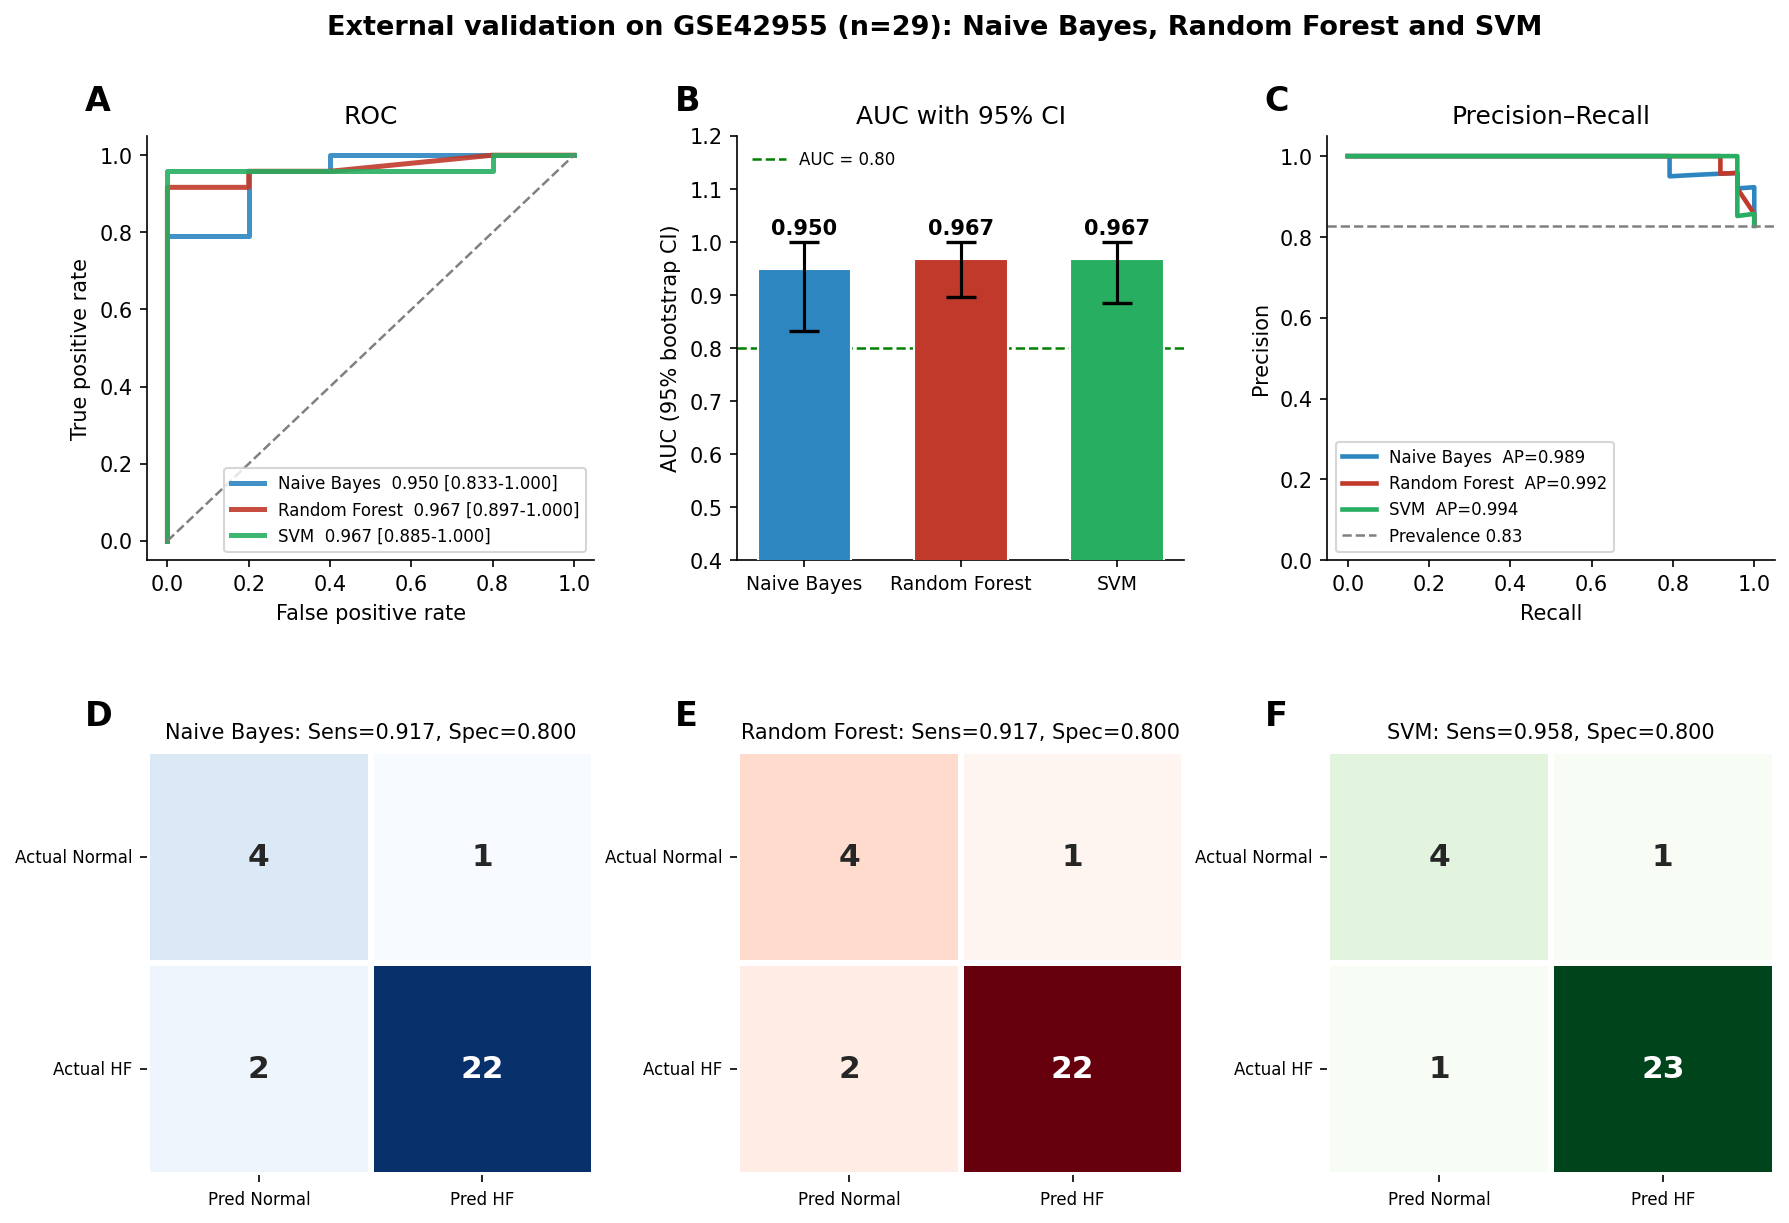

9models_panel.svg + 9models_panel.png saved


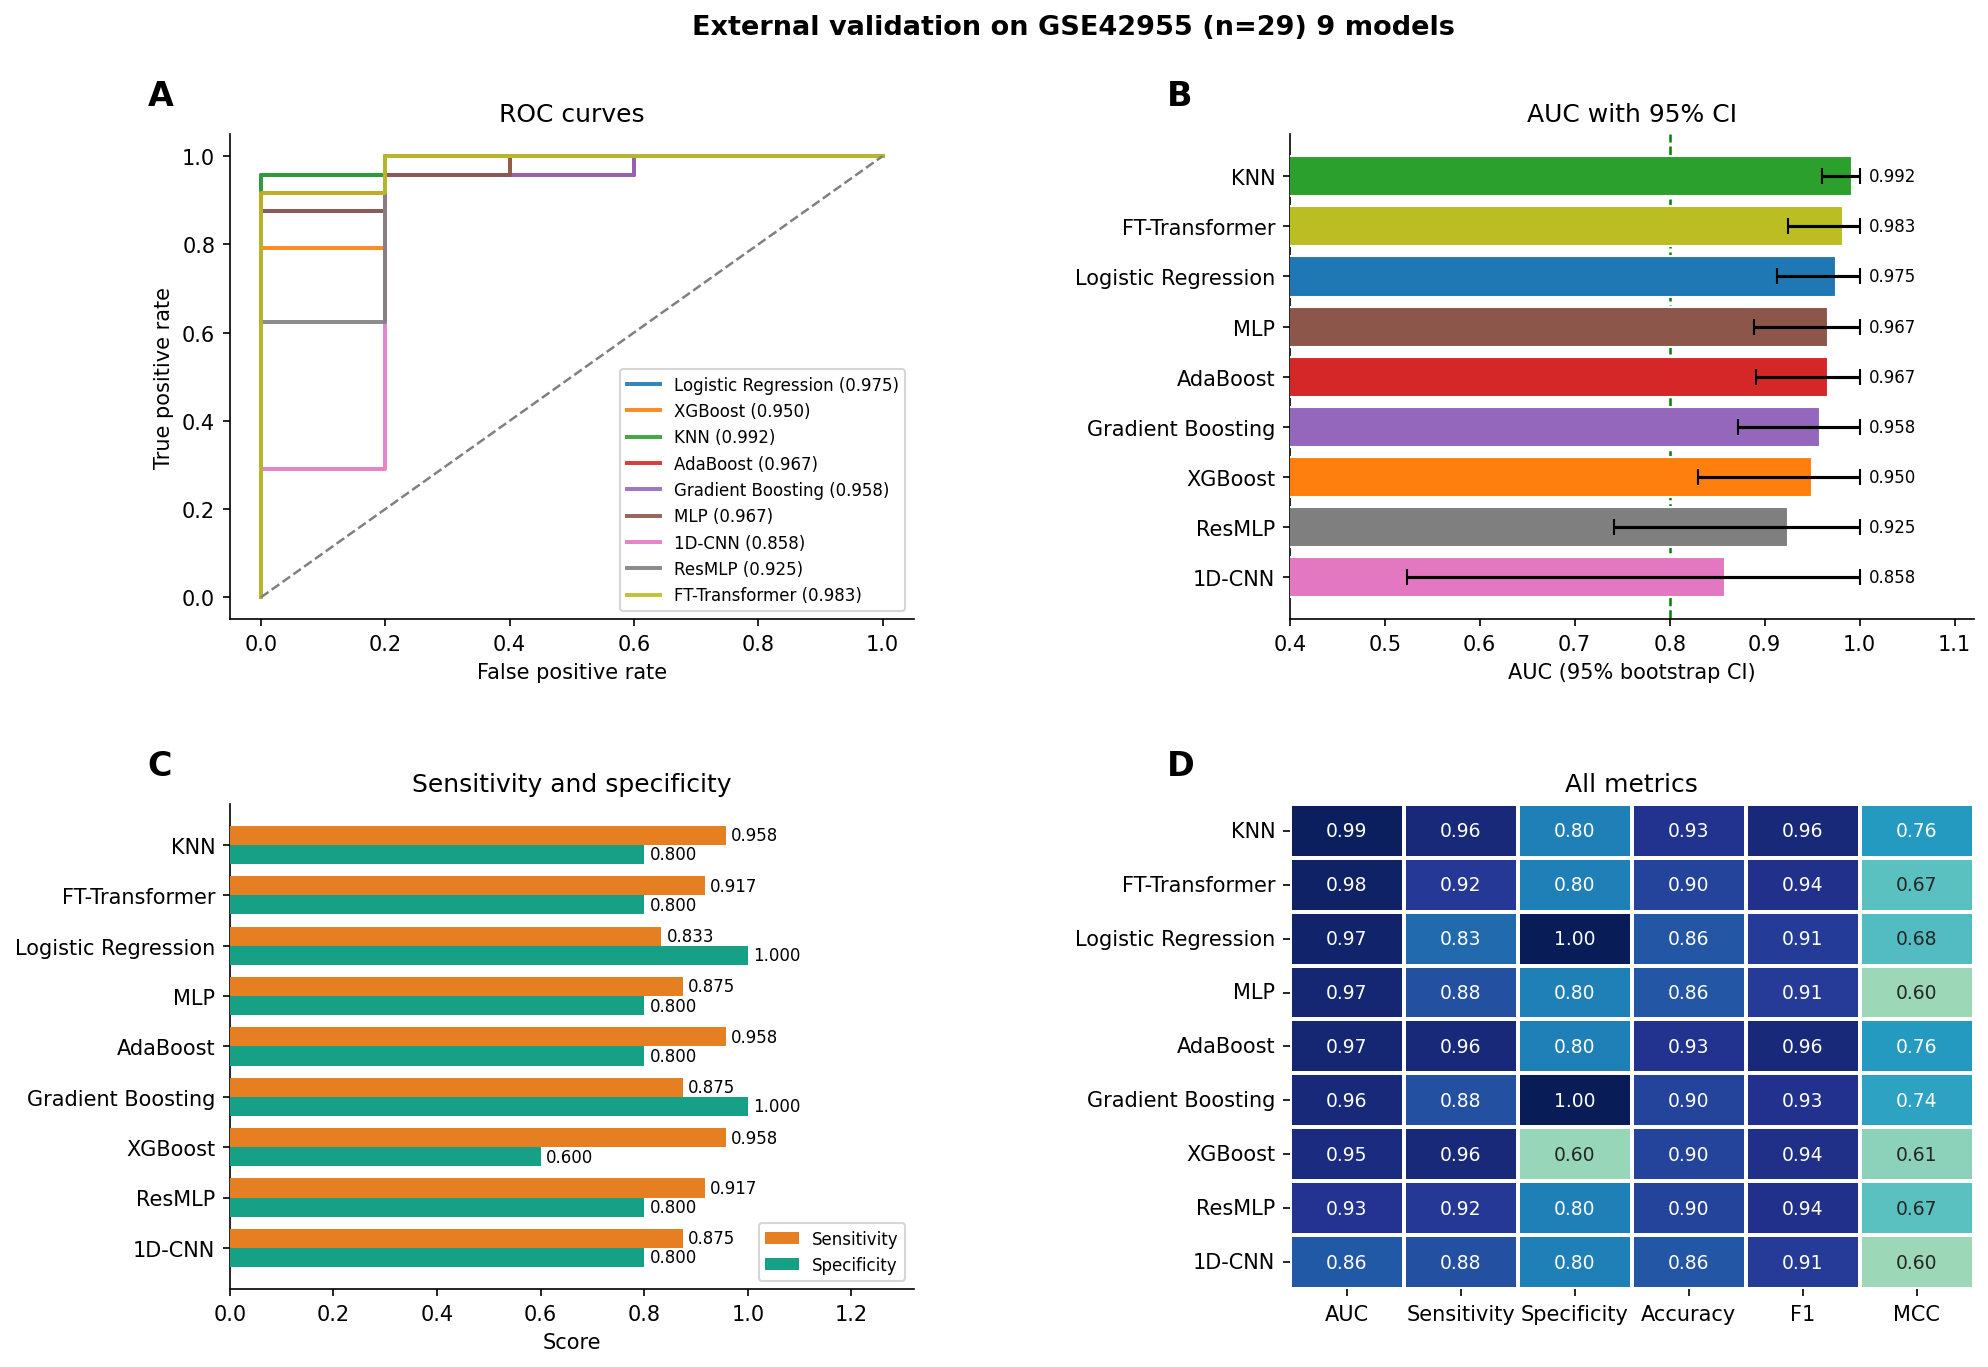


 EV-12 complete: 1 main figure (3 models) + (9 models), SVG + PNG, + 3 CSV files


In [123]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, precision_recall_curve, average_precision_score,
                             accuracy_score, f1_score, matthews_corrcoef)

MAIN3     = ['Naive Bayes', 'Random Forest', 'SVM']                      
DL_NAMES  = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']
CLASS_9   = [m for m in hf_models if m not in MAIN3]                      
SUPP9     = CLASS_9 + DL_NAMES                                            
EV_COL    = {'Naive Bayes': '#2E86C1', 'Random Forest': '#C0392B', 'SVM': '#27AE60'}
EV_CMAP   = {'Naive Bayes': 'Blues',   'Random Forest': 'Reds',    'SVM': 'Greens'}
y_ev      = np.asarray(y_42955).astype(int)

def save_both(fig, stem):
    fig.savefig(SAVE_EV / f'{stem}.svg', format='svg', bbox_inches='tight', facecolor='white')
    fig.savefig(SAVE_EV / f'{stem}.png', format='png', dpi=300, bbox_inches='tight', facecolor='white')
    print(f'{stem}.svg + {stem}.png saved')

def style(ax):
    ax.spines[['top', 'right']].set_visible(False)


import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class TorchWrap:
    """Gives a PyTorch net the predict / predict_proba interface that evaluate_ev() expects."""
    def __init__(self, net):
        self.net = net.eval()
    def predict_proba(self, X):
        with torch.no_grad():
            p = self.net(torch.tensor(np.asarray(X), dtype=torch.float32)).squeeze(-1).numpy()
        p = np.atleast_1d(p)
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def train_dl_keep(Xtr, ytr, ModelClass, epochs=60, lr=0.001):
    
    torch.manual_seed(42)
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)
    loader    = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)
    model     = ModelClass(Xtr.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
    criterion = nn.BCELoss()
    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()
    model.eval()
    return model

print('Re-fitting the 4 deep-learning models (training split only)...')
ev_dl_models = {}
for _name, _Arch in [('MLP', MLP), ('1D-CNN', CNN1D), ('ResMLP', ResMLP), ('FT-Transformer', FTTransformer)]:
    _net = train_dl_keep(hf_Xtr.astype(np.float32), hf_ytr.astype(np.float32), _Arch)
    ev_dl_models[_name] = TorchWrap(_net)
    
    _ref = (dl_results['Heart Failure'][_name] if _name in dl_results['Heart Failure'] else dl_extra[_name])
    _auc = roc_auc_score(hf_yte, ev_dl_models[_name].predict_proba(hf_Xte.astype(np.float32))[:, 1])
    _key = next((k for k in ('auc', 'AUC', 'Test_AUC', 'test_auc') if isinstance(_ref, dict) and k in _ref), None)
    if _key is None:
        print(f'  {_name}: re-fitted test AUC = {_auc:.3f} | (reference key not found; available: '
              f'{list(_ref.keys()) if isinstance(_ref, dict) else type(_ref)})')
    else:
        _orig = float(_ref[_key])
        print(f'  {_name}: re-fitted test AUC = {_auc:.3f} | original = {_orig:.3f}'
              + ('' if abs(_auc - _orig) < 0.002 else '   <-- differs (GPU non-determinism?)'))

ALL_MODELS = {**{m: hf_models[m] for m in hf_models}, **ev_dl_models}      


def ev_probs(model, X_ev, genes):
    
    avail = [g for g in genes if g in X_ev.columns]
    X = pd.DataFrame(0.0, index=X_ev.index, columns=genes)
    X[avail] = X_ev[avail].values
    Xs = StandardScaler().fit_transform(X.values)
    return model.predict_proba(Xs)[:, 1], model.predict(Xs)

ev_res, ev_prob, ev_pred = {}, {}, {}
print('\n External validation on GSE42955 — 12 models')
for m, mdl in ALL_MODELS.items():
    ev_res[m] = evaluate_ev(X_42955, y_ev, hf_genes, mdl, f'GSE42955 [{m}]')
    ev_prob[m], ev_pred[m] = ev_probs(mdl, X_42955, hf_genes)

rows = []
for m in ALL_MODELS:
    r = ev_res[m]
    rows.append({'Model': m, 'Group': 'Main paper' if m in MAIN3 else 'Supplementary',
                 'Type': 'Deep learning' if m in DL_NAMES else 'Classical ML', 'N': len(y_ev),
                 'AUC': r['auc'], 'CI_lo': r['ci_lo'], 'CI_hi': r['ci_hi'],
                 'Sensitivity': r['sens'], 'Specificity': r['spec'],
                 'Accuracy': round(accuracy_score(y_ev, ev_pred[m]), 3),
                 'F1': round(f1_score(y_ev, ev_pred[m], zero_division=0), 3),
                 'MCC': round(matthews_corrcoef(y_ev, ev_pred[m]), 3),
                 'PR_AUC': round(average_precision_score(y_ev, ev_prob[m]), 3),
                 'TP': r['tp'], 'TN': r['tn'], 'FP': r['fp'], 'FN': r['fn']})
ev12 = pd.DataFrame(rows)
ev12.to_csv(SAVE_EV / 'external_validation_12models_all.csv', index=False)
ev12[ev12.Model.isin(MAIN3)].to_csv(SAVE_EV / 'external_validation_3models_main.csv', index=False)
ev12[ev12.Model.isin(SUPP9)].to_csv(SAVE_EV / 'external_validation_9models_supp.csv', index=False)
print('\n External validation, all 12 models (GSE42955)')
print(ev12.drop(columns=['Type', 'N']).to_string(index=False))


assert abs(ev_res['SVM']['auc'] - res_hf['auc']) < 1e-6, 'SVM result differs from CELL 15'
print('SVM result identical to CELL 15')


fig = plt.figure(figsize=(14, 9))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.32)
axA, axB, axC = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2])
for i, m in enumerate(MAIN3):
    r = ev_res[m]
    axA.plot(r['fpr'], r['tpr'], color=EV_COL[m], lw=2.4, alpha=0.9,
             label=f"{m}  {r['auc']:.3f} [{r['ci_lo']:.3f}-{r['ci_hi']:.3f}]")
    axB.bar(i, r['auc'], color=EV_COL[m], width=0.6, edgecolor='white', zorder=3)
    axB.errorbar(i, r['auc'], yerr=[[r['auc'] - r['ci_lo']], [r['ci_hi'] - r['auc']]],
                 fmt='none', color='black', capsize=7, capthick=1.6, zorder=4)
    axB.text(i, r['ci_hi'] + 0.015, f"{r['auc']:.3f}", ha='center', fontweight='bold', fontsize=10)
    p_, r_, _ = precision_recall_curve(y_ev, ev_prob[m])
    axC.plot(r_, p_, color=EV_COL[m], lw=2.2, label=f"{m}  AP={average_precision_score(y_ev, ev_prob[m]):.3f}")
axA.plot([0, 1], [0, 1], '--', color='gray', lw=1.2)
axA.set_xlabel('False positive rate'); axA.set_ylabel('True positive rate')
axA.set_title('ROC'); axA.legend(loc='lower right', fontsize=8)
axB.axhline(0.8, color='green', ls='--', lw=1.2, label='AUC = 0.80')
axB.set_xticks(range(3)); axB.set_xticklabels(MAIN3, fontsize=9)
axB.set_ylim(0.4, 1.2); axB.set_ylabel('AUC (95% bootstrap CI)'); axB.set_title('AUC with 95% CI'); axB.legend(loc='upper left', fontsize=8, frameon=False)
axC.axhline(y_ev.mean(), color='gray', ls='--', lw=1.2, label=f'Prevalence {y_ev.mean():.2f}')
axC.set_xlabel('Recall'); axC.set_ylabel('Precision'); axC.set_ylim(0, 1.05)
axC.set_title('Precision–Recall'); axC.legend(loc='lower left', fontsize=8)
for ax_, lab in zip([axA, axB, axC], 'ABC'):
    style(ax_); ax_.text(-0.14, 1.06, lab, transform=ax_.transAxes, fontsize=16, fontweight='bold')
for j, m in enumerate(MAIN3):
    ax_ = fig.add_subplot(gs[1, j]); r = ev_res[m]
    sns.heatmap(np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]]), annot=True, fmt='d', cmap=EV_CMAP[m],
                cbar=False, linewidths=2, linecolor='white', annot_kws={'size': 15, 'weight': 'bold'}, ax=ax_)
    ax_.set_xticklabels(['Pred Normal', 'Pred HF'], fontsize=8)
    ax_.set_yticklabels(['Actual Normal', 'Actual HF'], fontsize=8, rotation=0)
    ax_.set_title(f"{m}: Sens={r['sens']:.3f}, Spec={r['spec']:.3f}", fontsize=10)
    ax_.text(-0.14, 1.06, 'DEF'[j], transform=ax_.transAxes, fontsize=16, fontweight='bold')
fig.suptitle(f'External validation on GSE42955 (n={len(y_ev)}): Naive Bayes, Random Forest and SVM',
             fontsize=13, fontweight='bold', y=0.97)
save_both(fig, 'main 3models panel'); plt.show()


sd = ev12[ev12.Model.isin(SUPP9)].sort_values('AUC', ascending=True).reset_index(drop=True)
cols9 = dict(zip(SUPP9, plt.cm.tab10(np.linspace(0, 1, 10))[:9]))
fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.55)
axA, axB, axC, axD = (fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
                      fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1]))
for m in SUPP9:                                                        # A — ROC
    r = ev_res[m]
    axA.plot(r['fpr'], r['tpr'], color=cols9[m], lw=1.9, alpha=0.9, label=f"{m} ({r['auc']:.3f})")
axA.plot([0, 1], [0, 1], '--', color='gray', lw=1.2)
axA.set_xlabel('False positive rate'); axA.set_ylabel('True positive rate')
axA.set_title('ROC curves'); axA.legend(loc='lower right', fontsize=8)
ypos = np.arange(len(sd))                                              # B — AUC ± CI
axB.barh(ypos, sd['AUC'], color=[cols9[m] for m in sd.Model], edgecolor='white', zorder=3)
axB.errorbar(sd['AUC'], ypos, xerr=[sd['AUC'] - sd['CI_lo'], sd['CI_hi'] - sd['AUC']],
             fmt='none', color='black', capsize=4, zorder=4)
for y_, (a_, hi_) in enumerate(zip(sd['AUC'], sd['CI_hi'])):
    axB.text(min(hi_ + 0.01, 1.07), y_, f'{a_:.3f}', va='center', fontsize=8)
axB.axvline(0.8, color='green', ls='--', lw=1.2)
axB.set_yticks(ypos); axB.set_yticklabels(sd.Model); axB.set_xlim(0.4, 1.12)
axB.set_xlabel('AUC (95% bootstrap CI)'); axB.set_title('AUC with 95% CI')
h = 0.38                                                               # C — Sens / Spec
axC.barh(ypos + h / 2, sd['Sensitivity'], h, color='#E67E22', label='Sensitivity', zorder=3)
axC.barh(ypos - h / 2, sd['Specificity'], h, color='#16A085', label='Specificity', zorder=3)
for y_, (se_, sp_) in enumerate(zip(sd['Sensitivity'], sd['Specificity'])):
    axC.text(se_ + 0.01, y_ + h / 2, f'{se_:.3f}', va='center', fontsize=8)
    axC.text(sp_ + 0.01, y_ - h / 2, f'{sp_:.3f}', va='center', fontsize=8)
axC.set_yticks(ypos); axC.set_yticklabels(sd.Model); axC.set_xlim(0, 1.32)
axC.set_xlabel('Score'); axC.set_title('Sensitivity and specificity'); axC.legend(loc='lower right', fontsize=8)
hm = sd.iloc[::-1].set_index('Model')[['AUC', 'Sensitivity', 'Specificity', 'Accuracy', 'F1', 'MCC']]   
sns.heatmap(hm, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0.4, vmax=1.0, cbar=False,
            linewidths=1, linecolor='white', annot_kws={'size': 9}, ax=axD)
axD.set_ylabel(''); axD.set_title('All metrics'); axD.tick_params(axis='y', rotation=0)
for ax_, lab in zip([axA, axB, axC, axD], 'ABCD'):
    ax_.text(-0.18 if lab in 'BD' else -0.12, 1.06, lab, transform=ax_.transAxes, fontsize=16, fontweight='bold')
for ax_ in (axA, axB, axC): style(ax_)
fig.suptitle(f'External validation on GSE42955 (n={len(y_ev)}) 9 models',
             fontsize=13, fontweight='bold', y=0.96)
save_both(fig, '9models_panel'); plt.show()

print('\n EV-12 complete: 1 main figure (3 models) + (9 models), SVG + PNG, + 3 CSV files')

 ResMLP: y_prob not found in dl_results - training now (60 epochs)...
ResMLP: trained, test AUC = 0.992 (compare with Table S2)
 FT-Transformer: y_prob not found in dl_results - training now (60 epochs)...
FT-Transformer: trained, test AUC = 0.986 (compare with Table S2)


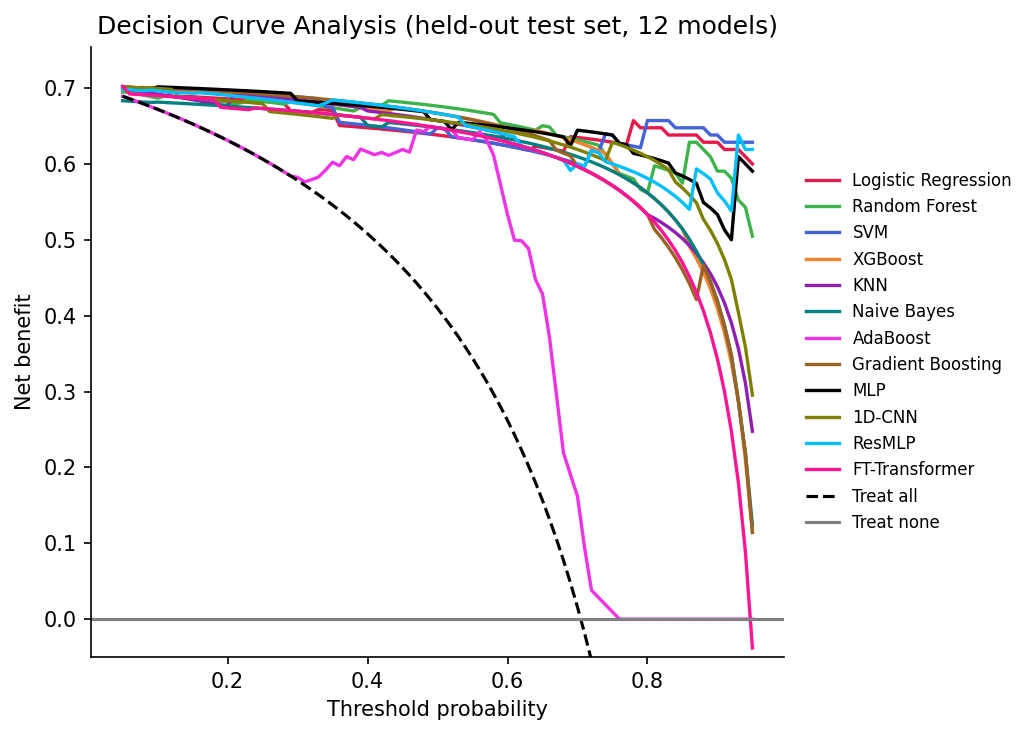

DCA saved (12 models)


In [124]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
plt.rcParams['svg.fonttype'] = 'none'

DEEP = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']
COLORS = ['#E6194B', '#3CB44B', '#4363D8', '#F58231', '#911EB4', '#008080',
          '#F032E6', '#9A6324', '#000000', '#808000', '#00BFFF', '#FF1493']
PAL = dict(zip(list(hf_models) + DEEP, COLORS))

def _dl_prob(name, epochs=60, lr=0.001):
    """Test-set probabilities of a DL model. If missing in dl_results, train it (DLX recipe) and store it."""
    try:
        return np.asarray(dl_results['Heart Failure'][name]['y_prob']).ravel()
    except Exception:
        pass
    print(f' {name}: y_prob not found in dl_results - training now ({epochs} epochs)...')
    sc = StandardScaler()
    Xtr = sc.fit_transform(np.asarray(hf_Xtr)).astype(np.float32)
    Xte = sc.transform(np.asarray(hf_Xte)).astype(np.float32)
    ytr = np.asarray(hf_ytr).astype(int)
    torch.manual_seed(42)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)),
                        batch_size=32, shuffle=True)
    model = dl_arch[name](Xtr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
    crit  = nn.BCELoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        prob = model(torch.tensor(Xte)).squeeze().numpy()
    dl_results.setdefault('Heart Failure', {}).setdefault(name, {})['y_prob'] = prob
    print(f'{name}: trained, test AUC = {roc_auc_score(np.asarray(hf_yte).astype(int), prob):.3f} (compare with Table S2)')
    return prob

def _get_probs():
    P = {n: hf_models[n].predict_proba(hf_Xte)[:, 1] for n in hf_models}
    for n in DEEP:
        P[n] = _dl_prob(n)
    return P

probs = _get_probs()
y = np.asarray(hf_yte).astype(int)
n = len(y)
prev = y.mean()
pts = np.arange(0.05, 0.96, 0.01)

def net_benefit(y, p, pt):
    pred = p >= pt
    tp = np.sum(pred & (y == 1))
    fp = np.sum(pred & (y == 0))
    return tp / n - fp / n * (pt / (1 - pt))

fig, ax = plt.subplots(figsize=(7, 5))
for name, p in probs.items():
    ax.plot(pts, [net_benefit(y, p, t) for t in pts], lw=1.6, color=PAL[name], label=name)
ax.plot(pts, [prev - (1 - prev) * t / (1 - t) for t in pts],
        'k--', lw=1.5, label='Treat all')
ax.axhline(0, color='gray', lw=1.5, label='Treat none')
ax.set_ylim(-0.05, prev + 0.05)
ax.set_xlabel('Threshold probability')
ax.set_ylabel('Net benefit')
ax.set_title('Decision Curve Analysis (held-out test set, 12 models)')
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(SAVE / 'DCA_HF.svg', format='svg', bbox_inches='tight')
plt.show()

dca_df = pd.DataFrame({'threshold': pts,
                       **{k: [net_benefit(y, p, t) for t in pts] for k, p in probs.items()},
                       'treat_all': [prev - (1 - prev) * t / (1 - t) for t in pts]})
dca_df.to_csv(SAVE / 'DCA_HF_values.csv', index=False)
print(f'DCA saved ({len(probs)} models)')

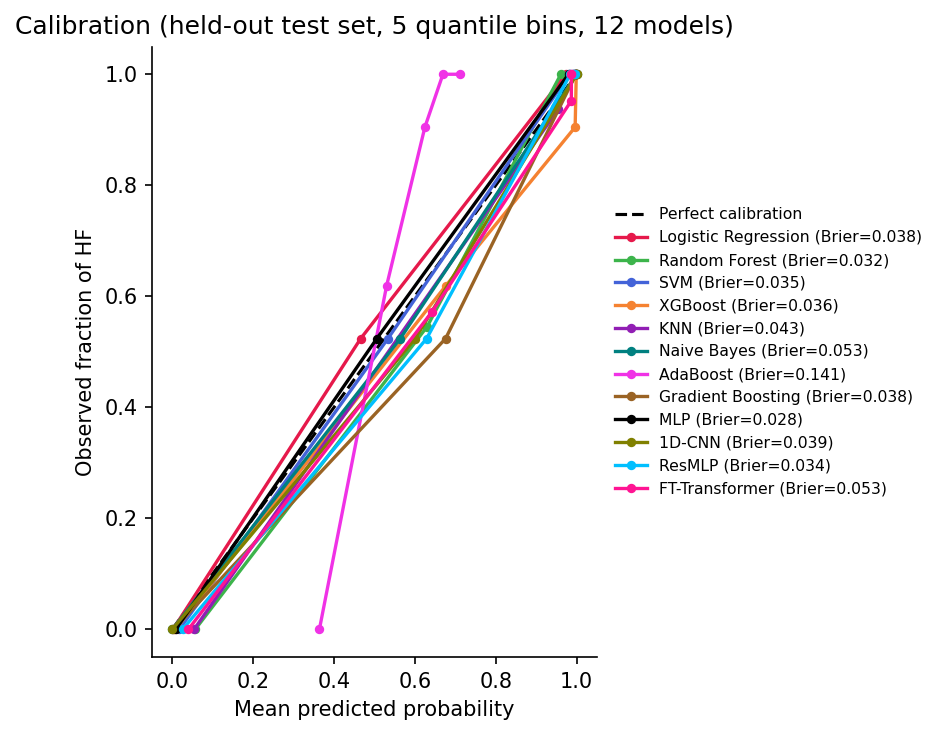

              Model  Brier_score
Logistic Regression       0.0380
      Random Forest       0.0325
                SVM       0.0347
            XGBoost       0.0362
                KNN       0.0434
        Naive Bayes       0.0529
           AdaBoost       0.1409
  Gradient Boosting       0.0376
                MLP       0.0281
             1D-CNN       0.0395
             ResMLP       0.0339
     FT-Transformer       0.0528


In [125]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score
plt.rcParams['svg.fonttype'] = 'none'

DEEP = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']
COLORS = ['#E6194B', '#3CB44B', '#4363D8', '#F58231', '#911EB4', '#008080',
          '#F032E6', '#9A6324', '#000000', '#808000', '#00BFFF', '#FF1493']
PAL = dict(zip(list(hf_models) + DEEP, COLORS))

def _dl_prob(name, epochs=60, lr=0.001):
    """Test-set probabilities of a DL model. If missing in dl_results, train it (DLX recipe) and store it."""
    try:
        return np.asarray(dl_results['Heart Failure'][name]['y_prob']).ravel()
    except Exception:
        pass
    print(f'{name}: y_prob not found in dl_results - training now ({epochs} epochs)...')
    sc = StandardScaler()
    Xtr = sc.fit_transform(np.asarray(hf_Xtr)).astype(np.float32)
    Xte = sc.transform(np.asarray(hf_Xte)).astype(np.float32)
    ytr = np.asarray(hf_ytr).astype(int)
    torch.manual_seed(42)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)),
                        batch_size=32, shuffle=True)
    model = dl_arch[name](Xtr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
    crit  = nn.BCELoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        prob = model(torch.tensor(Xte)).squeeze().numpy()
    dl_results.setdefault('Heart Failure', {}).setdefault(name, {})['y_prob'] = prob
    print(f'{name}: trained, test AUC = {roc_auc_score(np.asarray(hf_yte).astype(int), prob):.3f} (compare with Table S2)')
    return prob

def _get_probs():
    P = {n: hf_models[n].predict_proba(hf_Xte)[:, 1] for n in hf_models}
    for n in DEEP:
        P[n] = _dl_prob(n)
    return P

probs = _get_probs()
y = np.asarray(hf_yte).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Perfect calibration')
rows = []
for name, p in probs.items():
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=5, strategy='quantile')
    b = brier_score_loss(y, p)
    ax.plot(mean_pred, frac_pos, marker='o', ms=3.5, lw=1.6, color=PAL[name], label=f'{name} (Brier={b:.3f})')
    rows.append({'Model': name, 'Brier_score': round(b, 4)})
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed fraction of HF')
ax.set_title('Calibration (held-out test set, 5 quantile bins, 12 models)')
ax.legend(frameon=False, fontsize=7.5, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(SAVE / 'Calibration_HF.svg', format='svg', bbox_inches='tight')
plt.show()

pd.DataFrame(rows).to_csv(SAVE / 'Brier_scores_HF.csv', index=False)
print(pd.DataFrame(rows).to_string(index=False))

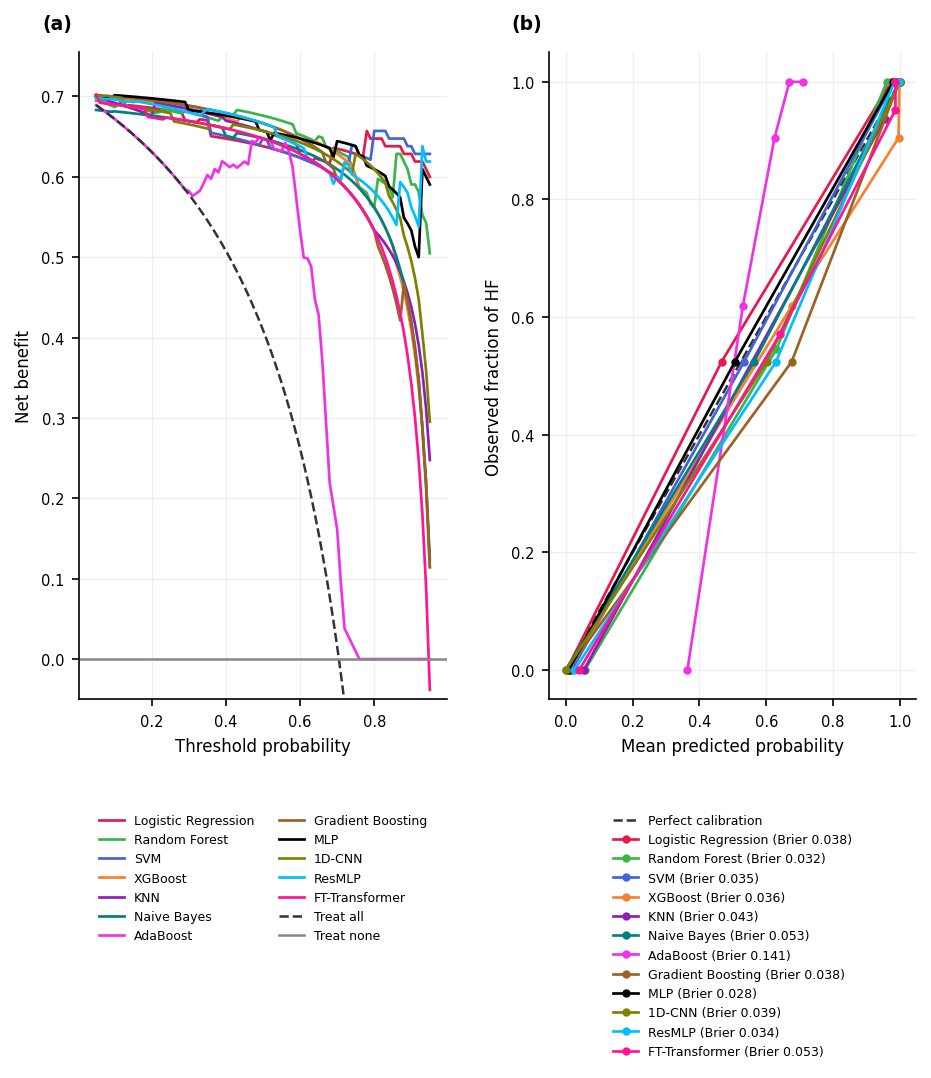

DCA + calibration saved (12 models, SVG + 300-dpi PNG)


In [126]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

DEEP = ['MLP', '1D-CNN', 'ResMLP', 'FT-Transformer']
COLORS = ['#E6194B', '#3CB44B', '#4363D8', '#F58231', '#911EB4', '#008080',
          '#F032E6', '#9A6324', '#000000', '#808000', '#00BFFF', '#FF1493']
PAL = dict(zip(list(hf_models) + DEEP, COLORS))

def _dl_prob(name, epochs=60, lr=0.001):
    """Test-set probabilities of a DL model. If missing in dl_results, train it (DLX recipe) and store it."""
    try:
        return np.asarray(dl_results['Heart Failure'][name]['y_prob']).ravel()
    except Exception:
        pass
    print(f'{name}: y_prob not found in dl_results - training now ({epochs} epochs)...')
    sc = StandardScaler()
    Xtr = sc.fit_transform(np.asarray(hf_Xtr)).astype(np.float32)
    Xte = sc.transform(np.asarray(hf_Xte)).astype(np.float32)
    ytr = np.asarray(hf_ytr).astype(int)
    torch.manual_seed(42)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)),
                        batch_size=32, shuffle=True)
    model = dl_arch[name](Xtr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
    crit  = nn.BCELoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        prob = model(torch.tensor(Xte)).squeeze().numpy()
    dl_results.setdefault('Heart Failure', {}).setdefault(name, {})['y_prob'] = prob
    print(f'[INFO] {name}: trained, test AUC = {roc_auc_score(np.asarray(hf_yte).astype(int), prob):.3f} (compare with Table S2)')
    return prob

y = np.asarray(hf_yte).astype(int); n = len(y); prev = y.mean()
probs = {m: hf_models[m].predict_proba(hf_Xte)[:, 1] for m in hf_models}
for m in DEEP:
    probs[m] = _dl_prob(m)

pts = np.arange(0.05, 0.96, 0.01)
def net_benefit(p, pt):
    pred = p >= pt
    return np.sum(pred & (y == 1)) / n - np.sum(pred & (y == 0)) / n * (pt / (1 - pt))

fig, (axA, axB) = plt.subplots(1, 2, figsize=(7.2, 5.6), gridspec_kw={'wspace': 0.28})


for m, p in probs.items():
    axA.plot(pts, [net_benefit(p, t) for t in pts], color=PAL[m], lw=1.3, label=m)
axA.plot(pts, [prev - (1 - prev) * t / (1 - t) for t in pts], color='#333333', ls='--', lw=1.2, label='Treat all')
axA.axhline(0, color='#888888', lw=1.2, label='Treat none')
axA.set_ylim(-0.05, prev + 0.05)
axA.set_xlabel('Threshold probability', fontsize=8); axA.set_ylabel('Net benefit', fontsize=8)
axA.legend(frameon=False, fontsize=6, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)


axB.plot([0, 1], [0, 1], color='#333333', ls='--', lw=1.2, label='Perfect calibration')
for m, p in probs.items():
    fp, mp = calibration_curve(y, p, n_bins=5, strategy='quantile')
    axB.plot(mp, fp, marker='o', ms=3, color=PAL[m], lw=1.3, label=f'{m} (Brier {brier_score_loss(y, p):.3f})')
axB.set_xlabel('Mean predicted probability', fontsize=8); axB.set_ylabel('Observed fraction of HF', fontsize=8)
axB.legend(frameon=False, fontsize=6, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=1)

for a, lab in zip((axA, axB), 'ab'):
    a.tick_params(labelsize=7)
    a.grid(color='#EEEEEE', lw=0.6); a.set_axisbelow(True)
    a.text(-0.02, 1.03, f'({lab})', transform=a.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='right')

plt.savefig(SAVE / 'DCA_Calibration_HF.svg', format='svg', bbox_inches='tight')
plt.savefig(SAVE / 'DCA_Calibration_HF.png', format='png', bbox_inches='tight', dpi=300)
plt.show()
print(f'DCA + calibration saved ({len(probs)} models, SVG + 300-dpi PNG)')

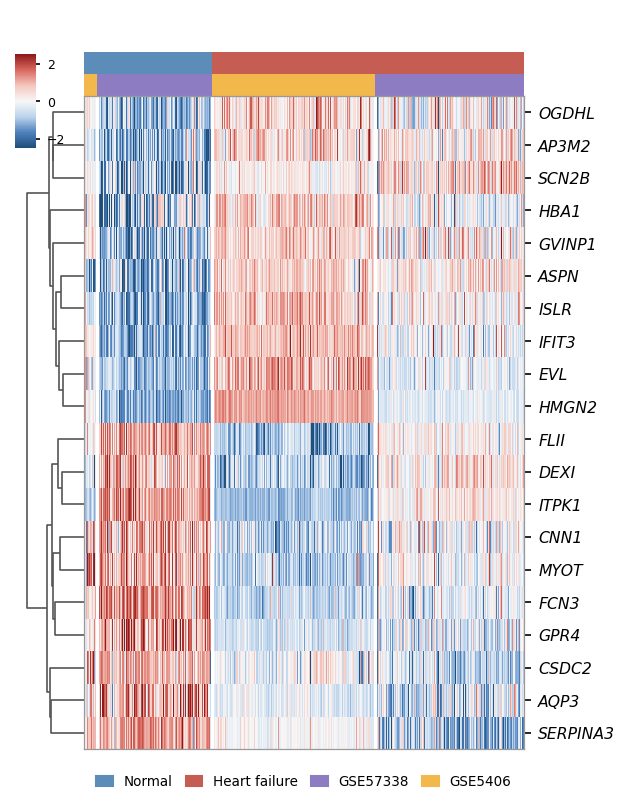

Heatmap saved (SVG + 300-dpi PNG)


In [127]:

from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams['svg.fonttype'] = 'none'

C_NORMAL, C_HF, C_C1, C_C2 = '#5B8DB8', '#C65D52', '#8E7CC3', '#F2B84B'
cmap = LinearSegmentedColormap.from_list(
    'hf_div', ['#1F4E79', '#4F81BD', '#BCD4EC', '#F7F7F7', '#F4C7BE', '#D9695F', '#8E1B1B'])

lab = np.asarray(heart_labels).astype(int)
cohort = np.array(['GSE57338'] * h1.shape[1] + ['GSE5406'] * h2.shape[1])
order = np.lexsort((cohort, lab))            
cc = [[C_HF if l == 1 else C_NORMAL for l in lab[order]],
      [C_C2 if c == 'GSE5406' else C_C1 for c in cohort[order]]]
data = heart_corrected.loc[hf_genes].iloc[:, order]

g = sns.clustermap(data, cmap=cmap, vmin=-2.5, vmax=2.5, center=0,
                   col_cluster=False, row_cluster=True,
                   col_colors=cc, xticklabels=False, yticklabels=True,
                   figsize=(4.6, 5.2), dendrogram_ratio=(0.12, 0.05),
                   cbar_pos=(0.02, 0.80, 0.03, 0.12),
                   tree_kws=dict(linewidths=0.8, colors='#555555'),
                   rasterized=True)
g.ax_heatmap.set_xlabel(''); g.ax_heatmap.set_ylabel('')
for t in g.ax_heatmap.get_yticklabels():
    t.set_fontsize(7.5); t.set_fontstyle('italic')
g.ax_cbar.tick_params(labelsize=6, length=2)


grp = [f'{l}-{c}' for l, c in zip(lab[order], cohort[order])]
for i in range(1, len(grp)):
    if grp[i] != grp[i - 1]:
        g.ax_heatmap.axvline(i, color='white', lw=1.6)
for sp in g.ax_heatmap.spines.values():
    sp.set_visible(True); sp.set_linewidth(0.6); sp.set_color('#999999')

handles = [Patch(color=C_NORMAL, label='Normal'), Patch(color=C_HF, label='Heart failure'),
           Patch(color=C_C1, label='GSE57338'), Patch(color=C_C2, label='GSE5406')]
g.ax_heatmap.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.02),
                    ncol=4, frameon=False, fontsize=6.5, handlelength=1.2, columnspacing=1.0)

plt.savefig(SAVE / 'Heatmap_20genes_HF.svg', format='svg', bbox_inches='tight', dpi=600)
plt.savefig(SAVE / 'Heatmap_20genes_HF.png', format='png', bbox_inches='tight', dpi=300)
plt.show()
print('Heatmap saved (SVG + 300-dpi PNG)')

Resuming: finished models = ['Logistic Regression', 'Random Forest', 'SVM', 'XGBoost', 'KNN', 'Naive Bayes', 'AdaBoost', 'Gradient Boosting']
  MLP: 100 permutations x 5 folds (this is slow)...
    MLP: 10/100 permutations, 1.6 min elapsed, about 14.3 min left
    MLP: 20/100 permutations, 3.2 min elapsed, about 12.7 min left
    MLP: 30/100 permutations, 4.8 min elapsed, about 11.1 min left
    MLP: 40/100 permutations, 6.3 min elapsed, about 9.5 min left
    MLP: 50/100 permutations, 7.9 min elapsed, about 7.9 min left
    MLP: 60/100 permutations, 9.4 min elapsed, about 6.3 min left
    MLP: 70/100 permutations, 11.0 min elapsed, about 4.7 min left
    MLP: 80/100 permutations, 12.6 min elapsed, about 3.1 min left
    MLP: 90/100 permutations, 14.1 min elapsed, about 1.6 min left
    MLP: 100/100 permutations, 15.7 min elapsed, about 0.0 min left
  MLP: observed CV AUC = 0.984, null mean = 0.498, p = 0.0099
  1D-CNN: 100 permutations x 5 folds (this is slow)...
    1D-CNN: 10/100 pe

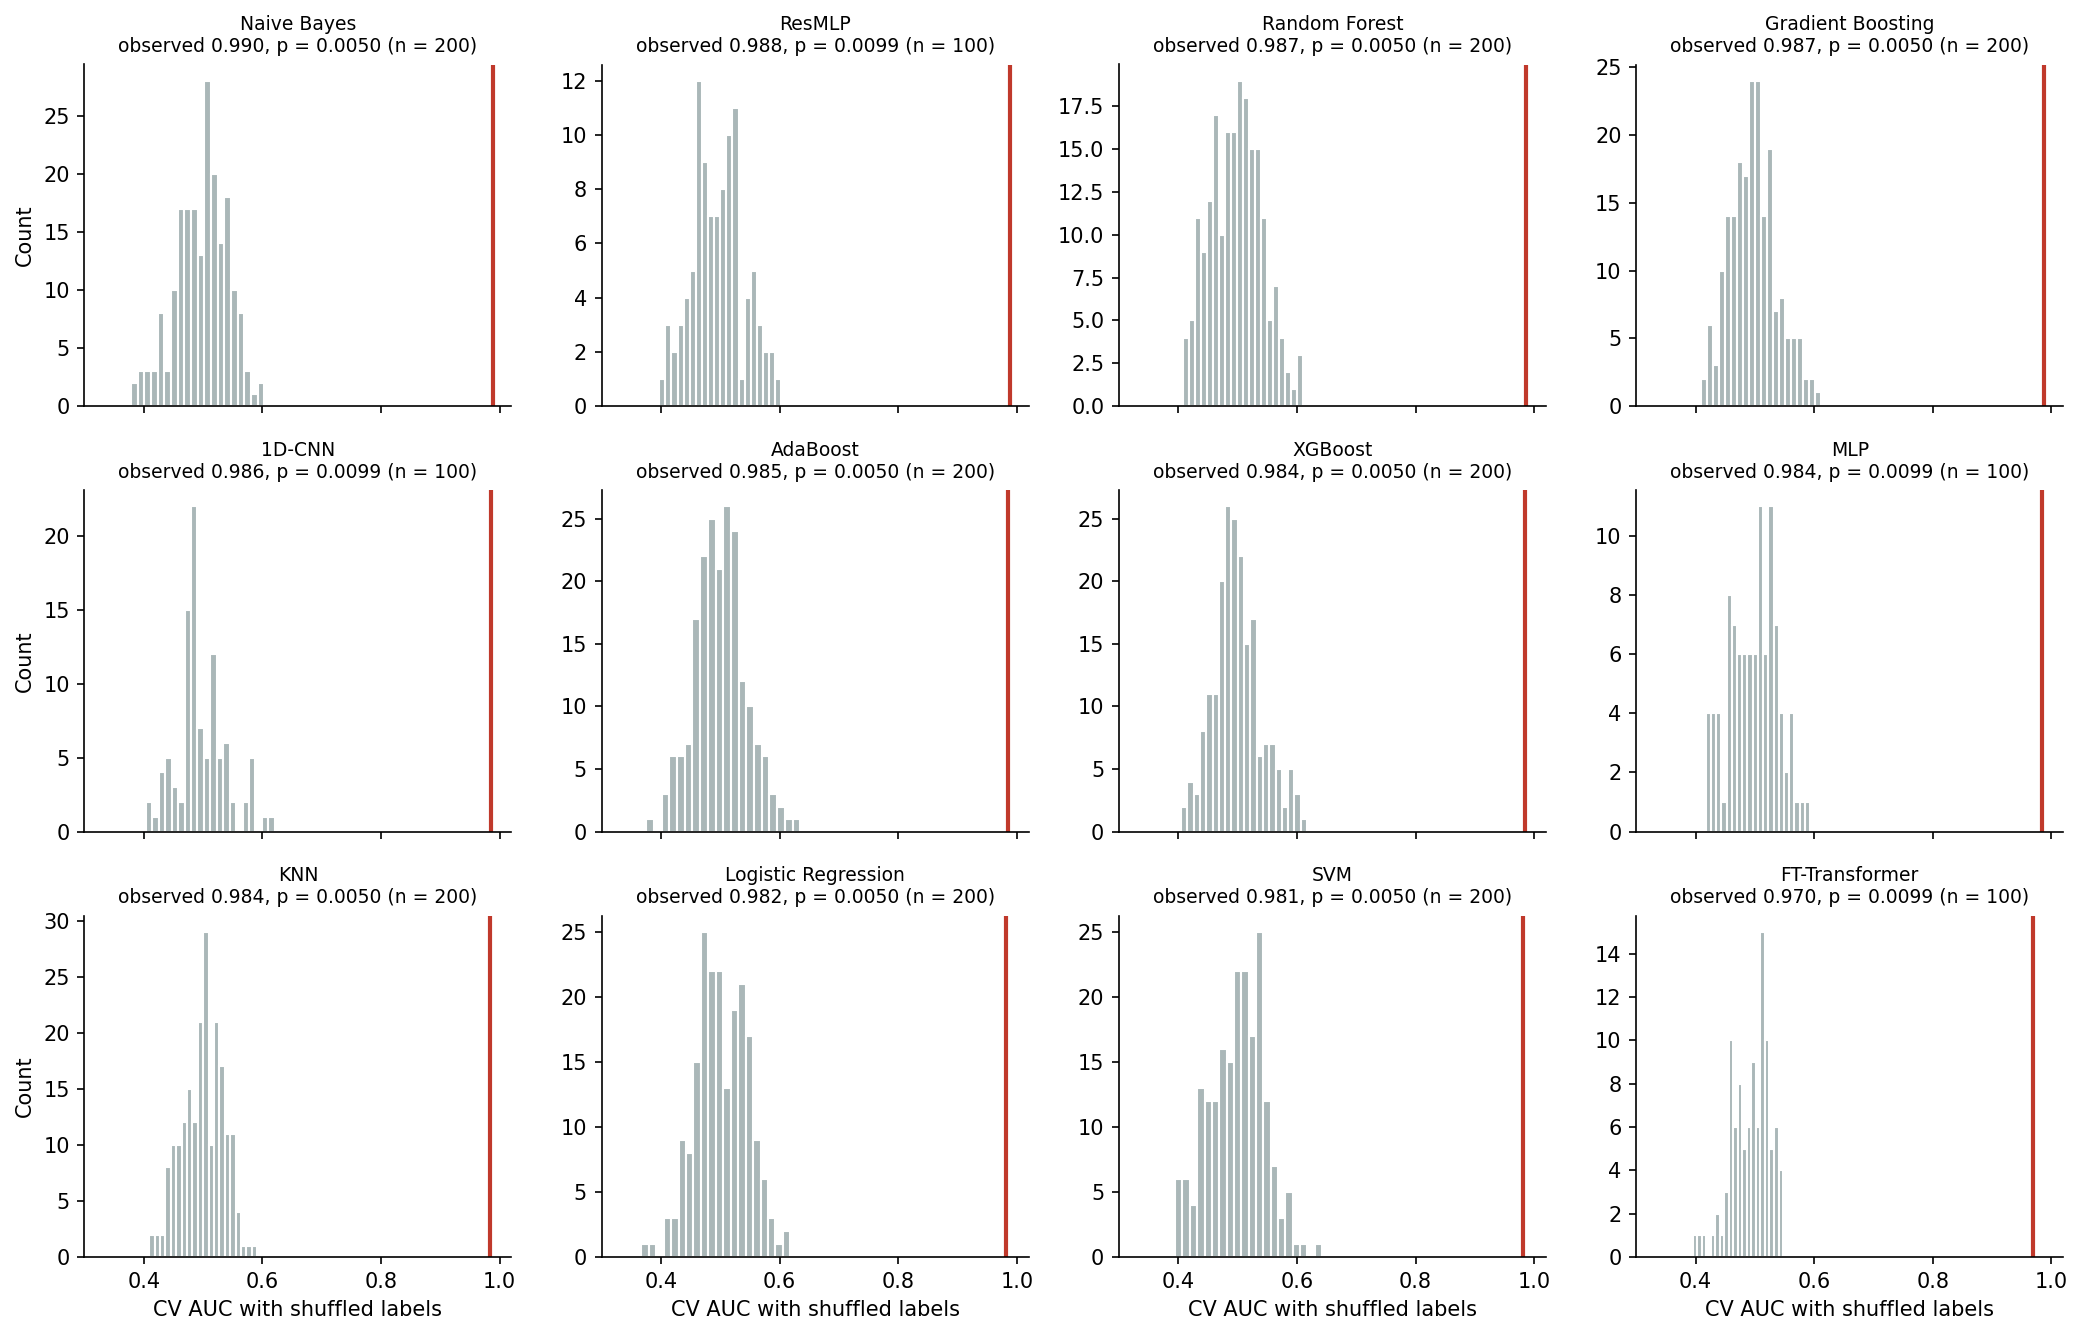

              Model          Type  N_permutations  Observed_CV_AUC  Null_mean  Null_SD  Null_max  p_value
        Naive Bayes  Classical ML             200           0.9897     0.4985   0.0437    0.6032   0.0050
             ResMLP Deep learning             100           0.9879     0.4964   0.0433    0.6026   0.0099
      Random Forest  Classical ML             200           0.9868     0.4974   0.0427    0.6095   0.0050
  Gradient Boosting  Classical ML             200           0.9867     0.4982   0.0395    0.6123   0.0050
             1D-CNN Deep learning             100           0.9855     0.4968   0.0418    0.6208   0.0099
           AdaBoost  Classical ML             200           0.9853     0.5006   0.0434    0.6348   0.0050
            XGBoost  Classical ML             200           0.9842     0.4999   0.0408    0.6170   0.0050
                MLP Deep learning             100           0.9842     0.4979   0.0401    0.5932   0.0099
                KNN  Classical ML             

In [128]:

import pickle, time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import permutation_test_score, StratifiedKFold
from sklearn.metrics import roc_auc_score

N_PERM_CLASSICAL = 200    
N_PERM_DL        = 100    

CKPT = SAVE / 'permutation_checkpoint.pkl'

X_all = heart_corrected[heart_train_cols].T[hf_genes].values      
y_all = np.asarray(hf_ytr).astype(int)
skf   = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def train_dl_auc(Xtr, ytr, Xva, yva, ModelClass, epochs=60, lr=0.001):
    """Same training recipe as train_dl (seed 42, Adam, StepLR, BCE, 60 epochs) but returns only the AUC."""
    torch.manual_seed(42)
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)
    Xva_t = torch.tensor(Xva, dtype=torch.float32)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)
    model = ModelClass(Xtr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
    crit  = nn.BCELoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        p = model(Xva_t).squeeze().numpy()
    return roc_auc_score(yva, p)

def dl_null(Arch, n_perm, name, seed=42):
    rng, null = np.random.RandomState(seed), []
    t0 = time.time()
    for i in range(n_perm):
        y_p = rng.permutation(y_all)
        aucs = []
        for tr, va in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_all, y_p):
            sc = StandardScaler()
            Xt = sc.fit_transform(X_all[tr]).astype(np.float32)
            Xv = sc.transform(X_all[va]).astype(np.float32)
            aucs.append(train_dl_auc(Xt, y_p[tr], Xv, y_p[va], Arch))
        null.append(np.mean(aucs))
        if (i + 1) % 10 == 0:
            el = time.time() - t0
            print(f'    {name}: {i + 1}/{n_perm} permutations, {el / 60:.1f} min elapsed, '
                  f'about {el / (i + 1) * (n_perm - i - 1) / 60:.1f} min left')
    return np.array(null)

results = pickle.load(open(CKPT, 'rb')) if CKPT.exists() else {}
if results:
    print(f'Resuming: finished models = {list(results)}')


for name, mdl in hf_models.items():
    if name in results:
        continue
    t0 = time.time()
    pipe = Pipeline([('sc', StandardScaler()), ('m', clone(mdl))])
    obs, null, pval = permutation_test_score(pipe, X_all, y_all, scoring='roc_auc', cv=skf,
                                             n_permutations=N_PERM_CLASSICAL, random_state=42, n_jobs=-1)
    results[name] = {'type': 'Classical ML', 'n_perm': N_PERM_CLASSICAL, 'obs': float(obs), 'null': np.asarray(null)}
    pickle.dump(results, open(CKPT, 'wb'))
    print(f'  {name}: observed CV AUC = {obs:.3f}, null mean = {np.mean(null):.3f}, p = {pval:.4f}  ({(time.time() - t0) / 60:.1f} min)')


for name, Arch in dl_arch.items():
    if name in results:
        continue
    print(f'  {name}: {N_PERM_DL} permutations x 5 folds (this is slow)...')
    null = dl_null(Arch, N_PERM_DL, name)
    obs  = float(dl_cv[name].mean())                         
    results[name] = {'type': 'Deep learning', 'n_perm': N_PERM_DL, 'obs': obs, 'null': null}
    pickle.dump(results, open(CKPT, 'wb'))
    pval = (np.sum(null >= obs) + 1) / (len(null) + 1)
    print(f'  {name}: observed CV AUC = {obs:.3f}, null mean = {null.mean():.3f}, p = {pval:.4f}')


rows = []
for name in list(hf_models) + list(dl_arch):
    r = results[name]; nl = r['null']
    rows.append({'Model': name, 'Type': r['type'], 'N_permutations': r['n_perm'],
                 'Observed_CV_AUC': round(r['obs'], 4), 'Null_mean': round(float(nl.mean()), 4),
                 'Null_SD': round(float(nl.std()), 4), 'Null_max': round(float(nl.max()), 4),
                 'p_value': round((np.sum(nl >= r['obs']) + 1) / (len(nl) + 1), 4)})
perm_df = pd.DataFrame(rows).sort_values('Observed_CV_AUC', ascending=False).reset_index(drop=True)
perm_df.to_csv(SAVE / 'Permutation_test_HF.csv', index=False)

plt.rcParams['svg.fonttype'] = 'none'
fig, axes = plt.subplots(3, 4, figsize=(14, 9), sharex=True)
for ax, name in zip(axes.ravel(), perm_df['Model']):
    r = results[name]; nl = r['null']
    ax.hist(nl, bins=20, color='#AAB7B8', edgecolor='white')
    ax.axvline(r['obs'], color='#C0392B', lw=2)
    pv = (np.sum(nl >= r['obs']) + 1) / (len(nl) + 1)
    ax.set_title(f'{name}\nobserved {r["obs"]:.3f}, p = {pv:.4f} (n = {r["n_perm"]})', fontsize=9)
    ax.set_xlim(0.3, 1.02)
for ax in axes[-1]:
    ax.set_xlabel('CV AUC with shuffled labels')
for ax in axes[:, 0]:
    ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(SAVE / 'Permutation_test_HF.svg', format='svg', bbox_inches='tight')
plt.show()

print(perm_df.to_string(index=False))
print('\n Permutation_test_HF.csv and Permutation_test_HF.svg saved (12 models)')

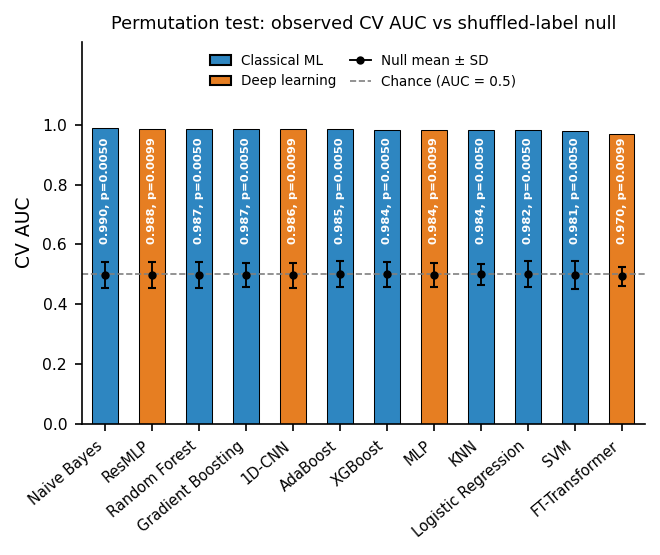

Permutation_test_HF_barchart.svg and Permutation_test_HF_barchart.png saved


In [129]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams['svg.fonttype'] = 'none'

df = perm_df.copy()                                   
type_color = {'Classical ML': '#2E86C1', 'Deep learning': '#E67E22'}
colors = df['Type'].map(type_color).fillna('#7F8C8D')
x = np.arange(len(df))

fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.bar(x, df['Observed_CV_AUC'], color=colors, edgecolor='black', linewidth=0.5, width=0.55)
ax.set_xlim(-0.5, len(df) - 0.5)
ax.errorbar(x, df['Null_mean'], yerr=df['Null_SD'], fmt='o', color='black',
            ms=3, capsize=2, lw=0.9, zorder=3)


for i, (o, p) in enumerate(zip(df['Observed_CV_AUC'], df['p_value'])):
    ax.text(i, 0.60, f'{o:.3f}, p={p:.4f}', rotation=90, ha='center', va='bottom',
            fontsize=5.5, color='white', fontweight='bold')

ax.axhline(0.5, ls='--', color='gray', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(df['Model'], rotation=40, ha='right', fontsize=7)
ax.tick_params(axis='y', labelsize=7.5)
ax.set_ylabel('CV AUC', fontsize=9)
ax.set_ylim(0, 1.28)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title('Permutation test: observed CV AUC vs shuffled-label null', fontsize=8.5)

handles = [Patch(facecolor=c, edgecolor='black', label=t)
           for t, c in type_color.items() if t in set(df['Type'])]
handles.append(Line2D([0], [0], marker='o', color='black', lw=0.9, ls='-', ms=3,
                      label='Null mean ± SD'))
handles.append(Line2D([0], [0], color='gray', ls='--', lw=0.8, label='Chance (AUC = 0.5)'))
ax.legend(handles=handles, loc='upper center', ncol=2, fontsize=6.5, frameon=False,
          columnspacing=1.0, handlelength=1.5)

plt.tight_layout()
plt.savefig(SAVE / 'Permutation_test_HF_barchart.svg', format='svg', bbox_inches='tight')
plt.savefig(SAVE / 'Permutation_test_HF_barchart.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print('Permutation_test_HF_barchart.svg and Permutation_test_HF_barchart.png saved')

  bootstrap 25/100
  bootstrap 50/100
  bootstrap 75/100
  bootstrap 100/100


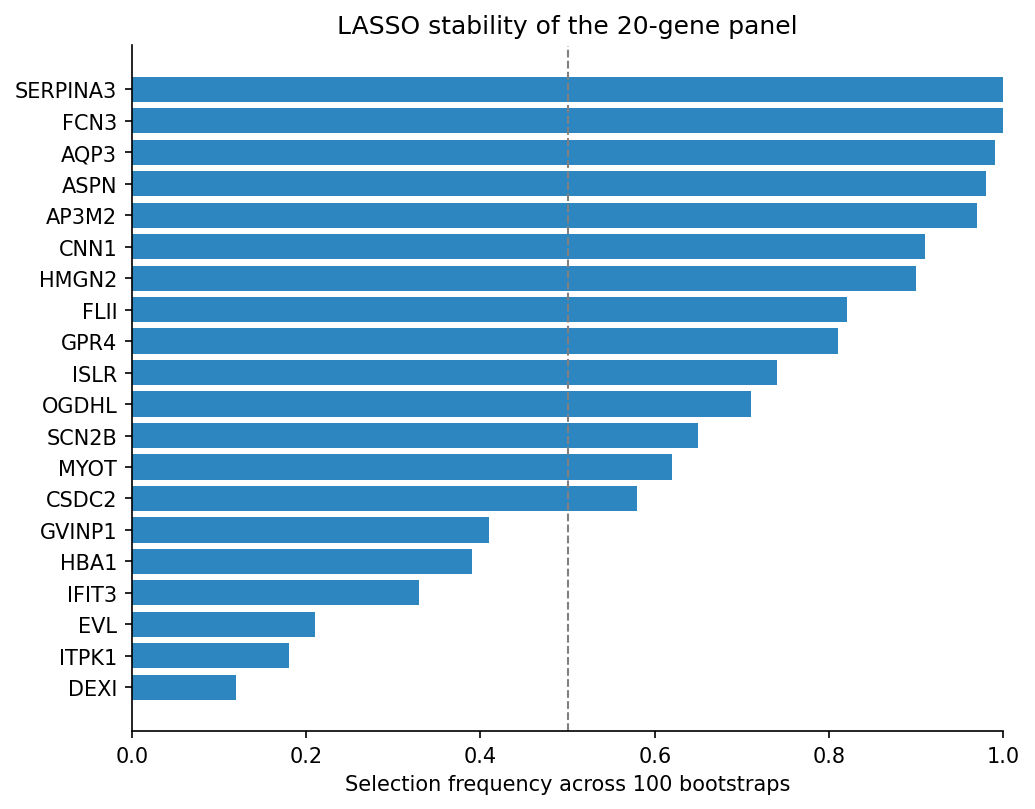

Mean genes selected per bootstrap: 21.4
Panel genes selected in >=50% of bootstraps: 14/20
    Gene  Selection_frequency
SERPINA3                 1.00
    FCN3                 1.00
    AQP3                 0.99
    ASPN                 0.98
   AP3M2                 0.97
    CNN1                 0.91
   HMGN2                 0.90
    FLII                 0.82
    GPR4                 0.81
    ISLR                 0.74
   OGDHL                 0.71
   SCN2B                 0.65
    MYOT                 0.62
   CSDC2                 0.58
  GVINP1                 0.41
    HBA1                 0.39
   IFIT3                 0.33
     EVL                 0.21
   ITPK1                 0.18
    DEXI                 0.12


In [130]:

import io, contextlib
from sklearn.utils import resample
from collections import Counter
plt.rcParams['svg.fonttype'] = 'none'

B = 100
y_tr = np.asarray(heart_ytr)
counts = Counter()
n_sel = []
for b in range(B):
    idx = resample(np.arange(len(y_tr)), replace=True, stratify=y_tr, random_state=b)
    with contextlib.redirect_stdout(io.StringIO()):
        genes_b, _, _, _ = lasso_select(heart_X_train.iloc[idx], y_tr[idx], 'boot')
    counts.update(genes_b)
    n_sel.append(len(genes_b))
    if (b + 1) % 25 == 0:
        print(f'  bootstrap {b + 1}/{B}')

stab = pd.DataFrame({'Gene': hf_genes,
                     'Selection_frequency': [counts.get(g_, 0) / B for g_ in hf_genes]}
                    ).sort_values('Selection_frequency', ascending=False)
stab.to_csv(SAVE / 'LASSO_stability_HF.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(stab['Gene'][::-1], stab['Selection_frequency'][::-1], color='#2E86C1')
ax.axvline(0.5, color='gray', ls='--', lw=1)
ax.set_xlim(0, 1)
ax.set_xlabel(f'Selection frequency across {B} bootstraps')
ax.set_title('LASSO stability of the 20-gene panel')
plt.tight_layout()
plt.savefig(SAVE / 'LASSO_stability_HF.svg', format='svg', bbox_inches='tight')
plt.show()

print(f'Mean genes selected per bootstrap: {np.mean(n_sel):.1f}')
print(f'Panel genes selected in >=50% of bootstraps: {(stab["Selection_frequency"] >= 0.5).sum()}/20')
print(stab.to_string(index=False))

  Logistic Regression: done (0.0 min)
  Random Forest: done (0.0 min)
  SVM: done (0.0 min)
  XGBoost: done (0.0 min)
  KNN: done (0.0 min)
  Naive Bayes: done (0.0 min)
  AdaBoost: done (0.1 min)
  Gradient Boosting: done (0.1 min)
  MLP: done (0.6 min)
  1D-CNN: done (1.4 min)
  ResMLP: done (0.8 min)
  FT-Transformer: done (2.3 min)


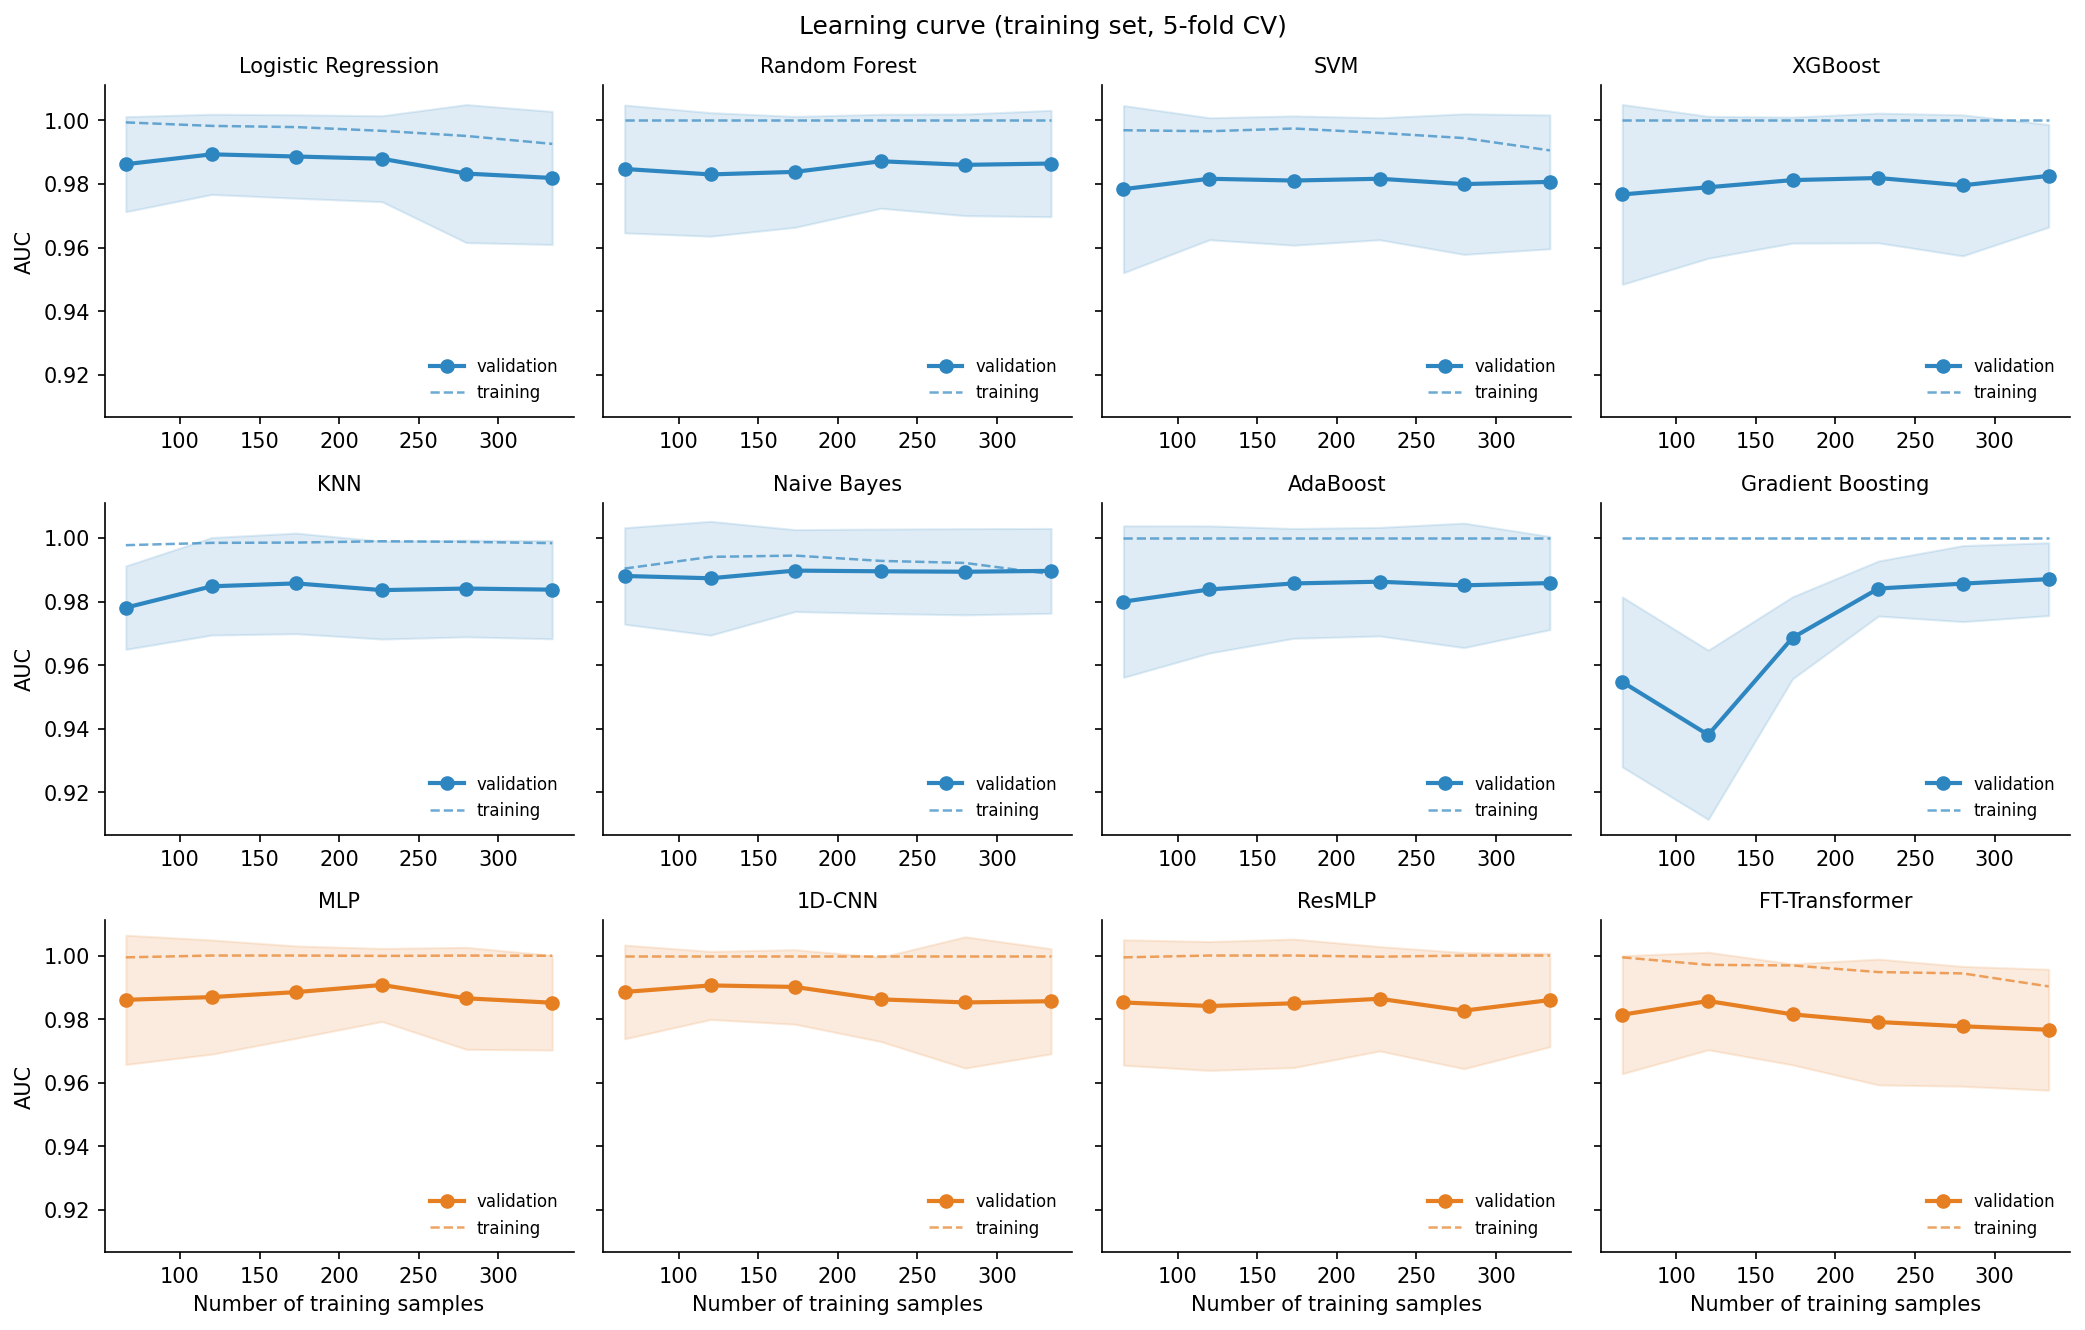

              Model          Type  Train_size  CV_AUC_mean  CV_AUC_std
Logistic Regression  Classical ML          66       0.9862      0.0149
Logistic Regression  Classical ML         120       0.9893      0.0126
Logistic Regression  Classical ML         173       0.9886      0.0131
Logistic Regression  Classical ML         227       0.9879      0.0135
Logistic Regression  Classical ML         280       0.9833      0.0217
Logistic Regression  Classical ML         334       0.9819      0.0209
      Random Forest  Classical ML          66       0.9847      0.0201
      Random Forest  Classical ML         120       0.9830      0.0194
      Random Forest  Classical ML         173       0.9838      0.0175
      Random Forest  Classical ML         227       0.9872      0.0148
      Random Forest  Classical ML         280       0.9860      0.0160
      Random Forest  Classical ML         334       0.9864      0.0167
                SVM  Classical ML          66       0.9784      0.0263
      

In [131]:

import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import clone
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
plt.rcParams['svg.fonttype'] = 'none'

X_lc = np.asarray(hf_Xtr)
y_lc = np.asarray(hf_ytr).astype(int)
fracs = np.linspace(0.2, 1.0, 6)
skf_lc = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def dl_fit_predict(Arch, Xtr, ytr, Xev_list, epochs=60, lr=0.001):
    """Same recipe as N4 (seed 42, Adam, StepLR, BCE, 60 epochs); returns predictions for each array in Xev_list."""
    torch.manual_seed(42)
    Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.float32).unsqueeze(1)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=32, shuffle=True)
    model = Arch(Xtr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=20, gamma=0.5)
    crit  = nn.BCELoss()
    model.train()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb), yb).backward()
            opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        return [model(torch.tensor(Xe, dtype=torch.float32)).squeeze().numpy() for Xe in Xev_list]

def dl_learning_curve(Arch):
    rng = np.random.RandomState(42)
    sizes_out, tr_sc, va_sc = None, [], []
    for tr, va in skf_lc.split(X_lc, y_lc):
        tr = rng.permutation(tr)
        sizes = np.maximum((fracs * len(tr)).astype(int), 2)
        if sizes_out is None:
            sizes_out = sizes
        t_row, v_row = [], []
        for n in sizes:
            sub = tr[:n]
            sc = StandardScaler()
            Xt = sc.fit_transform(X_lc[sub]).astype(np.float32)
            Xv = sc.transform(X_lc[va]).astype(np.float32)
            p_tr, p_va = dl_fit_predict(Arch, Xt, y_lc[sub], [Xt, Xv])
            t_row.append(roc_auc_score(y_lc[sub], p_tr))
            v_row.append(roc_auc_score(y_lc[va], p_va))
        tr_sc.append(t_row); va_sc.append(v_row)
    return sizes_out, np.array(tr_sc).T, np.array(va_sc).T      # shape (n_sizes, 5)

all_names = list(hf_models) + list(dl_arch)
type_color = {'Classical ML': '#2E86C1', 'Deep learning': '#E67E22'}

fig, axes = plt.subplots(3, 4, figsize=(14, 9), sharey=True)
lc_rows = []
for ax, name in zip(axes.ravel(), all_names):
    t0 = time.time()
    if name in hf_models:
        mtype = 'Classical ML'
        sizes, tr_sc, va_sc = learning_curve(
            clone(hf_models[name]), X_lc, y_lc,
            train_sizes=fracs, cv=skf_lc,
            scoring='roc_auc', n_jobs=-1, shuffle=True, random_state=42)
    else:
        mtype = 'Deep learning'
        sizes, tr_sc, va_sc = dl_learning_curve(dl_arch[name])
    col = type_color[mtype]
    m, s = va_sc.mean(axis=1), va_sc.std(axis=1)
    ax.plot(sizes, m, marker='o', lw=2, color=col, label='validation')
    ax.fill_between(sizes, m - s, m + s, color=col, alpha=0.15)
    ax.plot(sizes, tr_sc.mean(axis=1), ls='--', lw=1.2, color=col, alpha=0.7, label='training')
    ax.set_title(name, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc='lower right')
    for sz, mm, ss in zip(sizes, m, s):
        lc_rows.append({'Model': name, 'Type': mtype, 'Train_size': int(sz),
                        'CV_AUC_mean': round(mm, 4), 'CV_AUC_std': round(ss, 4)})
    print(f'  {name}: done ({(time.time() - t0) / 60:.1f} min)')
for ax in axes[-1]:
    ax.set_xlabel('Number of training samples')
for ax in axes[:, 0]:
    ax.set_ylabel('AUC')
fig.suptitle('Learning curve (training set, 5-fold CV)', fontsize=12)
plt.tight_layout()
plt.savefig(SAVE / 'Learning_curve_HF.svg', format='svg', bbox_inches='tight')
plt.show()

pd.DataFrame(lc_rows).to_csv(SAVE / 'Learning_curve_HF.csv', index=False)
print(pd.DataFrame(lc_rows).to_string(index=False))

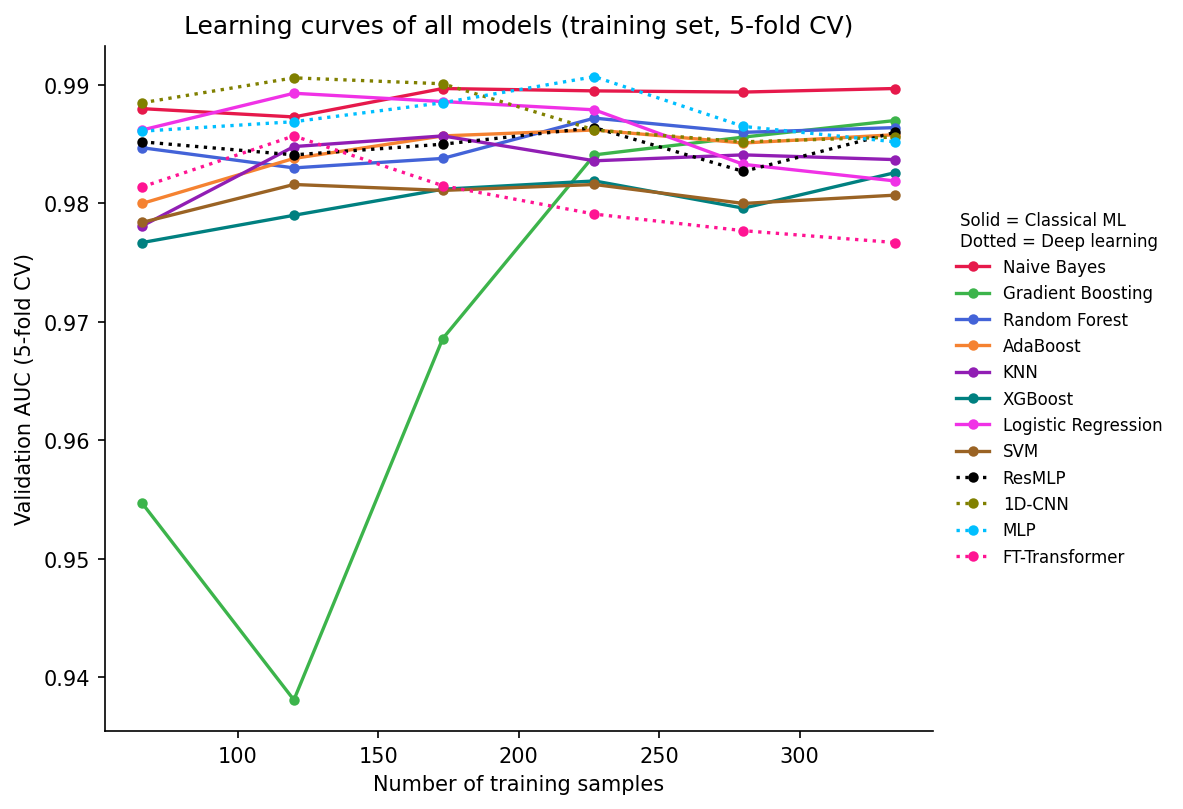

Learning_curve_HF_combined.svg and Learning_curve_HF_combined.png saved


In [132]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

SHOW_BAND = False                      

lc = pd.read_csv(SAVE / 'Learning_curve_HF.csv')


last = lc.sort_values('Train_size').groupby('Model').tail(1).sort_values('CV_AUC_mean', ascending=False)
classical = [m for m in last['Model'] if lc.loc[lc['Model'] == m, 'Type'].iloc[0] == 'Classical ML']
deep      = [m for m in last['Model'] if lc.loc[lc['Model'] == m, 'Type'].iloc[0] == 'Deep learning']

distinct_colors = ['#E6194B', '#3CB44B', '#4363D8', '#F58231', '#911EB4', '#008080',
                   '#F032E6', '#9A6324', '#000000', '#808000', '#00BFFF', '#FF1493']
col_map = dict(zip(classical + deep, distinct_colors))

fig, ax = plt.subplots(figsize=(8, 5.5))
for name in classical + deep:
    d = lc[lc['Model'] == name].sort_values('Train_size')
    ls = '-' if name in classical else ':'
    ax.plot(d['Train_size'], d['CV_AUC_mean'], marker='o', ms=4, lw=1.6, ls=ls,
            color=col_map[name], label=name)
    if SHOW_BAND:
        ax.fill_between(d['Train_size'], d['CV_AUC_mean'] - d['CV_AUC_std'],
                        d['CV_AUC_mean'] + d['CV_AUC_std'], color=col_map[name], alpha=0.08)

ax.set_xlabel('Number of training samples')
ax.set_ylabel('Validation AUC (5-fold CV)')
ax.set_title('Learning curves of all models (training set, 5-fold CV)')
ax.legend(frameon=False, fontsize=8, ncol=1, loc='center left', bbox_to_anchor=(1.01, 0.5),
          title='Solid = Classical ML\nDotted = Deep learning', title_fontsize=8)
plt.tight_layout()
plt.savefig(SAVE / 'Learning_curve_HF_combined.svg', format='svg', bbox_inches='tight')
plt.savefig(SAVE / 'Learning_curve_HF_combined.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

print('Learning_curve_HF_combined.svg and Learning_curve_HF_combined.png saved')

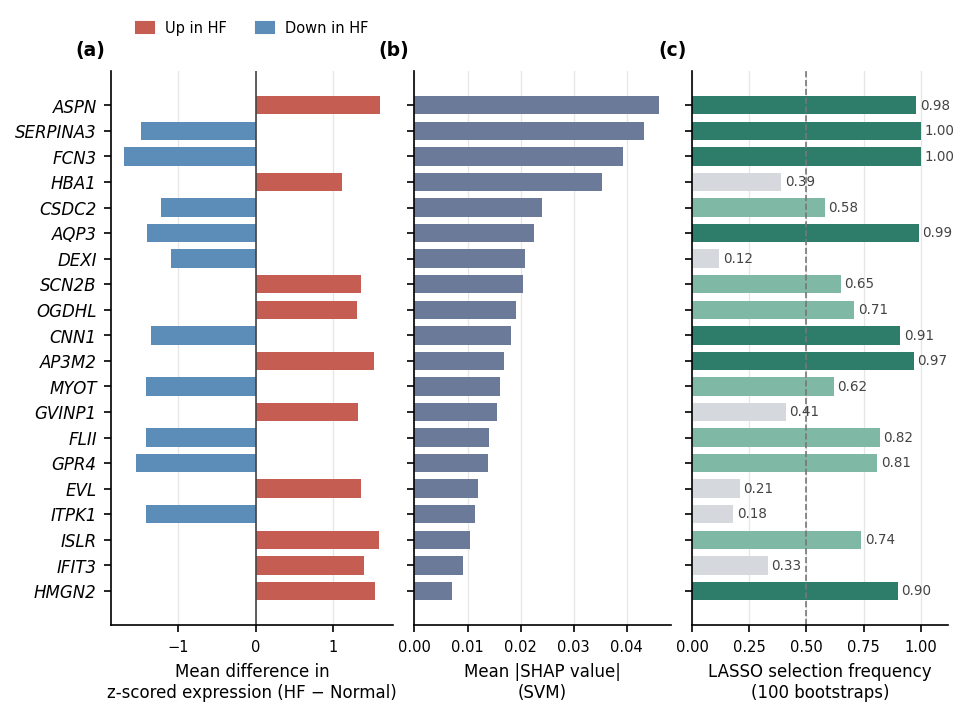

Panel overview saved (SVG + 300-dpi PNG)


In [133]:

from pathlib import Path
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

C_UP, C_DOWN, C_SHAP = '#C65D52', '#5B8DB8', '#6B7A99'
shap = pd.read_csv(SAVE / 'hf_shap_importance.csv').set_index('Gene')['SHAP']
deg  = pd.read_csv(SAVE / 'heart_DEG_results.csv', index_col=0)
genes = list(shap.sort_values(ascending=False).index)          # top = most important
lfc = deg.loc[genes, 'log2FC']
stab_file = SAVE / 'LASSO_stability_HF.csv'
stab = (pd.read_csv(stab_file).set_index('Gene')['Selection_frequency'].reindex(genes)
        if stab_file.exists() else None)

n_pan = 3 if stab is not None else 2
fig, axes = plt.subplots(1, n_pan, figsize=(7.2, 4.8), sharey=True,
                         gridspec_kw={'wspace': 0.08, 'width_ratios': [1.1, 1, 1][:n_pan]})
y = np.arange(len(genes))[::-1]

ax = axes[0]
ax.barh(y, lfc.values, color=[C_UP if v > 0 else C_DOWN for v in lfc], height=0.72)
ax.axvline(0, color='#444444', lw=0.8)
ax.set_xlabel('Mean difference in\nz-scored expression (HF − Normal)', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(genes, fontsize=8, fontstyle='italic')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_UP), plt.Rectangle((0, 0), 1, 1, color=C_DOWN)],
          labels=['Up in HF', 'Down in HF'], frameon=False, fontsize=7,
          loc='lower center', bbox_to_anchor=(0.5, 1.04), ncol=2, handlelength=1.2)

ax = axes[1]
ax.barh(y, shap.loc[genes].values, color=C_SHAP, height=0.72)
ax.set_xlabel('Mean |SHAP value|\n(SVM)', fontsize=8)

if stab is not None:
    ax = axes[2]
    cols = ['#2E7D6B' if v >= 0.9 else '#7FB8A4' if v >= 0.5 else '#D5D9DD' for v in stab]
    ax.barh(y, stab.values, color=cols, height=0.72)
    ax.axvline(0.5, color='#777777', ls='--', lw=0.8)
    ax.set_xlim(0, 1.12)
    for yi, v in zip(y, stab.values):
        ax.text(v + 0.015, yi, f'{v:.2f}', va='center', fontsize=6.5, color='#444444')
    ax.set_xlabel('LASSO selection frequency\n(100 bootstraps)', fontsize=8)

for a, lab in zip(axes, 'abc'):
    a.tick_params(axis='x', labelsize=7)
    a.grid(axis='x', color='#E6E6E6', lw=0.6); a.set_axisbelow(True)
    a.text(-0.02, 1.02, f'({lab})', transform=a.transAxes, fontsize=9,
           fontweight='bold', va='bottom', ha='right')

plt.savefig(SAVE / 'Panel_overview_HF.svg', format='svg', bbox_inches='tight')
plt.savefig(SAVE / 'Panel_overview_HF.png', format='png', bbox_inches='tight', dpi=300)
plt.show()
print('Panel overview saved (SVG + 300-dpi PNG)')

In [143]:

import zipfile, os

zip_path = SAVE / 'PROCESSED_DATA.zip'

print('Zipping processed data...')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    
    
    for f in SAVE.glob('*.pkl'):
        z.write(f, f.name)
        print(f'{f.name}')
    
   
    for f in SAVE.glob('*.npy'):
        z.write(f, f.name)
        print(f'{f.name}')
    
    
    for f in SAVE.glob('*.csv'):
        z.write(f, f.name)
        print(f'{f.name}')

print(f'\n ZIP created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path)/1024/1024:.2f} MB')


print('\n Files inside ZIP')
with zipfile.ZipFile(zip_path, 'r') as z:
    for name in sorted(z.namelist()):
        size = z.getinfo(name).file_size / 1024
        print(f'  {name:<45} {size:>8.1f} KB')

from IPython.display import FileLink, display
display(FileLink('PROCESSED_DATA.zip'))

Zipping processed data...
permutation_checkpoint.pkl
heart_corrected.pkl
heart_labels.npy
hf_genes.npy
CV_AUC_summary_12models.csv
SHAP_comparison_3models_agreement.csv
HF_test_AUC_per_dataset.csv
KEGG_results_HF.csv
Friedman_mean_ranks_12models.csv
DCA_HF_values.csv
SHAP_top20_per_model.csv
WGCNA_soft_threshold.csv
LASSO_stability_HF.csv
Learning_curve_HF.csv
Permutation_test_HF.csv
hf_shap_importance.csv
Nemenyi_pairwise_12models.csv
Hub_gene_validation_summary.csv
statistical_validation_12models.csv
Nemenyi_pvalues_12models.csv
DL_summary.csv
external_validation_multimodel.csv
SHAP_comparison_3models.csv
external_validation_9models_supp.csv
bootstrap_CI_all_models.csv
DL_4models_CV_and_test.csv
external_validation_12models_all.csv
CV_fold_AUCs_12models.csv
WGCNA_module_trait.csv
external_validation_results.csv
Brier_scores_HF_12models.csv
HeartFailure_ML_results.csv
PR_AUC_values_HF_12models.csv
statistical_validation.csv
heart_DEG_results.csv
HF_12models_master_table.csv
CV_AUC_sum

/kaggle/working/PROCESSED_DATA.zip

In [144]:

import zipfile
import os

zip_path = SAVE / 'HEART_ALL_RESULTS.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for ext in ['*.svg', '*.png', '*.csv', '*.pdf']:
        for f in SAVE.glob(ext):
            z.write(f, f.name)
            print(f'{f.name}')

print(f'\n ZIP created: {zip_path}')



from IPython.display import FileLink, display
display(FileLink('HEART_ALL_RESULTS.zip'))


PR_AUC_curves_HF.svg
Learning_curve_HF.svg
SHAP_beeswarm_HF.svg
Immune_Infiltration_HF.svg
Hub_gene_expression_all.svg
external_validation_HF.svg
external_validation_HF_Naive_Bayes.svg
Threshold_Tuning_HF.svg
ROC_curves_HF_all10.svg
Panel_overview_HF.svg
Confusion_Matrix_HF.svg
DCA_Calibration_HF.svg
GO_BP_enrichment_HF.svg
ROC_curves_HF.svg
9models_panel.svg
Calibration_HF.svg
Learning_curve_HF_combined.svg
DL_AUC_comparison_HF.svg
ROC_curves_HF_all12.svg
KEGG_enrichment_HF.svg
DL_ROC_curves_HF.svg
PCA_before_after_HF.svg
DCA_HF.svg
Hub_gene_ROC_all.svg
Heatmap_20genes_HF.svg
external_validation_HF_Random_Forest.svg
Nemenyi_heatmap_12models.svg
main 3models panel.svg
Diagnostic_model_ROC.svg
SHAP_comparison_3models.svg
external_validation_HF_SVM.svg
Permutation_test_HF_barchart.svg
LASSO_stability_HF.svg
Permutation_test_HF.svg
PR_AUC_curves_HF_12models.svg
WGCNA_combined_figure.svg
main 3models panel.png
Permutation_test_HF_barchart.png
Learning_curve_HF_combined.png
WGCNA_combined_f

/kaggle/working/HEART_ALL_RESULTS.zip